>>> Running analysis on cuda:2 with 300 sequences per threshold.
Done: Threshold x=0.1
Done: Threshold x=0.2
Done: Threshold x=0.3
Done: Threshold x=0.4
Done: Threshold x=0.5
Done: Threshold x=0.6
Done: Threshold x=0.7
Done: Threshold x=0.8
Done: Threshold x=0.9


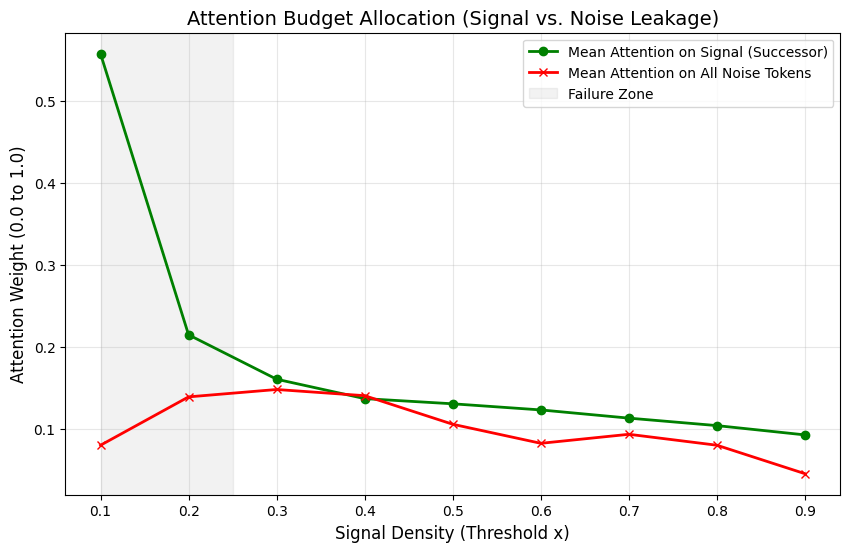

In [10]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,
    'seq_len': 200,
    'attn_dim': 64,
    # SET TO GPU 2 AS REQUESTED
    'device': 'cuda:2' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_2',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'num_test_seqs': 300  # Reduced from 2000
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITION ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_tracked_test_data(num_samples, threshold_x):
    x_data, ruled_mask = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq, is_ruled = [], []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
                is_ruled.append(True)
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
                is_ruled.append(False)
            seq.append(token)
        x_data.append(seq[:-1])
        ruled_mask.append(is_ruled[1:]) 
    return torch.tensor(x_data), torch.tensor(ruled_mask)

# --- 4. ANALYSIS ---
def run_attention_diffusion_analysis():
    print(f">>> Running analysis on {CONFIG['device']} with {CONFIG['num_test_seqs']} sequences per threshold.")
    final_stats = {}

    for x in CONFIG['thresholds']:
        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth")
        if not os.path.exists(model_path):
            continue

        # Build and load weights
        model = DisentangledTransformer().to(CONFIG['device'])
        state_dict = torch.load(model_path, map_location=CONFIG['device'])
        model.load_state_dict(state_dict)
        model.eval()

        signal_attn_vals = []
        noise_attn_vals = []

        # Generate fresh test data for this run
        tx, mask = generate_tracked_test_data(CONFIG['num_test_seqs'], x)
        tx = tx.to(CONFIG['device'])

        for b in range(tx.shape[0]):
            with torch.no_grad():
                _, attns = model(tx[b].unsqueeze(0))
                l2_attn = attns[1].squeeze(0) 

            local_history = {tid: [] for tid in range(CONFIG['vocab_set1'])}
            seq_cpu = tx[b].cpu()

            for t in range(CONFIG['seq_len']):
                token = seq_cpu[t].item()
                
                # Check if it's a signal token and part of a Markov transition
                if token < CONFIG['vocab_set1'] and mask[b, t]:
                    if local_history[token]:
                        target_idx = local_history[token][-1] + 1
                        
                        if target_idx < t:
                            # 1. Attention to the Signal (The Successor)
                            signal_attn_vals.append(l2_attn[t, target_idx].item())
                            
                            # 2. Attention to Noise Subspace (IDs 10-19)
                            noise_mask = (seq_cpu >= 10).float()
                            noise_mask[t:] = 0 
                            noise_sum = (l2_attn[t].cpu() * noise_mask).sum().item()
                            noise_attn_vals.append(noise_sum)

                    local_history[token].append(t)

        final_stats[x] = {
            'signal': np.mean(signal_attn_vals) if signal_attn_vals else 0,
            'noise': np.mean(noise_attn_vals) if noise_attn_vals else 0
        }
        print(f"Done: Threshold x={x}")

    return final_stats

# --- 5. PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    sig = [stats[x]['signal'] for x in x_vals]
    noi = [stats[x]['noise'] for x in x_vals]

    plt.figure(figsize=(10, 6))
    plt.plot(x_vals, sig, 'g-o', label='Mean Attention on Signal (Successor)', linewidth=2)
    plt.plot(x_vals, noi, 'r-x', label='Mean Attention on All Noise Tokens', linewidth=2)
    
    plt.title("Attention Budget Allocation (Signal vs. Noise Leakage)", fontsize=14)
    plt.xlabel("Signal Density (Threshold x)", fontsize=12)
    plt.ylabel("Attention Weight (0.0 to 1.0)", fontsize=12)
    plt.axvspan(0.1, 0.25, color='gray', alpha=0.1, label='Failure Zone')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.savefig(f"{CONFIG['output_dir']}/attn_diffusion_gpu2.png")
    plt.show()

if __name__ == "__main__":
    stats = run_attention_diffusion_analysis()
    plot_results(stats)

In [1]:
!nvidia-smi

Mon Mar 23 23:14:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.45.04              Driver Version: 595.45.04      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          Off |   00000000:01:01.0 Off |                    0 |
| N/A   65C    P0            293W /  300W |   55989MiB /  81920MiB |    100%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

>>> Running Layer 1 Analysis on cuda:3 (1000 seqs per threshold)


Evaluating x=0.9: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 285.30it/s]


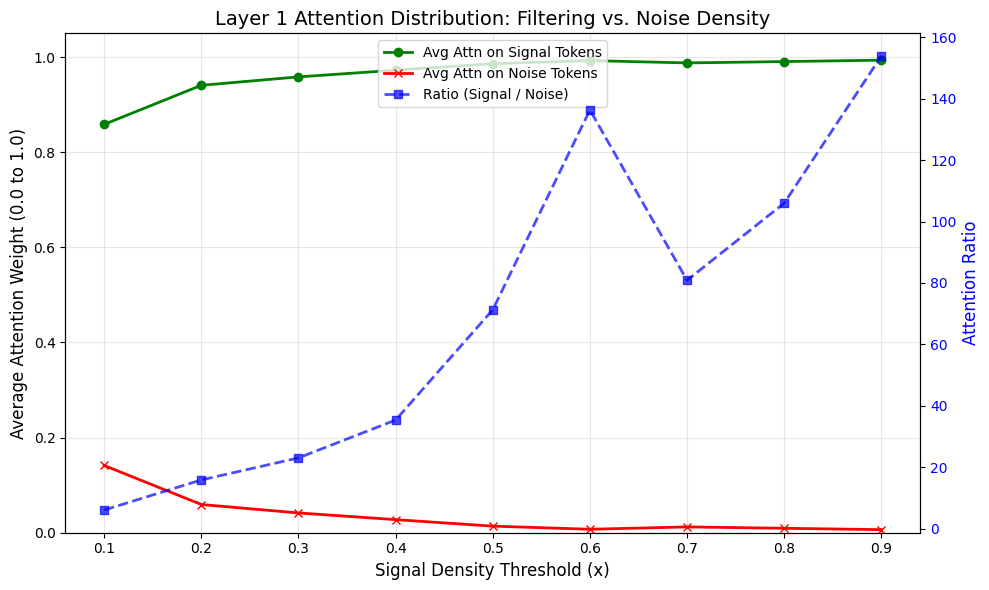

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal
    'seq_len': 200,
    'attn_dim': 64,
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu', # Targeting GPU 3
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_3',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'num_test_seqs': 1000,
    'batch_size': 250       # Process in batches to prevent OOM
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITION ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        # Returning Layer 1 and Layer 2 attention maps
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data = []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
    return torch.tensor(x_data)

# --- 4. LAYER 1 GLOBAL ATTENTION ANALYSIS ---
def run_layer1_attention_distribution():
    print(f">>> Running Layer 1 Analysis on {CONFIG['device']} ({CONFIG['num_test_seqs']} seqs per threshold)")
    final_stats = {}

    for x in CONFIG['thresholds']:
        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth")
        if not os.path.exists(model_path):
            print(f"Skipping x={x}: File not found.")
            continue

        model = DisentangledTransformer().to(CONFIG['device'])
        model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
        model.eval()

        # Generate data and setup DataLoader for batching
        tx = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        loader = torch.utils.data.DataLoader(tx, batch_size=CONFIG['batch_size'], shuffle=False)

        total_signal_attn = 0.0
        total_noise_attn = 0.0
        total_tokens = 0

        for batch in tqdm(loader, desc=f"Evaluating x={x}"):
            batch = batch.to(CONFIG['device'])
            B, T = batch.shape

            with torch.no_grad():
                _, attns = model(batch)
                l1_attn = attns[0] # Layer 1 Attention Map: Shape [B, T, T] (Queries, Keys)

            # Create Masks for the Keys (What the model is looking AT)
            # Shape: [B, 1, T] so it broadcasts across all T Queries
            is_signal_key = (batch < CONFIG['vocab_set1']).float().unsqueeze(1)
            is_noise_key = (batch >= CONFIG['vocab_set1']).float().unsqueeze(1)

            # Multiply attention map by masks and sum over the Key dimension (dim=-1)
            # This gives how much attention each query token paid to signals vs noise
            attn_to_signal = (l1_attn * is_signal_key).sum(dim=-1) # Shape: [B, T]
            attn_to_noise = (l1_attn * is_noise_key).sum(dim=-1)   # Shape: [B, T]

            total_signal_attn += attn_to_signal.sum().item()
            total_noise_attn += attn_to_noise.sum().item()
            total_tokens += (B * T)

        # Average over all sequences and all tokens
        avg_signal = total_signal_attn / total_tokens
        avg_noise = total_noise_attn / total_tokens
        ratio = avg_signal / avg_noise if avg_noise > 0 else float('inf')

        final_stats[x] = {
            'signal_avg': avg_signal,
            'noise_avg': avg_noise,
            'ratio': ratio
        }
        
        # Free memory aggressively to keep GPU 3 clean
        del model, tx, loader
        torch.cuda.empty_cache()

    return final_stats

# --- 5. PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    sig = [stats[x]['signal_avg'] for x in x_vals]
    noi = [stats[x]['noise_avg'] for x in x_vals]
    ratios = [stats[x]['ratio'] for x in x_vals]

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Left Y-Axis: Attention Weights (Sums to 1.0)
    ax1.plot(x_vals, sig, 'g-o', linewidth=2, label='Avg Attn on Signal Tokens')
    ax1.plot(x_vals, noi, 'r-x', linewidth=2, label='Avg Attn on Noise Tokens')
    ax1.set_xlabel("Signal Density Threshold (x)", fontsize=12)
    ax1.set_ylabel("Average Attention Weight (0.0 to 1.0)", fontsize=12)
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 1.05)
    
    # Right Y-Axis: Ratio
    ax2 = ax1.twinx()
    ax2.plot(x_vals, ratios, 'b--s', linewidth=2, alpha=0.7, label='Ratio (Signal / Noise)')
    ax2.set_ylabel("Attention Ratio", color='blue', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='blue')

    # Combined Legend
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center')

    plt.title("Layer 1 Attention Distribution: Filtering vs. Noise Density", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/layer1_attention_filter.png")
    plt.show()

if __name__ == "__main__":
    stats = run_layer1_attention_distribution()
    plot_results(stats)

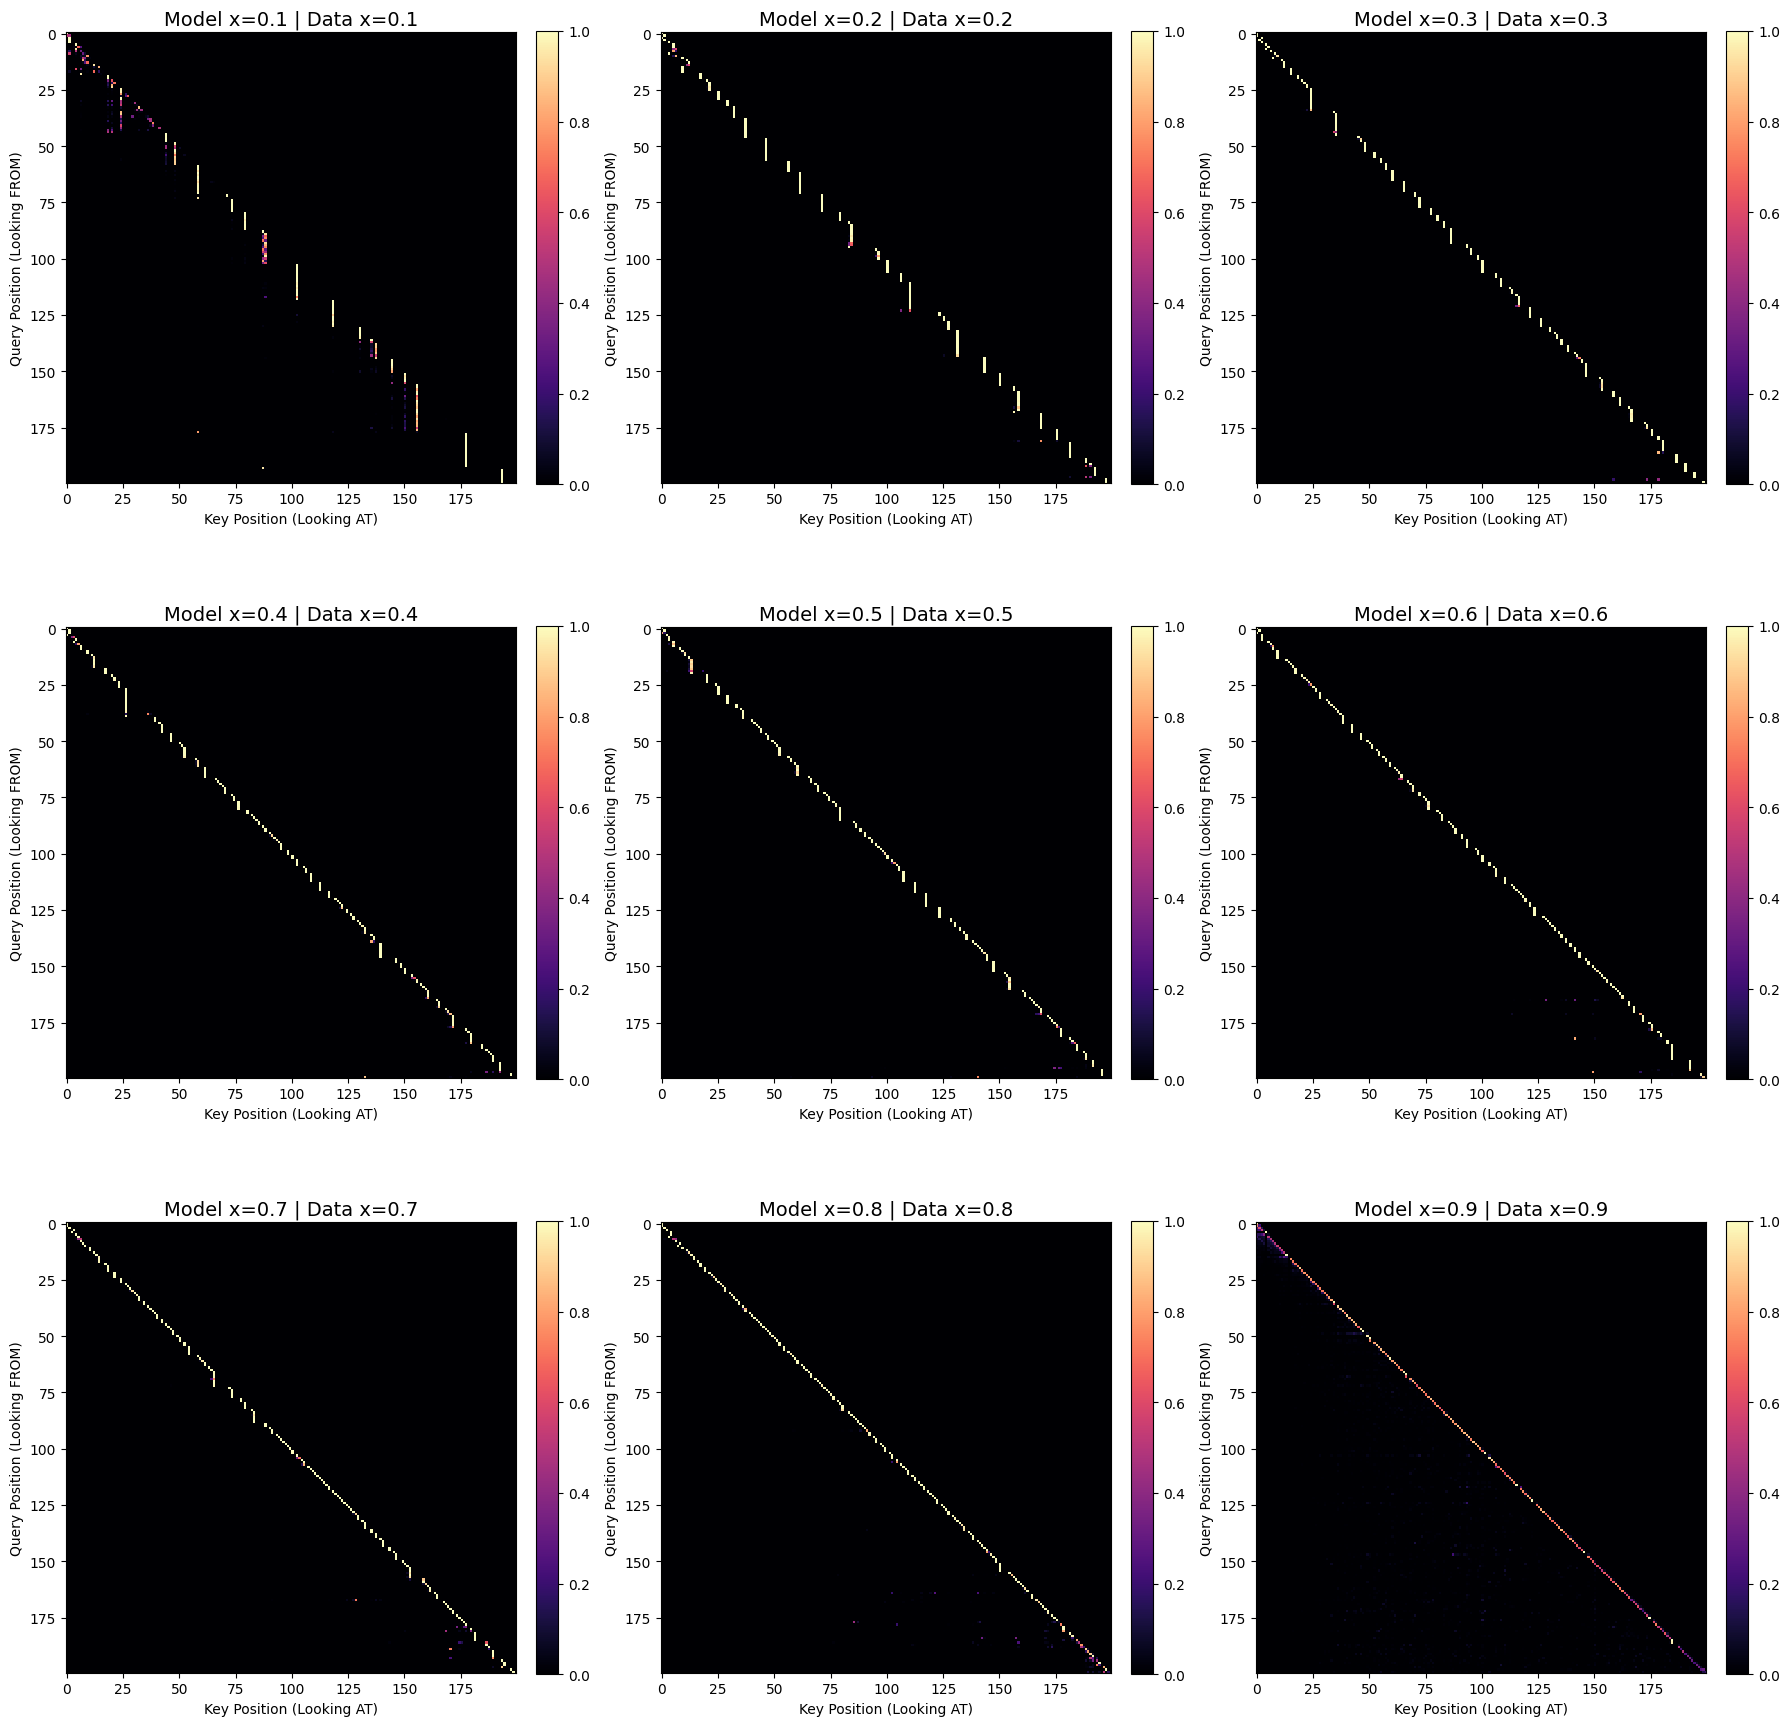

In [7]:
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
axes = axes.flatten()

for idx, x in enumerate(CONFIG['thresholds']):
    model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth")
    
    if not os.path.exists(model_path):
        axes[idx].set_title(f"x={x} Not Found")
        axes[idx].axis('off')
        continue
        
    # Load the model for this threshold
    model = DisentangledTransformer().to(CONFIG['device'])
    model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
    model.eval()
    
    # FIX: Generate a sequence matching THIS model's specific threshold
    seq_for_this_model = generate_fast_test_data(1, x).to(CONFIG['device'])
    
    # Forward pass to extract the Layer 1 attention map
    with torch.no_grad():
        _, attns = model(seq_for_this_model)
        l1_attn_map = attns[0].squeeze(0).cpu().numpy()
        
    # Plot the heatmap
    ax = axes[idx]
    cax = ax.imshow(l1_attn_map, cmap='magma', interpolation='nearest')
    ax.set_title(f"Model x={x} | Data x={x}", fontsize=14)
    ax.set_xlabel("Key Position (Looking AT)")
    ax.set_ylabel("Query Position (Looking FROM)")
    fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)

    # Free memory
    del model, seq_for_this_model
    torch.cuda.empty_cache()

plt.tight_layout()
plt.savefig(f"{CONFIG['output_dir']}/layer1_threshold_specific_heatmaps.png")
plt.show()

>>> Analyzing Local vs Global Attention (Layer 1) on cuda:3


Threshold x=0.9: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 58.96it/s]


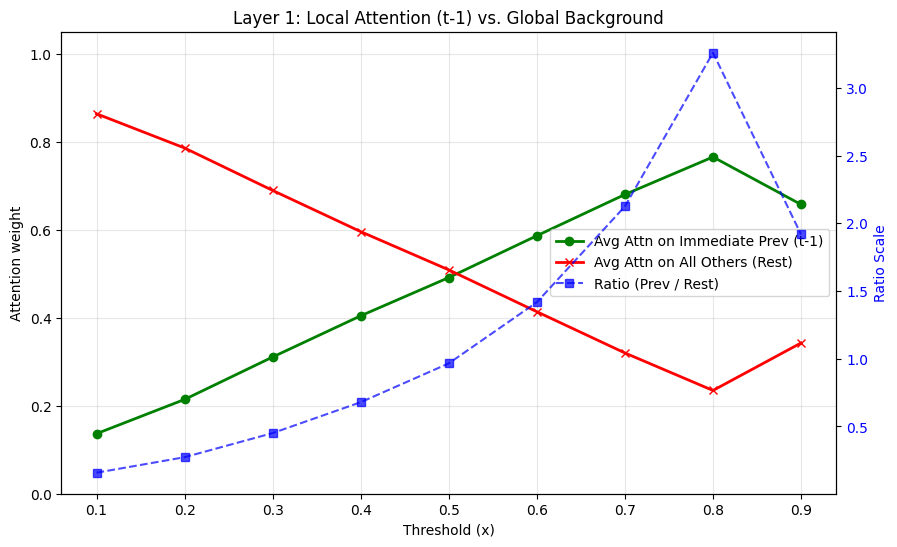

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 200,
    'attn_dim': 64,
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_5',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'num_test_seqs': 1000,
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITION ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data = []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len']):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq)
    return torch.tensor(x_data)

# --- 4. LOCAL VS GLOBAL ATTENTION ANALYSIS ---
def run_local_prev_analysis():
    print(f">>> Analyzing Local vs Global Attention (Layer 1) on {CONFIG['device']}")
    final_stats = {}

    for x in CONFIG['thresholds']:
        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth")
        if not os.path.exists(model_path): continue

        model = DisentangledTransformer().to(CONFIG['device'])
        model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
        model.eval()

        tx = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        loader = torch.utils.data.DataLoader(tx, batch_size=CONFIG['batch_size'], shuffle=False)

        total_prev_attn = 0.0
        total_rest_attn = 0.0
        total_tokens_evaluated = 0

        for batch in tqdm(loader, desc=f"Threshold x={x}"):
            batch = batch.to(CONFIG['device'])
            B, T = batch.shape
            with torch.no_grad():
                _, attns = model(batch)
                l1_attn = attns[0] # [B, T, T]

            # We need to extract the attention at position (t, t-1) for every t > 0
            # Create a diagonal mask for the immediate previous token
            # offset=-1 gives the elements where Query=t and Key=t-1
            diag_mask = torch.diag(torch.ones(T-1, device=CONFIG['device']), diagonal=-1).unsqueeze(0) # [1, T, T]
            
            # Sum attention on the immediate previous token
            # We only evaluate tokens from index 1 to T-1 (index 0 has no previous)
            prev_attn = (l1_attn * diag_mask).sum(dim=(1, 2)) # Sum across T, T for each batch item
            
            # Rest of the attention (1.0 - prev_attn) for each token
            # Note: For index 0, prev_attn is 0, but we should only count tokens that HAVE a previous
            batch_prev_sum = prev_attn.sum().item()
            
            total_prev_attn += batch_prev_sum
            # total_rest is (Budget for T-1 tokens) - (Attn spent on T-1 tokens)
            total_rest_attn += (B * (T-1)) - batch_prev_sum
            total_tokens_evaluated += (B * (T-1))

        avg_prev = total_prev_attn / total_tokens_evaluated
        avg_rest = total_rest_attn / total_tokens_evaluated
        
        final_stats[x] = {
            'prev_avg': avg_prev,
            'rest_avg': avg_rest,
            'ratio': avg_prev / avg_rest if avg_rest > 0 else float('inf')
        }
        
        del model, tx, loader
        torch.cuda.empty_cache()

    return final_stats

# --- 5. PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    prev = [stats[x]['prev_avg'] for x in x_vals]
    rest = [stats[x]['rest_avg'] for x in x_vals]
    ratios = [stats[x]['ratio'] for x in x_vals]

    fig, ax1 = plt.subplots(figsize=(10, 6))
    ax1.plot(x_vals, prev, 'g-o', linewidth=2, label='Avg Attn on Immediate Prev (t-1)')
    ax1.plot(x_vals, rest, 'r-x', linewidth=2, label='Avg Attn on All Others (Rest)')
    ax1.set_xlabel("Threshold (x)")
    ax1.set_ylabel("Attention weight")
    ax1.set_ylim(0, 1.05)
    ax1.grid(True, alpha=0.3)

    ax2 = ax1.twinx()
    ax2.plot(x_vals, ratios, 'b--s', alpha=0.7, label='Ratio (Prev / Rest)')
    ax2.set_ylabel("Ratio Scale", color='blue')
    ax2.tick_params(axis='y', labelcolor='blue')

    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right')
    plt.title("Layer 1: Local Attention (t-1) vs. Global Background")
    plt.savefig(f"{CONFIG['output_dir']}/local_vs_global.png")
    plt.show()

if __name__ == "__main__":
    stats = run_local_prev_analysis()
    plot_results(stats)

>>> Running 'Previous Ruled Token' Tracking on cuda:3


Evaluating x=0.9: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:11<00:00,  2.99s/it]


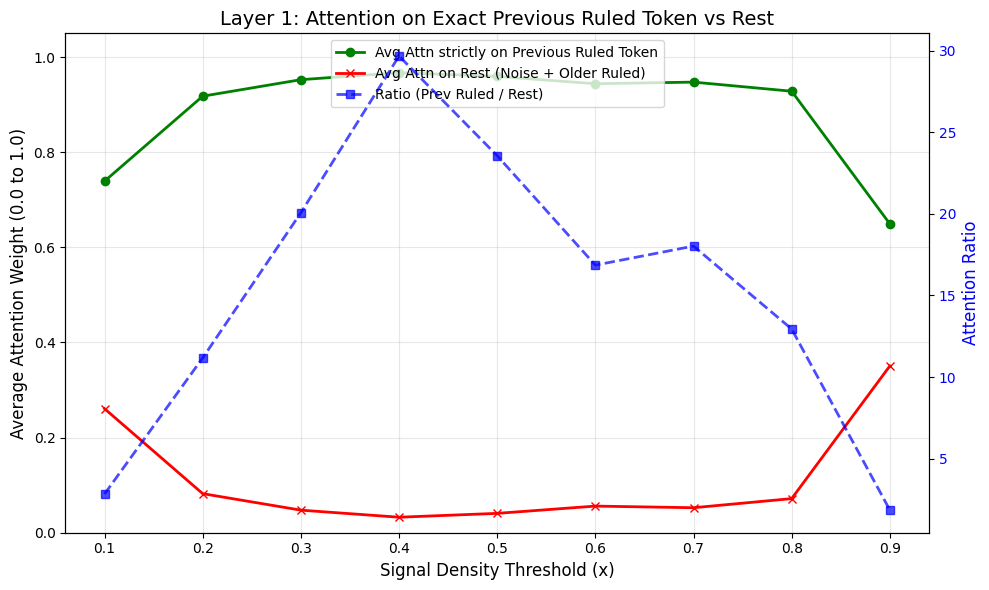

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,
    'attn_dim': 64,
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu', # Targeting GPU 3
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_6',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'num_test_seqs': 1000,
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITION ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data = []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len']):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq)
    return torch.tensor(x_data)

# --- 4. PREVIOUS RULED TOKEN ANALYSIS ---
def run_previous_ruled_analysis():
    print(f">>> Running 'Previous Ruled Token' Tracking on {CONFIG['device']}")
    final_stats = {}

    for x in CONFIG['thresholds']:
        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if not os.path.exists(model_path):
            print(f"Skipping x={x}: File not found.")
            continue

        model = DisentangledTransformer().to(CONFIG['device'])
        model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
        model.eval()

        tx = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        loader = torch.utils.data.DataLoader(tx, batch_size=CONFIG['batch_size'], shuffle=False)

        total_prev_ruled_attn = 0.0
        total_rest_attn = 0.0
        total_tokens_evaluated = 0

        for batch in tqdm(loader, desc=f"Evaluating x={x}"):
            batch = batch.to(CONFIG['device'])
            B, T = batch.shape

            with torch.no_grad():
                _, attns = model(batch)
                l1_attn = attns[0] # Layer 1 Attention Map: [B, T, T]

            # Iterate over each sequence in the batch
            for b in range(B):
                # Find all indices where the token is a Ruled Token (ID 0-9)
                ruled_indices = (batch[b] < CONFIG['vocab_set1']).nonzero(as_tuple=True)[0]

                # We need at least 2 ruled tokens in the sequence to have a "previous" one
                if len(ruled_indices) > 1:
                    # Current ruled tokens (skip the first one since it has no previous)
                    curr_indices = ruled_indices[1:]
                    # The exact previous ruled token for each current token
                    prev_indices = ruled_indices[:-1]
                    
                    # Extract the attention weight from each current ruled token to its specific previous ruled token
                    # This completely ignores how much noise was in between them
                    attns_on_prev = l1_attn[b, curr_indices, prev_indices]
                    
                    batch_prev_sum = attns_on_prev.sum().item()
                    
                    # Since softmax guarantees attention sums to 1.0 for each query,
                    # the attention on "everything else" is just (1.0 * number of tokens) - attention on prev
                    total_prev_ruled_attn += batch_prev_sum
                    total_rest_attn += (len(curr_indices) - batch_prev_sum)
                    total_tokens_evaluated += len(curr_indices)

        # Calculate averages
        avg_prev = total_prev_ruled_attn / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_rest = total_rest_attn / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        ratio = avg_prev / avg_rest if avg_rest > 0 else float('inf')

        final_stats[x] = {
            'prev_avg': avg_prev,
            'rest_avg': avg_rest,
            'ratio': ratio
        }
        
        del model, tx, loader
        torch.cuda.empty_cache()

    return final_stats

# --- 5. PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    prev = [stats[x]['prev_avg'] for x in x_vals]
    rest = [stats[x]['rest_avg'] for x in x_vals]
    ratios = [stats[x]['ratio'] for x in x_vals]

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Left Y-Axis: Attention Weights (0.0 to 1.0)
    ax1.plot(x_vals, prev, 'g-o', linewidth=2, label='Avg Attn strictly on Previous Ruled Token')
    ax1.plot(x_vals, rest, 'r-x', linewidth=2, label='Avg Attn on Rest (Noise + Older Ruled)')
    ax1.set_xlabel("Signal Density Threshold (x)", fontsize=12)
    ax1.set_ylabel("Average Attention Weight (0.0 to 1.0)", fontsize=12)
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 1.05)
    
    # Right Y-Axis: Ratio
    ax2 = ax1.twinx()
    ax2.plot(x_vals, ratios, 'b--s', linewidth=2, alpha=0.7, label='Ratio (Prev Ruled / Rest)')
    ax2.set_ylabel("Attention Ratio", color='blue', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='blue')

    # Combined Legend
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center')

    plt.title("Layer 1: Attention on Exact Previous Ruled Token vs Rest", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/layer1_exact_prev_ruled.png")
    plt.show()

if __name__ == "__main__":
    stats = run_previous_ruled_analysis()
    plot_results(stats)

In [2]:
!nvidia-smi

Thu Mar 26 18:58:02 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.45.04              Driver Version: 595.45.04      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          Off |   00000000:01:01.0 Off |                    0 |
| N/A   50C    P0            189W /  300W |   59493MiB /  81920MiB |    100%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## Plotting attention on signal, on noise(total), there ratio(SNR).

>>> Running 'Previous Ruled Token' Tracking on cuda:3


Evaluating x=0.9: 100%|███████████████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  5.17it/s]


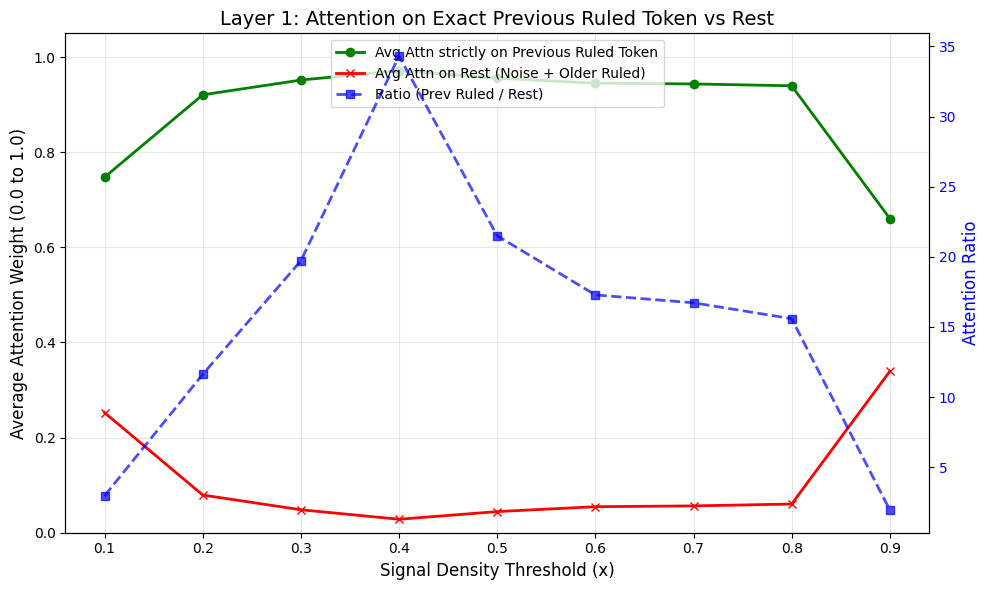

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,
    'attn_dim': 64,
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu', # Targeting GPU 3
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_6',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'num_test_seqs': 10,
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITION ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data = []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len']):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq)
    return torch.tensor(x_data)

# --- 4. PREVIOUS RULED TOKEN ANALYSIS ---
def run_previous_ruled_analysis():
    print(f">>> Running 'Previous Ruled Token' Tracking on {CONFIG['device']}")
    final_stats = {}

    for x in CONFIG['thresholds']:
        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if not os.path.exists(model_path):
            print(f"Skipping x={x}: File not found.")
            continue

        model = DisentangledTransformer().to(CONFIG['device'])
        model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
        model.eval()

        tx = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        loader = torch.utils.data.DataLoader(tx, batch_size=CONFIG['batch_size'], shuffle=False)

        total_prev_ruled_attn = 0.0
        total_rest_attn = 0.0
        total_tokens_evaluated = 0

        for batch in tqdm(loader, desc=f"Evaluating x={x}"):
            batch = batch.to(CONFIG['device'])
            B, T = batch.shape

            with torch.no_grad():
                _, attns = model(batch)
                l1_attn = attns[0] # Layer 1 Attention Map: [B, T, T]

            # Iterate over each sequence in the batch
            for b in range(B):
                # Find all indices where the token is a Ruled Token (ID 0-9)
                ruled_indices = (batch[b] < CONFIG['vocab_set1']).nonzero(as_tuple=True)[0]

                # We need at least 2 ruled tokens in the sequence to have a "previous" one
                if len(ruled_indices) > 1:
                    # Current ruled tokens (skip the first one since it has no previous)
                    curr_indices = ruled_indices[1:]
                    # The exact previous ruled token for each current token
                    prev_indices = ruled_indices[:-1]
                    
                    # Extract the attention weight from each current ruled token to its specific previous ruled token
                    # This completely ignores how much noise was in between them
                    attns_on_prev = l1_attn[b, curr_indices, prev_indices]
                    
                    batch_prev_sum = attns_on_prev.sum().item()
                    
                    # Since softmax guarantees attention sums to 1.0 for each query,
                    # the attention on "everything else" is just (1.0 * number of tokens) - attention on prev
                    total_prev_ruled_attn += batch_prev_sum
                    total_rest_attn += (len(curr_indices) - batch_prev_sum)
                    total_tokens_evaluated += len(curr_indices)

        # Calculate averages
        avg_prev = total_prev_ruled_attn / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_rest = total_rest_attn / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        ratio = avg_prev / avg_rest if avg_rest > 0 else float('inf')

        final_stats[x] = {
            'prev_avg': avg_prev,
            'rest_avg': avg_rest,
            'ratio': ratio
        }
        
        del model, tx, loader
        torch.cuda.empty_cache()

    return final_stats

# --- 5. PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    prev = [stats[x]['prev_avg'] for x in x_vals]
    rest = [stats[x]['rest_avg'] for x in x_vals]
    ratios = [stats[x]['ratio'] for x in x_vals]

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Left Y-Axis: Attention Weights (0.0 to 1.0)
    ax1.plot(x_vals, prev, 'g-o', linewidth=2, label='Avg Attn strictly on Previous Ruled Token')
    ax1.plot(x_vals, rest, 'r-x', linewidth=2, label='Avg Attn on Rest (Noise + Older Ruled)')
    ax1.set_xlabel("Signal Density Threshold (x)", fontsize=12)
    ax1.set_ylabel("Average Attention Weight (0.0 to 1.0)", fontsize=12)
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 1.05)
    
    # Right Y-Axis: Ratio
    ax2 = ax1.twinx()
    ax2.plot(x_vals, ratios, 'b--s', linewidth=2, alpha=0.7, label='Ratio (Prev Ruled / Rest)')
    ax2.set_ylabel("Attention Ratio", color='blue', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='blue')

    # Combined Legend
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper center')

    plt.title("Layer 1: Attention on Exact Previous Ruled Token vs Rest", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/layer1_exact_prev_ruled.png")
    plt.show()

if __name__ == "__main__":
    stats = run_previous_ruled_analysis()
    plot_results(stats)

In [1]:
!nvidia-smi

Fri Mar 27 10:33:53 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.45.04              Driver Version: 595.45.04      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          Off |   00000000:01:01.0 Off |                    0 |
| N/A   49C    P0            129W /  300W |   59493MiB /  81920MiB |     97%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

## Plotting attention on signal, on noise(total), there ratio(SNR), and accuracy for that threshold.

>>> Running 'Previous Ruled Token' & Accuracy Tracking on cuda:0


Evaluating x=0.9: 100%|███████████████████████████████████████████████████████████████| 4/4 [00:02<00:00,  1.60it/s]


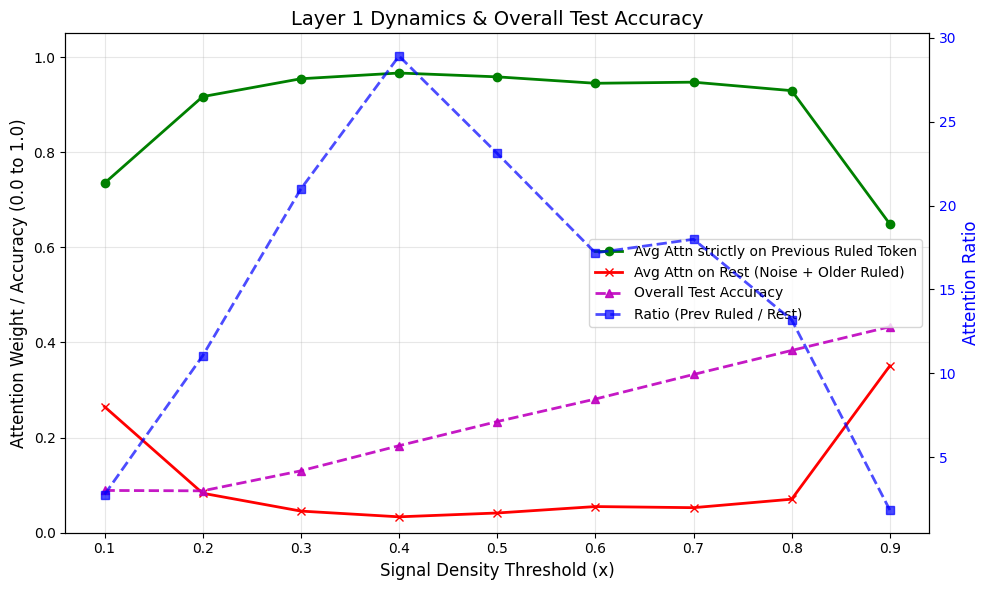

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,
    'attn_dim': 64,
    'device': 'cuda:0' if torch.cuda.is_available() else 'cpu', # Targeting GPU 3
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_6',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'num_test_seqs': 1000,  # Note: I changed this back to 1000 for smooth accuracy curves!
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITION ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION (Updated for Accuracy) ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        # Generate seq_len + 1 to create inputs and targets
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. PREVIOUS RULED TOKEN & ACCURACY ANALYSIS ---
def run_previous_ruled_analysis():
    print(f">>> Running 'Previous Ruled Token' & Accuracy Tracking on {CONFIG['device']}")
    final_stats = {}

    for x in CONFIG['thresholds']:
        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if not os.path.exists(model_path):
            print(f"Skipping x={x}: File not found.")
            continue

        model = DisentangledTransformer().to(CONFIG['device'])
        model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
        model.eval()

        # Load inputs and targets into a TensorDataset
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_prev_ruled_attn = 0.0
        total_rest_attn = 0.0
        total_tokens_evaluated = 0
        
        # Accuracy tracking
        total_correct = 0
        total_preds = 0

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x = batch_x.to(CONFIG['device'])
            batch_y = batch_y.to(CONFIG['device'])
            B, T = batch_x.shape

            with torch.no_grad():
                logits, attns = model(batch_x)
                l1_attn = attns[0] # Layer 1 Attention Map: [B, T, T]
                
                # --- NEW: Calculate Accuracy ---
                preds = logits.argmax(dim=-1)
                total_correct += (preds == batch_y).sum().item()
                total_preds += (B * T)

            # Iterate over each sequence in the batch for attention extraction
            for b in range(B):
                # Find all indices where the token is a Ruled Token (ID 0-9)
                ruled_indices = (batch_x[b] < CONFIG['vocab_set1']).nonzero(as_tuple=True)[0]

                if len(ruled_indices) > 1:
                    curr_indices = ruled_indices[1:]
                    prev_indices = ruled_indices[:-1]
                    
                    attns_on_prev = l1_attn[b, curr_indices, prev_indices]
                    batch_prev_sum = attns_on_prev.sum().item()
                    
                    total_prev_ruled_attn += batch_prev_sum
                    total_rest_attn += (len(curr_indices) - batch_prev_sum)
                    total_tokens_evaluated += len(curr_indices)

        # Calculate averages
        avg_prev = total_prev_ruled_attn / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_rest = total_rest_attn / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        ratio = avg_prev / avg_rest if avg_rest > 0 else float('inf')
        avg_acc = total_correct / total_preds

        final_stats[x] = {
            'prev_avg': avg_prev,
            'rest_avg': avg_rest,
            'ratio': ratio,
            'acc': avg_acc  # Added accuracy to stats
        }
        
        del model, tx, ty, loader, dataset
        torch.cuda.empty_cache()

    return final_stats

# --- 5. PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    prev = [stats[x]['prev_avg'] for x in x_vals]
    rest = [stats[x]['rest_avg'] for x in x_vals]
    ratios = [stats[x]['ratio'] for x in x_vals]
    accs = [stats[x]['acc'] for x in x_vals]

    fig, ax1 = plt.subplots(figsize=(10, 6))

    # Left Y-Axis: Attention Weights & Accuracy (0.0 to 1.0)
    ax1.plot(x_vals, prev, 'g-o', linewidth=2, label='Avg Attn strictly on Previous Ruled Token')
    ax1.plot(x_vals, rest, 'r-x', linewidth=2, label='Avg Attn on Rest (Noise + Older Ruled)')
    ax1.plot(x_vals, accs, 'm--^', linewidth=2, alpha=0.9, label='Overall Test Accuracy') # Added accuracy line
    
    ax1.set_xlabel("Signal Density Threshold (x)", fontsize=12)
    ax1.set_ylabel("Attention Weight / Accuracy (0.0 to 1.0)", fontsize=12)
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 1.05)
    
    # Right Y-Axis: Ratio
    ax2 = ax1.twinx()
    ax2.plot(x_vals, ratios, 'b--s', linewidth=2, alpha=0.7, label='Ratio (Prev Ruled / Rest)')
    ax2.set_ylabel("Attention Ratio", color='blue', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='blue')

    # Combined Legend
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center right')

    plt.title("Layer 1 Dynamics & Overall Test Accuracy", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/layer1_with_accuracy.png")
    plt.show()

if __name__ == "__main__":
    stats = run_previous_ruled_analysis()
    plot_results(stats)

## Plotting attention on immediate left signal, on noise(total), there ratio(SNR), accuracy for that threshold, attention on t-1, total attention on other signal token.

>>> Running 7-Metric Layer 1 Tracking on cuda:3 (Seq Len: 200)


Evaluating x=0.9: 100%|███████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  3.43it/s]


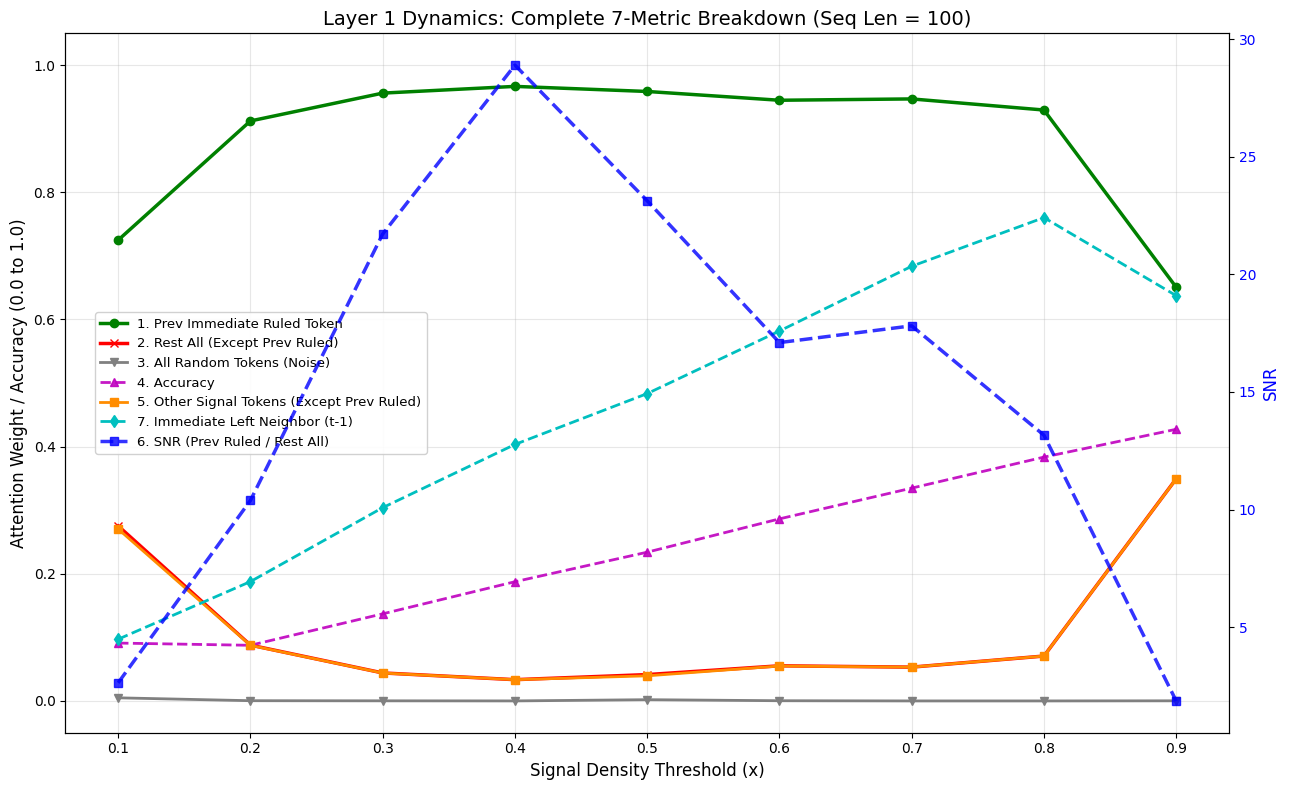

In [35]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,         # Set to 100 as requested
    'attn_dim': 64,
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_10',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'num_test_seqs': 100,
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITION ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. EXHAUSTIVE ATTENTION ANALYSIS ---
def run_exhaustive_analysis():
    print(f">>> Running 7-Metric Layer 1 Tracking on {CONFIG['device']} (Seq Len: {CONFIG['seq_len']})")
    final_stats = {}

    for x in CONFIG['thresholds']:
        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if not os.path.exists(model_path):
            continue

        model = DisentangledTransformer().to(CONFIG['device'])
        model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
        model.eval()

        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        # Running sums for all metrics
        sum_prev_ruled = 0.0
        sum_rest_all = 0.0
        sum_random_tokens = 0.0
        sum_other_signal = 0.0
        sum_t_minus_1 = 0.0
        
        total_tokens_evaluated = 0
        total_correct = 0
        total_preds = 0

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x = batch_x.to(CONFIG['device'])
            batch_y = batch_y.to(CONFIG['device'])
            B, T = batch_x.shape

            with torch.no_grad():
                logits, attns = model(batch_x)
                l1_attn = attns[0] 
                
                # Metric 4: Accuracy calculation
                preds = logits.argmax(dim=-1)
                total_correct += (preds == batch_y).sum().item()
                total_preds += (B * T)

            for b in range(B):
                ruled_indices = (batch_x[b] < CONFIG['vocab_set1']).nonzero(as_tuple=True)[0]

                if len(ruled_indices) > 1:
                    curr_indices = ruled_indices[1:]
                    prev_indices = ruled_indices[:-1]
                    num_queries = len(curr_indices)
                    
                    # Core Masking Setup (Causal)
                    causal_mask = torch.tril(torch.ones(T, T, device=CONFIG['device']), diagonal=0)
                    
                    # Metric 1: Attention on previous immediate ruled token
                    batch_prev_sum = l1_attn[b, curr_indices, prev_indices].sum().item()
                    
                    # Metric 2: Total attention on rest all except immediate ruled token
                    batch_rest_sum = num_queries - batch_prev_sum
                    
                    # Metric 3: Total attention on all random tokens (IDs >= 10)
                    is_random = (batch_x[b] >= CONFIG['vocab_set1']).float()
                    random_keys_mask = causal_mask[curr_indices] * is_random.unsqueeze(0)
                    batch_random_sum = (l1_attn[b, curr_indices] * random_keys_mask).sum().item()

                    # Metric 5: Total attention on signal token except immediately previous token
                    is_signal = (batch_x[b] < CONFIG['vocab_set1']).float()
                    signal_keys_mask = causal_mask[curr_indices] * is_signal.unsqueeze(0)
                    prev_one_hot = F.one_hot(prev_indices, num_classes=T).float()
                    other_signal_keys_mask = signal_keys_mask - prev_one_hot
                    batch_other_signal_sum = (l1_attn[b, curr_indices] * other_signal_keys_mask).sum().item()

                    # Metric 7: Total attention on immediate left neighbour (t-1)
                    t_minus_1_indices = curr_indices - 1
                    batch_t_minus_1_sum = l1_attn[b, curr_indices, t_minus_1_indices].sum().item()

                    # Add to running totals
                    sum_prev_ruled += batch_prev_sum
                    sum_rest_all += batch_rest_sum
                    sum_random_tokens += batch_random_sum
                    sum_other_signal += batch_other_signal_sum
                    sum_t_minus_1 += batch_t_minus_1_sum
                    total_tokens_evaluated += num_queries

        # Calculate Averages
        avg_prev_ruled = sum_prev_ruled / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_rest_all = sum_rest_all / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_random_tokens = sum_random_tokens / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_other_signal = sum_other_signal / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_t_minus_1 = sum_t_minus_1 / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        
        # Metric 6: SNR = Attention on immediate ruled / Attention on rest all
        snr = avg_prev_ruled / avg_rest_all if avg_rest_all > 0 else float('inf')
        
        # Metric 4: Accuracy
        acc = total_correct / total_preds

        final_stats[x] = {
            '1_prev_ruled': avg_prev_ruled,
            '2_rest_all': avg_rest_all,
            '3_random_tokens': avg_random_tokens,
            '4_acc': acc,
            '5_other_signal': avg_other_signal,
            '6_snr': snr,
            '7_t_minus_1': avg_t_minus_1
        }
        
        del model, tx, ty, loader, dataset
        torch.cuda.empty_cache()

    return final_stats

# --- 5. PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    m1_prev = [stats[x]['1_prev_ruled'] for x in x_vals]
    m2_rest = [stats[x]['2_rest_all'] for x in x_vals]
    m3_random = [stats[x]['3_random_tokens'] for x in x_vals]
    m4_acc = [stats[x]['4_acc'] for x in x_vals]
    m5_other_sig = [stats[x]['5_other_signal'] for x in x_vals]
    m6_snr = [stats[x]['6_snr'] for x in x_vals]
    m7_t_minus_1 = [stats[x]['7_t_minus_1'] for x in x_vals]

    fig, ax1 = plt.subplots(figsize=(13, 8))

    # Left Axis: Attention Weights & Accuracy
    ax1.plot(x_vals, m1_prev, 'g-o', linewidth=2.5, label='1. Prev Immediate Ruled Token')
    ax1.plot(x_vals, m2_rest, 'r-x', linewidth=2.5, label='2. Rest All (Except Prev Ruled)')
    ax1.plot(x_vals, m3_random, color='gray', marker='v', linestyle='-', linewidth=2, label='3. All Random Tokens (Noise)')
    ax1.plot(x_vals, m4_acc, 'm--^', linewidth=2, alpha=0.9, label='4. Accuracy')
    ax1.plot(x_vals, m5_other_sig, color='darkorange', marker='s', linestyle='-', linewidth=2, label='5. Other Signal Tokens (Except Prev Ruled)')
    ax1.plot(x_vals, m7_t_minus_1, 'c--d', linewidth=2, label='7. Immediate Left Neighbor (t-1)')
    
    ax1.set_xlabel("Signal Density Threshold (x)", fontsize=12)
    ax1.set_ylabel("Attention Weight / Accuracy (0.0 to 1.0)", fontsize=12)
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(-0.05, 1.05)
    
    # Right Axis: SNR
    ax2 = ax1.twinx()
    ax2.plot(x_vals, m6_snr, 'b--s', linewidth=2.5, alpha=0.8, label='6. SNR (Prev Ruled / Rest All)')
    ax2.set_ylabel("SNR", color='blue', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='blue')

    # Combined Legend perfectly inside the plot
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center left', bbox_to_anchor=(0.02, 0.5), fontsize=9.5, framealpha=0.9)

    plt.title("Layer 1 Dynamics: Complete 7-Metric Breakdown (Seq Len = 100)", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/layer1_7_metrics_breakdown.png")
    plt.show()

if __name__ == "__main__":
    stats = run_exhaustive_analysis()
    plot_results(stats)

In [34]:
!nvidia-smi

Fri Mar 27 13:56:51 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.45.04              Driver Version: 595.45.04      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          Off |   00000000:01:01.0 Off |                    0 |
| N/A   58C    P0            248W /  300W |   74928MiB /  81920MiB |    100%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [36]:
!nvidia-smi

Fri Mar 27 15:53:57 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 595.45.04              Driver Version: 595.45.04      CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA A100 80GB PCIe          Off |   00000000:01:01.0 Off |                    0 |
| N/A   53C    P0            139W /  300W |   74928MiB /  81920MiB |    100%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

>>> Running 8-Metric Layer 1 Tracking on cuda:3 (Seq Len: 200)


Evaluating x=0.9: 100%|███████████████████████████████████████████████████████████████| 1/1 [00:11<00:00, 11.81s/it]


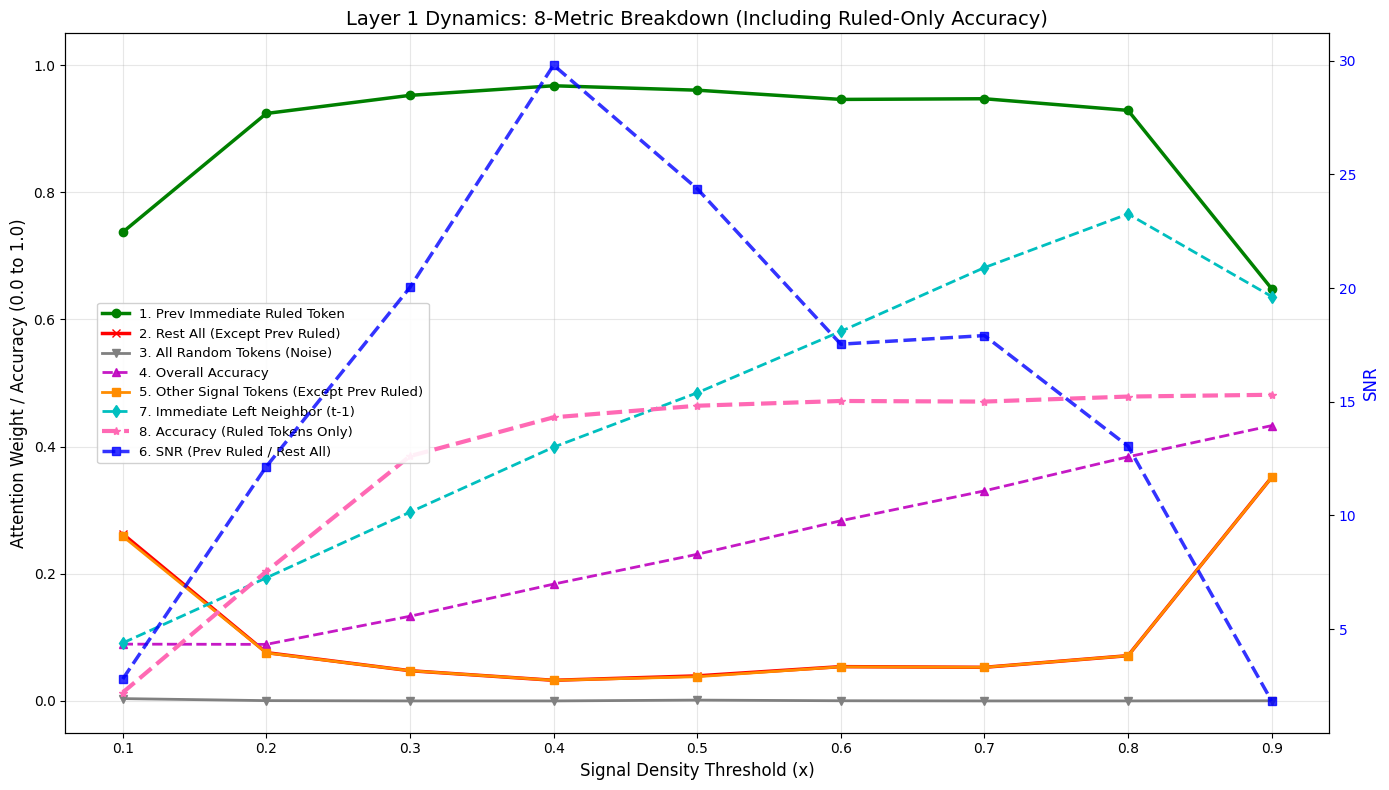

In [38]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,         
    'attn_dim': 64,
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_11',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'num_test_seqs': 200,
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITION ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. EXHAUSTIVE ATTENTION ANALYSIS ---
def run_exhaustive_analysis():
    print(f">>> Running 8-Metric Layer 1 Tracking on {CONFIG['device']} (Seq Len: {CONFIG['seq_len']})")
    final_stats = {}

    for x in CONFIG['thresholds']:
        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if not os.path.exists(model_path):
            continue

        model = DisentangledTransformer().to(CONFIG['device'])
        model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
        model.eval()

        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        # Running sums for all metrics
        sum_prev_ruled = 0.0
        sum_rest_all = 0.0
        sum_random_tokens = 0.0
        sum_other_signal = 0.0
        sum_t_minus_1 = 0.0
        
        total_tokens_evaluated = 0
        total_correct = 0
        total_preds = 0
        
        # New trackers for Ruled-Only Accuracy
        total_ruled_correct = 0
        total_ruled_preds = 0

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x = batch_x.to(CONFIG['device'])
            batch_y = batch_y.to(CONFIG['device'])
            B, T = batch_x.shape

            with torch.no_grad():
                logits, attns = model(batch_x)
                l1_attn = attns[0] 
                
                preds = logits.argmax(dim=-1)
                
                # Metric 4: Overall Accuracy calculation
                total_correct += (preds == batch_y).sum().item()
                total_preds += (B * T)
                
                # Metric 8: Ruled-Only Accuracy calculation
                is_ruled_target = batch_y < CONFIG['vocab_set1']
                ruled_correct = (preds == batch_y) & is_ruled_target
                total_ruled_correct += ruled_correct.sum().item()
                total_ruled_preds += is_ruled_target.sum().item()

            for b in range(B):
                ruled_indices = (batch_x[b] < CONFIG['vocab_set1']).nonzero(as_tuple=True)[0]

                if len(ruled_indices) > 1:
                    curr_indices = ruled_indices[1:]
                    prev_indices = ruled_indices[:-1]
                    num_queries = len(curr_indices)
                    
                    # Core Masking Setup (Causal)
                    causal_mask = torch.tril(torch.ones(T, T, device=CONFIG['device']), diagonal=0)
                    
                    # Metric 1: Attention on previous immediate ruled token
                    batch_prev_sum = l1_attn[b, curr_indices, prev_indices].sum().item()
                    
                    # Metric 2: Total attention on rest all except immediate ruled token
                    batch_rest_sum = num_queries - batch_prev_sum
                    
                    # Metric 3: Total attention on all random tokens (IDs >= 10)
                    is_random = (batch_x[b] >= CONFIG['vocab_set1']).float()
                    random_keys_mask = causal_mask[curr_indices] * is_random.unsqueeze(0)
                    batch_random_sum = (l1_attn[b, curr_indices] * random_keys_mask).sum().item()

                    # Metric 5: Total attention on signal token except immediately previous token
                    is_signal = (batch_x[b] < CONFIG['vocab_set1']).float()
                    signal_keys_mask = causal_mask[curr_indices] * is_signal.unsqueeze(0)
                    prev_one_hot = F.one_hot(prev_indices, num_classes=T).float()
                    other_signal_keys_mask = signal_keys_mask - prev_one_hot
                    batch_other_signal_sum = (l1_attn[b, curr_indices] * other_signal_keys_mask).sum().item()

                    # Metric 7: Total attention on immediate left neighbour (t-1)
                    t_minus_1_indices = curr_indices - 1
                    batch_t_minus_1_sum = l1_attn[b, curr_indices, t_minus_1_indices].sum().item()

                    # Add to running totals
                    sum_prev_ruled += batch_prev_sum
                    sum_rest_all += batch_rest_sum
                    sum_random_tokens += batch_random_sum
                    sum_other_signal += batch_other_signal_sum
                    sum_t_minus_1 += batch_t_minus_1_sum
                    total_tokens_evaluated += num_queries

        # Calculate Averages
        avg_prev_ruled = sum_prev_ruled / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_rest_all = sum_rest_all / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_random_tokens = sum_random_tokens / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_other_signal = sum_other_signal / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        avg_t_minus_1 = sum_t_minus_1 / total_tokens_evaluated if total_tokens_evaluated > 0 else 0
        
        # Metric 6: SNR
        snr = avg_prev_ruled / avg_rest_all if avg_rest_all > 0 else float('inf')
        
        # Metric 4: Overall Accuracy
        acc = total_correct / total_preds
        
        # Metric 8: Ruled-Only Accuracy
        acc_ruled = total_ruled_correct / total_ruled_preds if total_ruled_preds > 0 else 0

        final_stats[x] = {
            '1_prev_ruled': avg_prev_ruled,
            '2_rest_all': avg_rest_all,
            '3_random_tokens': avg_random_tokens,
            '4_acc': acc,
            '5_other_signal': avg_other_signal,
            '6_snr': snr,
            '7_t_minus_1': avg_t_minus_1,
            '8_acc_ruled': acc_ruled
        }
        
        del model, tx, ty, loader, dataset
        torch.cuda.empty_cache()

    return final_stats

# --- 5. PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    m1_prev = [stats[x]['1_prev_ruled'] for x in x_vals]
    m2_rest = [stats[x]['2_rest_all'] for x in x_vals]
    m3_random = [stats[x]['3_random_tokens'] for x in x_vals]
    m4_acc = [stats[x]['4_acc'] for x in x_vals]
    m5_other_sig = [stats[x]['5_other_signal'] for x in x_vals]
    m6_snr = [stats[x]['6_snr'] for x in x_vals]
    m7_t_minus_1 = [stats[x]['7_t_minus_1'] for x in x_vals]
    m8_acc_ruled = [stats[x]['8_acc_ruled'] for x in x_vals]

    fig, ax1 = plt.subplots(figsize=(14, 8))

    # Left Axis: Attention Weights & Accuracies
    ax1.plot(x_vals, m1_prev, 'g-o', linewidth=2.5, label='1. Prev Immediate Ruled Token')
    ax1.plot(x_vals, m2_rest, 'r-x', linewidth=2.5, label='2. Rest All (Except Prev Ruled)')
    ax1.plot(x_vals, m3_random, color='gray', marker='v', linestyle='-', linewidth=2, label='3. All Random Tokens (Noise)')
    ax1.plot(x_vals, m4_acc, 'm--^', linewidth=2, alpha=0.9, label='4. Overall Accuracy')
    ax1.plot(x_vals, m5_other_sig, color='darkorange', marker='s', linestyle='-', linewidth=2, label='5. Other Signal Tokens (Except Prev Ruled)')
    ax1.plot(x_vals, m7_t_minus_1, 'c--d', linewidth=2, label='7. Immediate Left Neighbor (t-1)')
    ax1.plot(x_vals, m8_acc_ruled, color='hotpink', marker='*', linestyle='--', linewidth=3, label='8. Accuracy (Ruled Tokens Only)')
    
    ax1.set_xlabel("Signal Density Threshold (x)", fontsize=12)
    ax1.set_ylabel("Attention Weight / Accuracy (0.0 to 1.0)", fontsize=12)
    ax1.grid(True, alpha=0.3)
    ax1.set_ylim(-0.05, 1.05)
    
    # Right Axis: SNR
    ax2 = ax1.twinx()
    ax2.plot(x_vals, m6_snr, 'b--s', linewidth=2.5, alpha=0.8, label='6. SNR (Prev Ruled / Rest All)')
    ax2.set_ylabel("SNR", color='blue', fontsize=12)
    ax2.tick_params(axis='y', labelcolor='blue')

    # Combined Legend perfectly inside the plot
    lines_1, labels_1 = ax1.get_legend_handles_labels()
    lines_2, labels_2 = ax2.get_legend_handles_labels()
    ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='center left', bbox_to_anchor=(0.02, 0.5), fontsize=9.5, framealpha=0.9)

    plt.title("Layer 1 Dynamics: 8-Metric Breakdown (Including Ruled-Only Accuracy)", fontsize=14)
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/layer1_8_metrics_breakdown.png")
    plt.show()

if __name__ == "__main__":
    stats = run_exhaustive_analysis()
    plot_results(stats)

>>> Running Fast Accuracy Comparison on cuda:3


Evaluating x=0.9: 100%|██████████| 4/4 [00:00<00:00, 99.68it/s]


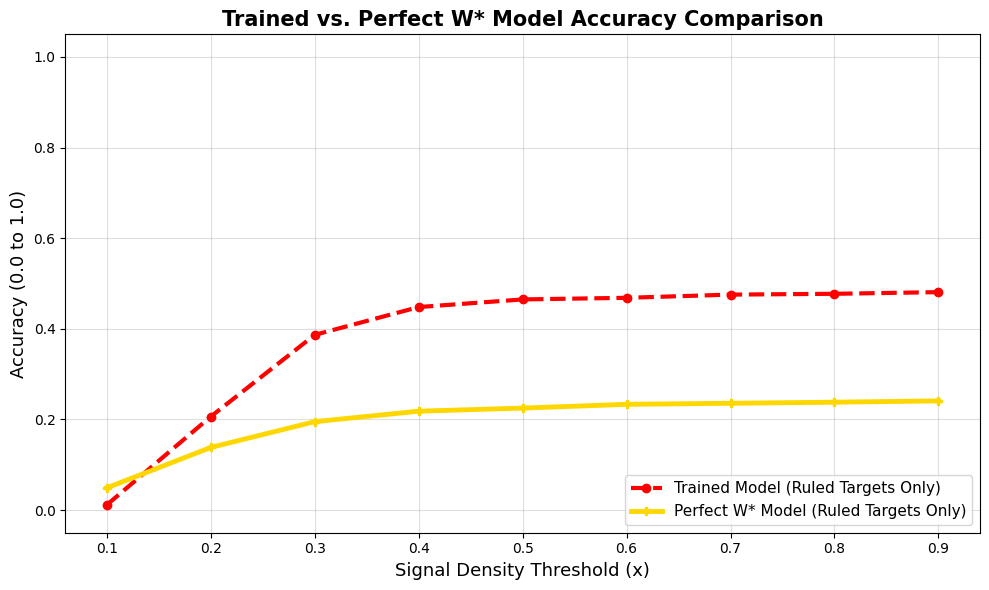

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_final',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9],
    'num_test_seqs': 1000,   
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITIONS ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

# The Original Trained Model
class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# The Perfect Theoretical Model (W*) - UPDATED WITH YOUR FIX
class PerfectInductionTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.attn_dim = self.initial_dim  # Forced to 220 (|V| + T)
        
        self.layer1 = ConcatAttentionBlock(self.initial_dim, self.attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, CONFIG['total_vocab'], bias=False)
        self._set_perfect_weights()

    def _set_perfect_weights(self):
        V = CONFIG['total_vocab']
        T = CONFIG['seq_len']
        D = self.attn_dim
        
        # --- LAYER 1: The Strict Signal Retriever ---
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        
        Target1 = torch.zeros(D, D)
        for id_k in range(CONFIG['vocab_set1'], V): # W_VV: -Infinity for Noise tokens
            Target1[0:V, id_k] = -1e9
            
        alpha = 20.0
        for t_q in range(T):
            for t_k in range(T):
                if t_q == t_k:
                    Target1[V + t_q, V + t_k] = -1e9  # Strict causal mask
                else:
                    Target1[V + t_q, V + t_k] = -alpha * (t_q - t_k) # Distance penalty
                    
        self.layer1.W_k.weight.data = Target1.t()
        
        W_v1 = torch.zeros(D, D)
        W_v1[0:V, 0:V] = torch.eye(V) # Extract only vocab
        self.layer1.W_v.weight.data = W_v1
        self.layer1.W_o.weight.data = torch.eye(D) # I matrix
        
        # --- LAYER 2: The Context Search & Noise Filter ---
        in2 = D + D
        W_q2 = torch.zeros(D, in2)
        
        # YOUR FIX: Query uses Layer 1 Output (D:D+V) instead of Input (0:V)
        W_q2[0:V, D:D+V] = torch.eye(V) * (D ** 0.5) * 50.0 
        
        # Secret dimension for Noise Filtering (Triggered by L1 Output)
        for v in range(CONFIG['vocab_set1']):
            W_q2[V, D + v] = (D ** 0.5) * 50.0  
        self.layer2.W_q.weight.data = W_q2
        
        W_k2 = torch.zeros(D, in2)
        # Match against Layer 1 output of past tokens
        W_k2[0:V, D:D+V] = torch.eye(V) 
        
        # Apply massive negative penalty if past token's original input was Noise
        for v in range(CONFIG['vocab_set1'], V):
            W_k2[V, v] = -1000.0 
        self.layer2.W_k.weight.data = W_k2
        
        W_v2 = torch.zeros(D, in2)
        # Extract original vocab of matched token
        W_v2[0:V, 0:V] = torch.eye(V) 
        self.layer2.W_v.weight.data = W_v2
        self.layer2.W_o.weight.data = torch.eye(D) # I matrix
        
        # --- FINAL OUTPUT: The Logit Scaler ---
        W_fc = torch.zeros(V, in2 + D)
        # Extract Layer 2 vocab & scale for sharp argmax
        W_fc[0:V, in2:in2+V] = torch.eye(V) * 50.0 
        self.fc_out.weight.data = W_fc

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. ACCURACY-ONLY ANALYSIS ---
def run_accuracy_only_analysis():
    print(f">>> Running Fast Accuracy Comparison on {CONFIG['device']}")
    final_stats = {}
    
    # Initialize the Perfect Model once
    perfect_model = PerfectInductionTransformer().to(CONFIG['device'])
    perfect_model.eval()

    for x in CONFIG['thresholds']:
        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if not os.path.exists(model_path):
            continue

        trained_model = DisentangledTransformer().to(CONFIG['device'])
        trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
        trained_model.eval()

        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_ruled_correct_trained = 0
        total_ruled_correct_perfect = 0
        total_ruled_targets = 0

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x = batch_x.to(CONFIG['device'])
            batch_y = batch_y.to(CONFIG['device'])
            
            # Graded strictly on positions where a Ruled Token is the target
            is_ruled_target = batch_y < CONFIG['vocab_set1']

            # Evaluate Trained Model
            with torch.no_grad():
                logits, _ = trained_model(batch_x)
                preds = logits.argmax(dim=-1)
                total_ruled_correct_trained += ((preds == batch_y) & is_ruled_target).sum().item()
                
            # Evaluate Perfect W* Model
            with torch.no_grad():
                perf_logits, _ = perfect_model(batch_x)
                perf_preds = perf_logits.argmax(dim=-1)
                total_ruled_correct_perfect += ((perf_preds == batch_y) & is_ruled_target).sum().item()
                
            total_ruled_targets += is_ruled_target.sum().item()

        final_stats[x] = {
            'trained_acc': total_ruled_correct_trained / total_ruled_targets if total_ruled_targets > 0 else 0,
            'perfect_acc': total_ruled_correct_perfect / total_ruled_targets if total_ruled_targets > 0 else 0
        }
        
        del trained_model, tx, ty, loader, dataset
        torch.cuda.empty_cache()

    return final_stats

# --- 5. CLEAN PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    trained_acc = [stats[x]['trained_acc'] for x in x_vals]
    perfect_acc = [stats[x]['perfect_acc'] for x in x_vals]

    plt.figure(figsize=(10, 6))

    # Plot the two accuracy lines strictly for the Target Ruled Tokens
    plt.plot(x_vals, trained_acc, color='red', marker='o', linestyle='--', linewidth=3, label='Trained Model (Ruled Targets Only)')
    plt.plot(x_vals, perfect_acc, color='gold', marker='P', linestyle='-', linewidth=3.5, label='Perfect W* Model (Ruled Targets Only)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Accuracy (0.0 to 1.0)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.ylim(-0.05, 1.05)
    
    plt.legend(loc='lower right', fontsize=11)
    plt.title("Trained vs. Perfect W* Model Accuracy Comparison", fontsize=15, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/accuracy_comparison_final.png")
    plt.show()

if __name__ == "__main__":
    stats = run_accuracy_only_analysis()
    plot_results(stats)

## added threshold = 1.0

>>> Running Fast Accuracy Comparison on cuda:3 (Including x=1.0)


Evaluating x=1.0: 100%|██████████| 4/4 [00:00<00:00, 134.21it/s]


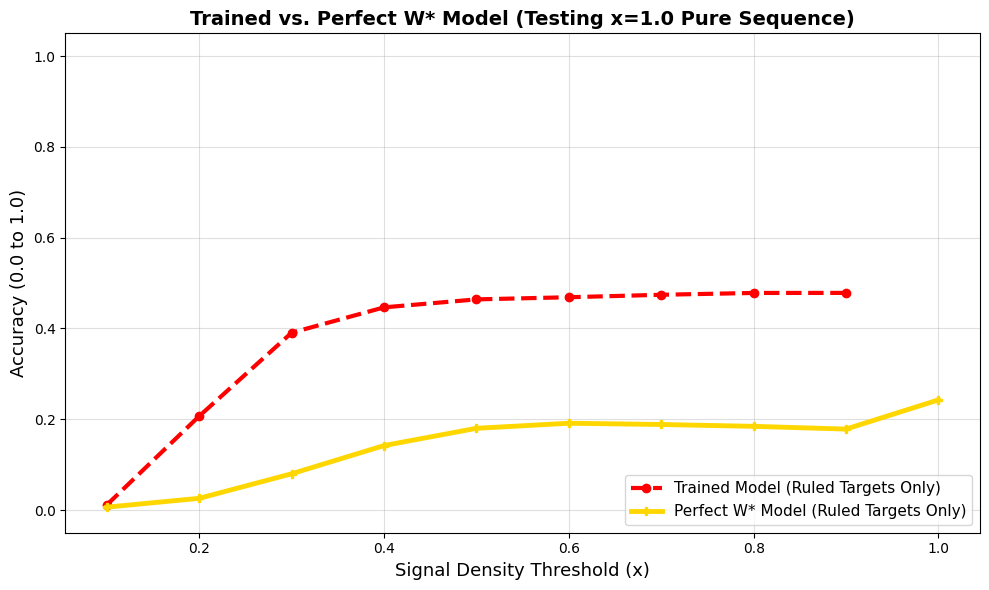

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_final_1',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], # Added 1.0
    'num_test_seqs': 1000,   
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITIONS ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

# The Original Trained Model
class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# The Perfect Theoretical Model (W*) - USING ORIGINAL INPUT FOR QUERY
class PerfectInductionTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.attn_dim = self.initial_dim  # Forced to 220 (|V| + T)
        
        self.layer1 = ConcatAttentionBlock(self.initial_dim, self.attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, CONFIG['total_vocab'], bias=False)
        self._set_perfect_weights()

    def _set_perfect_weights(self):
        V = CONFIG['total_vocab']
        T = CONFIG['seq_len']
        D = self.attn_dim
        
        # --- LAYER 1: The Strict Signal Retriever ---
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        
        Target1 = torch.zeros(D, D)
        for id_k in range(CONFIG['vocab_set1'], V): 
            Target1[0:V, id_k] = -1e9
            
        alpha = 20.0
        for t_q in range(T):
            for t_k in range(T):
                if t_q == t_k:
                    Target1[V + t_q, V + t_k] = -1e9  # Strict causal mask
                else:
                    Target1[V + t_q, V + t_k] = -alpha * (t_q - t_k) # Distance penalty
                    
        self.layer1.W_k.weight.data = Target1.t()
        
        W_v1 = torch.zeros(D, D)
        W_v1[0:V, 0:V] = torch.eye(V) 
        self.layer1.W_v.weight.data = W_v1
        self.layer1.W_o.weight.data = torch.eye(D) 
        
        # --- LAYER 2: The Pure Induction Head ---
        in2 = D + D
        W_q2 = torch.zeros(D, in2)
        
        # YOUR REQUEST: Query uses Original Input (0:V)
        W_q2[0:V, 0:V] = torch.eye(V) * (D ** 0.5) * 50.0 
        self.layer2.W_q.weight.data = W_q2
        
        W_k2 = torch.zeros(D, in2)
        # Key matches against Layer 1 Output (D:D+V)
        W_k2[0:V, D:D+V] = torch.eye(V) 
        self.layer2.W_k.weight.data = W_k2
        
        W_v2 = torch.zeros(D, in2)
        # Extract original vocab of matched token
        W_v2[0:V, 0:V] = torch.eye(V) 
        self.layer2.W_v.weight.data = W_v2
        self.layer2.W_o.weight.data = torch.eye(D) 
        
        # --- FINAL OUTPUT: The Logit Scaler ---
        W_fc = torch.zeros(V, in2 + D)
        W_fc[0:V, in2:in2+V] = torch.eye(V) * 50.0 
        self.fc_out.weight.data = W_fc

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. ACCURACY-ONLY ANALYSIS ---
def run_accuracy_only_analysis():
    print(f">>> Running Fast Accuracy Comparison on {CONFIG['device']} (Including x=1.0)")
    final_stats = {}
    
    # Initialize the Perfect Model once
    perfect_model = PerfectInductionTransformer().to(CONFIG['device'])
    perfect_model.eval()

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_ruled_targets = 0
        total_ruled_correct_perfect = 0
        total_ruled_correct_trained = 0
        trained_model_loaded = False

        # 1. Safely load Trained Model if it exists for this threshold
        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x = batch_x.to(CONFIG['device'])
            batch_y = batch_y.to(CONFIG['device'])
            is_ruled_target = batch_y < CONFIG['vocab_set1']
            total_ruled_targets += is_ruled_target.sum().item()

            # Evaluate Perfect W* Model (Always runs)
            with torch.no_grad():
                perf_logits, _ = perfect_model(batch_x)
                perf_preds = perf_logits.argmax(dim=-1)
                total_ruled_correct_perfect += ((perf_preds == batch_y) & is_ruled_target).sum().item()

            # Evaluate Trained Model (Only if it exists)
            if trained_model_loaded:
                with torch.no_grad():
                    logits, _ = trained_model(batch_x)
                    preds = logits.argmax(dim=-1)
                    total_ruled_correct_trained += ((preds == batch_y) & is_ruled_target).sum().item()

        # Record Stats
        final_stats[x] = {
            'trained_acc': total_ruled_correct_trained / total_ruled_targets if (total_ruled_targets > 0 and trained_model_loaded) else None,
            'perfect_acc': total_ruled_correct_perfect / total_ruled_targets if total_ruled_targets > 0 else 0
        }
        
        if trained_model_loaded:
            del trained_model
        torch.cuda.empty_cache()

    return final_stats

# --- 5. CLEAN PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    # Filter out None values for the trained model if x=1.0 wasn't trained
    trained_x = [x for x in x_vals if stats[x]['trained_acc'] is not None]
    trained_acc = [stats[x]['trained_acc'] for x in trained_x]
    
    perfect_acc = [stats[x]['perfect_acc'] for x in x_vals]

    plt.figure(figsize=(10, 6))

    plt.plot(trained_x, trained_acc, color='red', marker='o', linestyle='--', linewidth=3, label='Trained Model (Ruled Targets Only)')
    plt.plot(x_vals, perfect_acc, color='gold', marker='P', linestyle='-', linewidth=3.5, label='Perfect W* Model (Ruled Targets Only)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Accuracy (0.0 to 1.0)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.ylim(-0.05, 1.05)
    
    plt.legend(loc='lower right', fontsize=11)
    plt.title("Trained vs. Perfect W* Model (Testing x=1.0 Pure Sequence)", fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/accuracy_comparison_x1.png")
    plt.show()

if __name__ == "__main__":
    stats = run_accuracy_only_analysis()
    plot_results(stats)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_final_1',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 
    'num_test_seqs': 1000,   
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITIONS ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# The Perfect Theoretical Model (W*) - FIXED TRANSPOSE BUG
class PerfectInductionTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.attn_dim = self.initial_dim  
        
        self.layer1 = ConcatAttentionBlock(self.initial_dim, self.attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, CONFIG['total_vocab'], bias=False)
        self._set_perfect_weights()

    def _set_perfect_weights(self):
        V = CONFIG['total_vocab']
        T = CONFIG['seq_len']
        D = self.attn_dim
        
        # --- LAYER 1: The Strict Signal Retriever ---
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        
        Target1 = torch.zeros(D, D)
        
        # BUG FIX 1: Mask when KEY is noise (Row = Key)
        for id_k in range(CONFIG['vocab_set1'], V): 
            Target1[id_k, :] = -1e9
            
        alpha = 20.0
        for t_q in range(T):
            for t_k in range(T):
                # BUG FIX 2: Row = Key (t_k), Col = Query (t_q)
                if t_q == t_k:
                    Target1[V + t_k, V + t_q] = -1e9  
                else:
                    Target1[V + t_k, V + t_q] = -alpha * (t_q - t_k) 
                    
        self.layer1.W_k.weight.data = Target1.t()
        
        W_v1 = torch.zeros(D, D)
        W_v1[0:V, 0:V] = torch.eye(V) 
        self.layer1.W_v.weight.data = W_v1
        self.layer1.W_o.weight.data = torch.eye(D) 
        
        # --- LAYER 2: The Pure Induction Head ---
        in2 = D + D
        W_q2 = torch.zeros(D, in2)
        
        # CHANGED: Query now uses Layer 1 Output (D:D+V) instead of Original Input
        W_q2[0:V, D:D+V] = torch.eye(V) * (D ** 0.5) * 50.0 
        self.layer2.W_q.weight.data = W_q2
        
        W_k2 = torch.zeros(D, in2)
        # Key matches against Layer 1 Output (D:D+V)
        W_k2[0:V, D:D+V] = torch.eye(V) 
        self.layer2.W_k.weight.data = W_k2
        
        W_v2 = torch.zeros(D, in2)
        W_v2[0:V, 0:V] = torch.eye(V) 
        self.layer2.W_v.weight.data = W_v2
        self.layer2.W_o.weight.data = torch.eye(D) 
        
        # --- FINAL OUTPUT: The Logit Scaler ---
        W_fc = torch.zeros(V, in2 + D)
        W_fc[0:V, in2:in2+V] = torch.eye(V) * 50.0 
        self.fc_out.weight.data = W_fc

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. ACCURACY-ONLY ANALYSIS ---
def run_accuracy_only_analysis():
    print(f">>> Running Fast Accuracy Comparison on {CONFIG['device']} (Including x=1.0)")
    final_stats = {}
    
    perfect_model = PerfectInductionTransformer().to(CONFIG['device'])
    perfect_model.eval()

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_ruled_targets = 0
        total_ruled_correct_perfect = 0
        total_ruled_correct_trained = 0
        trained_model_loaded = False

        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x = batch_x.to(CONFIG['device'])
            batch_y = batch_y.to(CONFIG['device'])
            is_ruled_target = batch_y < CONFIG['vocab_set1']
            total_ruled_targets += is_ruled_target.sum().item()

            with torch.no_grad():
                perf_logits, _ = perfect_model(batch_x)
                perf_preds = perf_logits.argmax(dim=-1)
                total_ruled_correct_perfect += ((perf_preds == batch_y) & is_ruled_target).sum().item()

            if trained_model_loaded:
                with torch.no_grad():
                    logits, _ = trained_model(batch_x)
                    preds = logits.argmax(dim=-1)
                    total_ruled_correct_trained += ((preds == batch_y) & is_ruled_target).sum().item()

        final_stats[x] = {
            'trained_acc': total_ruled_correct_trained / total_ruled_targets if (total_ruled_targets > 0 and trained_model_loaded) else None,
            'perfect_acc': total_ruled_correct_perfect / total_ruled_targets if total_ruled_targets > 0 else 0
        }
        
        if trained_model_loaded:
            del trained_model
        torch.cuda.empty_cache()

    return final_stats

# --- 5. CLEAN PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    trained_x = [x for x in x_vals if stats[x]['trained_acc'] is not None]
    trained_acc = [stats[x]['trained_acc'] for x in trained_x]
    
    perfect_acc = [stats[x]['perfect_acc'] for x in x_vals]

    plt.figure(figsize=(10, 6))

    plt.plot(trained_x, trained_acc, color='red', marker='o', linestyle='--', linewidth=3, label='Trained Model (Ruled Targets Only)')
    plt.plot(x_vals, perfect_acc, color='gold', marker='P', linestyle='-', linewidth=3.5, label='Perfect W* Model (Ruled Targets Only)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Accuracy (0.0 to 1.0)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.ylim(-0.05, 1.05)
    
    plt.legend(loc='lower right', fontsize=11)
    plt.title("Trained vs. Perfect W* Model (Testing x=1.0 Pure Sequence)", fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/accuracy_comparison_x1.png")
    plt.show()

if __name__ == "__main__":
    stats = run_accuracy_only_analysis()
    plot_results(stats)

>>> Running Fast Accuracy Comparison on cuda:3 (Testing L1-Output Query)


Evaluating x=1.0: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 132.44it/s]


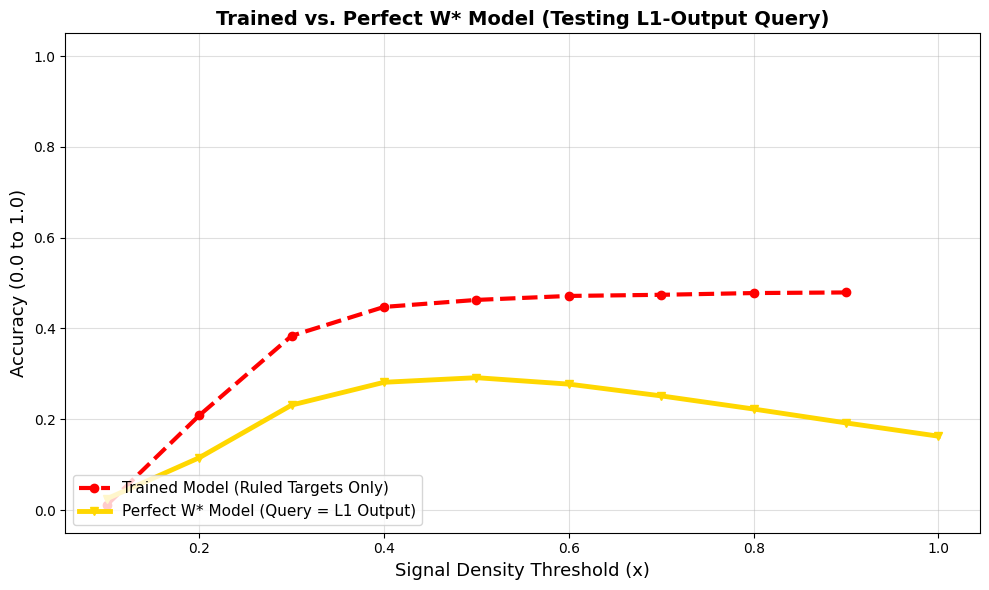

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_final_2', # Updated folder
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0], 
    'num_test_seqs': 1000,   
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITIONS ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# The Perfect Theoretical Model (W*) - EXPERIMENT: L1-OUTPUT QUERY
class PerfectInductionTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.attn_dim = self.initial_dim  
        
        self.layer1 = ConcatAttentionBlock(self.initial_dim, self.attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, CONFIG['total_vocab'], bias=False)
        self._set_perfect_weights()

    def _set_perfect_weights(self):
        V = CONFIG['total_vocab']
        T = CONFIG['seq_len']
        D = self.attn_dim
        
        # --- LAYER 1: The Strict Signal Retriever (Fixed Transpose) ---
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        
        Target1 = torch.zeros(D, D)
        for id_k in range(CONFIG['vocab_set1'], V): 
            Target1[id_k, :] = -1e9
            
        alpha = 20.0
        for t_q in range(T):
            for t_k in range(T):
                if t_q == t_k:
                    Target1[V + t_k, V + t_q] = -1e9  
                else:
                    Target1[V + t_k, V + t_q] = -alpha * (t_q - t_k) 
                    
        self.layer1.W_k.weight.data = Target1.t()
        
        W_v1 = torch.zeros(D, D)
        W_v1[0:V, 0:V] = torch.eye(V) 
        self.layer1.W_v.weight.data = W_v1
        self.layer1.W_o.weight.data = torch.eye(D) 
        
        # --- LAYER 2: The L1-Output Query Head ---
        in2 = D + D
        W_q2 = torch.zeros(D, in2)
        
        # THE EXPERIMENT CHANGE: Query now uses Layer 1 Output (D:D+V)
        W_q2[0:V, D:D+V] = torch.eye(V) * (D ** 0.5) * 50.0 
        self.layer2.W_q.weight.data = W_q2
        
        W_k2 = torch.zeros(D, in2)
        # Key matches against Layer 1 Output (D:D+V)
        W_k2[0:V, D:D+V] = torch.eye(V) 
        self.layer2.W_k.weight.data = W_k2
        
        W_v2 = torch.zeros(D, in2)
        W_v2[0:V, 0:V] = torch.eye(V) 
        self.layer2.W_v.weight.data = W_v2
        self.layer2.W_o.weight.data = torch.eye(D) 
        
        # --- FINAL OUTPUT: The Logit Scaler ---
        W_fc = torch.zeros(V, in2 + D)
        W_fc[0:V, in2:in2+V] = torch.eye(V) * 50.0 
        self.fc_out.weight.data = W_fc

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. ACCURACY-ONLY ANALYSIS ---
def run_accuracy_only_analysis():
    print(f">>> Running Fast Accuracy Comparison on {CONFIG['device']} (Testing L1-Output Query)")
    final_stats = {}
    
    perfect_model = PerfectInductionTransformer().to(CONFIG['device'])
    perfect_model.eval()

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_ruled_targets = 0
        total_ruled_correct_perfect = 0
        total_ruled_correct_trained = 0
        trained_model_loaded = False

        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x = batch_x.to(CONFIG['device'])
            batch_y = batch_y.to(CONFIG['device'])
            is_ruled_target = batch_y < CONFIG['vocab_set1']
            total_ruled_targets += is_ruled_target.sum().item()

            with torch.no_grad():
                perf_logits, _ = perfect_model(batch_x)
                perf_preds = perf_logits.argmax(dim=-1)
                total_ruled_correct_perfect += ((perf_preds == batch_y) & is_ruled_target).sum().item()

            if trained_model_loaded:
                with torch.no_grad():
                    logits, _ = trained_model(batch_x)
                    preds = logits.argmax(dim=-1)
                    total_ruled_correct_trained += ((preds == batch_y) & is_ruled_target).sum().item()

        final_stats[x] = {
            'trained_acc': total_ruled_correct_trained / total_ruled_targets if (total_ruled_targets > 0 and trained_model_loaded) else None,
            'perfect_acc': total_ruled_correct_perfect / total_ruled_targets if total_ruled_targets > 0 else 0
        }
        
        if trained_model_loaded:
            del trained_model
        torch.cuda.empty_cache()

    return final_stats

# --- 5. CLEAN PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    trained_x = [x for x in x_vals if stats[x]['trained_acc'] is not None]
    trained_acc = [stats[x]['trained_acc'] for x in trained_x]
    
    perfect_acc = [stats[x]['perfect_acc'] for x in x_vals]

    plt.figure(figsize=(10, 6))

    plt.plot(trained_x, trained_acc, color='red', marker='o', linestyle='--', linewidth=3, label='Trained Model (Ruled Targets Only)')
    plt.plot(x_vals, perfect_acc, color='gold', marker='v', linestyle='-', linewidth=3.5, label='Perfect W* Model (Query = L1 Output)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Accuracy (0.0 to 1.0)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.ylim(-0.05, 1.05)
    
    plt.legend(loc='lower left', fontsize=11)
    plt.title("Trained vs. Perfect W* Model (Testing L1-Output Query)", fontsize=14, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/accuracy_comparison_l1_query.png")
    plt.show()

if __name__ == "__main__":
    stats = run_accuracy_only_analysis()
    plot_results(stats)

>>> Running 3-Way Accuracy Comparison on cuda:3


Evaluating x=0.9: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 63.01it/s]


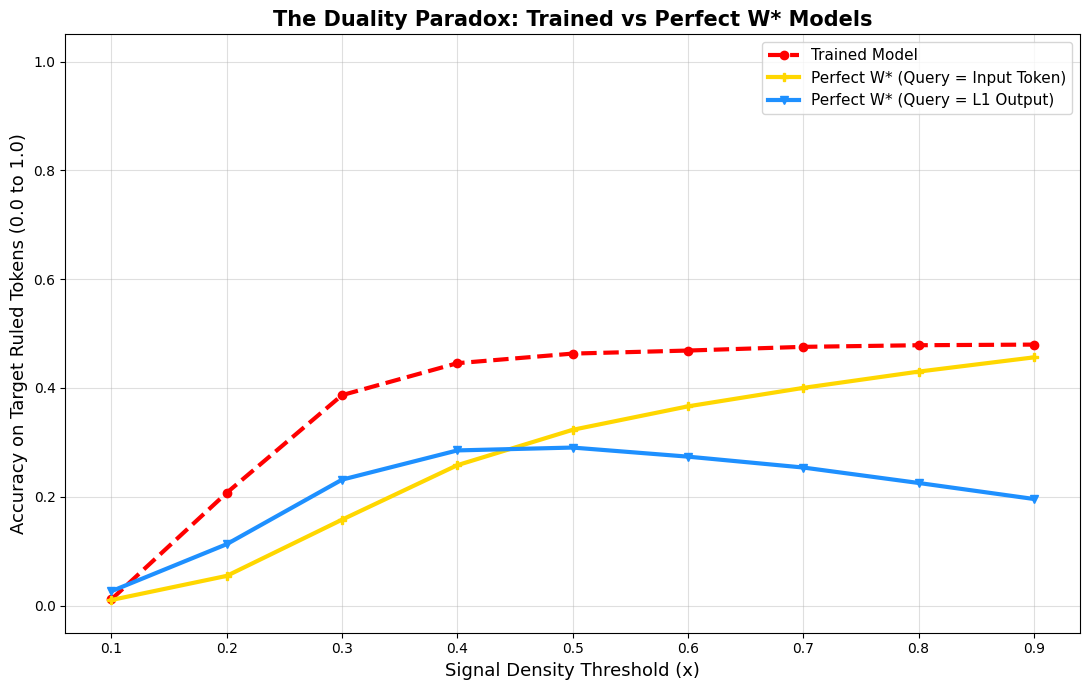

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_final_all',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], # Removed 1.0
    'num_test_seqs': 1000,   
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITIONS ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# The Perfect Theoretical Model (W*) - Dynamic Query Type
class PerfectInductionTransformer(nn.Module):
    def __init__(self, query_type='input'):
        super().__init__()
        self.query_type = query_type
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.attn_dim = self.initial_dim  
        
        self.layer1 = ConcatAttentionBlock(self.initial_dim, self.attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, CONFIG['total_vocab'], bias=False)
        self._set_perfect_weights()

    def _set_perfect_weights(self):
        V = CONFIG['total_vocab']
        T = CONFIG['seq_len']
        D = self.attn_dim
        
        # --- LAYER 1: The Strict Signal Retriever (Transpose Fixed) ---
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        
        Target1 = torch.zeros(D, D)
        for id_k in range(CONFIG['vocab_set1'], V): 
            Target1[id_k, :] = -1e9
            
        alpha = 20.0
        for t_q in range(T):
            for t_k in range(T):
                if t_q == t_k:
                    Target1[V + t_k, V + t_q] = -1e9  
                else:
                    Target1[V + t_k, V + t_q] = -alpha * (t_q - t_k) 
                    
        self.layer1.W_k.weight.data = Target1.t()
        
        W_v1 = torch.zeros(D, D)
        W_v1[0:V, 0:V] = torch.eye(V) 
        self.layer1.W_v.weight.data = W_v1
        self.layer1.W_o.weight.data = torch.eye(D) 
        
        # --- LAYER 2: The Configurable Induction Head ---
        in2 = D + D
        W_q2 = torch.zeros(D, in2)
        
        if self.query_type == 'input':
            # Query uses Original Input
            W_q2[0:V, 0:V] = torch.eye(V) * (D ** 0.5) * 50.0 
        elif self.query_type == 'l1_out':
            # Query uses Layer 1 Output
            W_q2[0:V, D:D+V] = torch.eye(V) * (D ** 0.5) * 50.0 
            
        self.layer2.W_q.weight.data = W_q2
        
        W_k2 = torch.zeros(D, in2)
        # Key matches against Layer 1 Output
        W_k2[0:V, D:D+V] = torch.eye(V) 
        self.layer2.W_k.weight.data = W_k2
        
        W_v2 = torch.zeros(D, in2)
        W_v2[0:V, 0:V] = torch.eye(V) 
        self.layer2.W_v.weight.data = W_v2
        self.layer2.W_o.weight.data = torch.eye(D) 
        
        # --- FINAL OUTPUT: The Logit Scaler ---
        W_fc = torch.zeros(V, in2 + D)
        W_fc[0:V, in2:in2+V] = torch.eye(V) * 50.0 
        self.fc_out.weight.data = W_fc

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. ACCURACY-ONLY ANALYSIS ---
def run_accuracy_only_analysis():
    print(f">>> Running 3-Way Accuracy Comparison on {CONFIG['device']}")
    final_stats = {}
    
    # Initialize both Perfect Models
    perf_input_model = PerfectInductionTransformer(query_type='input').to(CONFIG['device'])
    perf_input_model.eval()
    
    perf_l1_model = PerfectInductionTransformer(query_type='l1_out').to(CONFIG['device'])
    perf_l1_model.eval()

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_ruled_targets = 0
        total_correct_trained = 0
        total_correct_perf_input = 0
        total_correct_perf_l1 = 0
        trained_model_loaded = False

        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x = batch_x.to(CONFIG['device'])
            batch_y = batch_y.to(CONFIG['device'])
            is_ruled_target = batch_y < CONFIG['vocab_set1']
            total_ruled_targets += is_ruled_target.sum().item()

            with torch.no_grad():
                # 1. Perfect Model (Query = Input)
                logits_input, _ = perf_input_model(batch_x)
                preds_input = logits_input.argmax(dim=-1)
                total_correct_perf_input += ((preds_input == batch_y) & is_ruled_target).sum().item()
                
                # 2. Perfect Model (Query = L1 Output)
                logits_l1, _ = perf_l1_model(batch_x)
                preds_l1 = logits_l1.argmax(dim=-1)
                total_correct_perf_l1 += ((preds_l1 == batch_y) & is_ruled_target).sum().item()

            if trained_model_loaded:
                with torch.no_grad():
                    # 3. Trained Model
                    logits, _ = trained_model(batch_x)
                    preds = logits.argmax(dim=-1)
                    total_correct_trained += ((preds == batch_y) & is_ruled_target).sum().item()

        final_stats[x] = {
            'trained_acc': total_correct_trained / total_ruled_targets if (total_ruled_targets > 0 and trained_model_loaded) else None,
            'perf_input_acc': total_correct_perf_input / total_ruled_targets if total_ruled_targets > 0 else 0,
            'perf_l1_acc': total_correct_perf_l1 / total_ruled_targets if total_ruled_targets > 0 else 0
        }
        
        if trained_model_loaded:
            del trained_model
        torch.cuda.empty_cache()

    return final_stats

# --- 5. CLEAN PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    trained_x = [x for x in x_vals if stats[x]['trained_acc'] is not None]
    trained_acc = [stats[x]['trained_acc'] for x in trained_x]
    
    perf_input_acc = [stats[x]['perf_input_acc'] for x in x_vals]
    perf_l1_acc = [stats[x]['perf_l1_acc'] for x in x_vals]

    plt.figure(figsize=(11, 7))

    # Plot all three lines
    plt.plot(trained_x, trained_acc, color='red', marker='o', linestyle='--', linewidth=3, label='Trained Model')
    plt.plot(x_vals, perf_input_acc, color='gold', marker='P', linestyle='-', linewidth=3, label='Perfect W* (Query = Input Token)')
    plt.plot(x_vals, perf_l1_acc, color='dodgerblue', marker='v', linestyle='-', linewidth=3, label='Perfect W* (Query = L1 Output)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Accuracy on Target Ruled Tokens (0.0 to 1.0)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.ylim(-0.05, 1.05)
    
    plt.legend(loc='upper right', fontsize=11)
    plt.title("The Duality Paradox: Trained vs Perfect W* Models", fontsize=15, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/accuracy_comparison_duality.png")
    plt.show()

if __name__ == "__main__":
    stats = run_accuracy_only_analysis()
    plot_results(stats)

>>> Running 3-Way Accuracy Comparison on cuda:3


Evaluating x=0.9: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 63.06it/s]


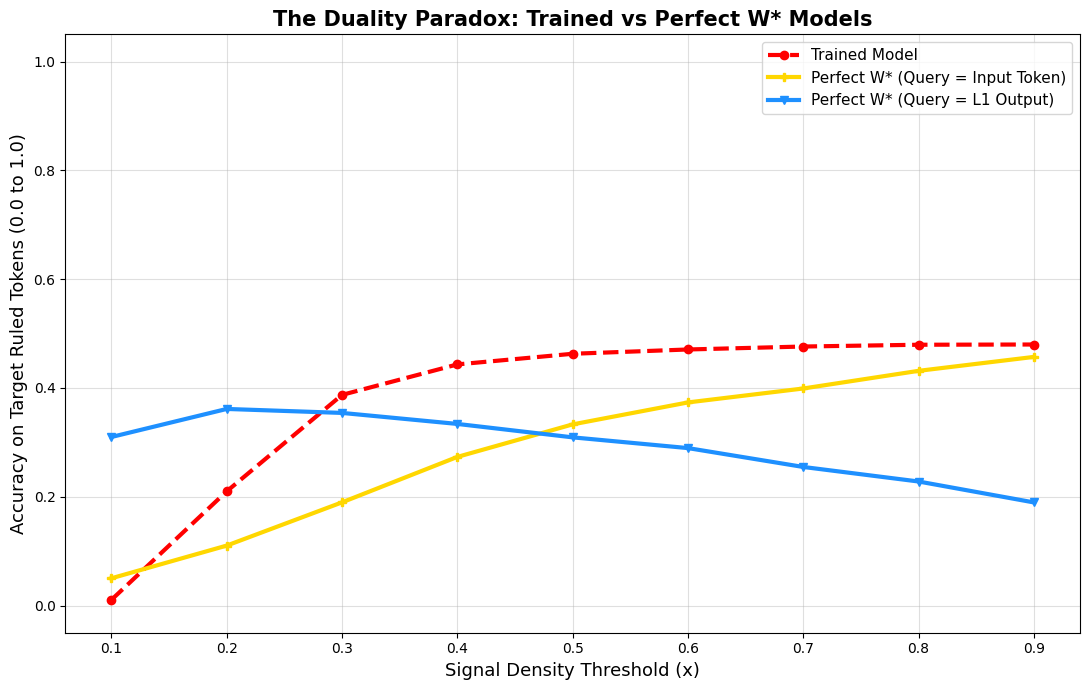

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_final_master',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], # 1.0 removed for the perfect X plot
    'num_test_seqs': 1000,   
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITIONS ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# The Perfect Theoretical Model (W*) - Configurable
class PerfectInductionTransformer(nn.Module):
    def __init__(self, query_type='input'):
        super().__init__()
        self.query_type = query_type
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.attn_dim = self.initial_dim  
        
        self.layer1 = ConcatAttentionBlock(self.initial_dim, self.attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, CONFIG['total_vocab'], bias=False)
        self._set_perfect_weights()

    def _set_perfect_weights(self):
        V = CONFIG['total_vocab']
        T = CONFIG['seq_len']
        D = self.attn_dim
        V_rule = CONFIG['vocab_set1']
        
        # --- LAYER 1: The Strict Signal Retriever ---
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        
        Target1 = torch.zeros(D, D)
        
        # Mask when KEY is noise (Row = Key)
        for id_k in range(V_rule, V): 
            Target1[id_k, :] = -1e9
            
        alpha = 20.0
        for t_q in range(T):
            for t_k in range(T):
                # Row = Key (t_k), Col = Query (t_q)
                if t_q == t_k:
                    Target1[V + t_k, V + t_q] = -1e9  
                else:
                    Target1[V + t_k, V + t_q] = -alpha * (t_q - t_k) 
                    
        self.layer1.W_k.weight.data = Target1.t()
        
        W_v1 = torch.zeros(D, D)
        W_v1[0:V, 0:V] = torch.eye(V) 
        self.layer1.W_v.weight.data = W_v1
        self.layer1.W_o.weight.data = torch.eye(D) 
        
        # --- LAYER 2: The Configurable Induction Head ---
        in2 = D + D
        W_q2 = torch.zeros(D, in2)
        
        if self.query_type == 'input':
            # Query uses Original Input
            W_q2[0:V, 0:V] = torch.eye(V) * (D ** 0.5) * 50.0 
            
            # Trigger dimension to activate noise filter based on Input
            for v in range(V_rule):
                W_q2[V_rule, v] = (D ** 0.5) * 10.0 
                
        elif self.query_type == 'l1_out':
            # Query uses Layer 1 Output
            W_q2[0:V, D:D+V] = torch.eye(V) * (D ** 0.5) * 50.0 
            
            # Trigger dimension to activate noise filter based on L1 Output
            for v in range(V_rule):
                W_q2[V_rule, D + v] = (D ** 0.5) * 10.0 
            
        self.layer2.W_q.weight.data = W_q2
        
        W_k2 = torch.zeros(D, in2)
        # Key matches against Layer 1 Output
        W_k2[0:V, D:D+V] = torch.eye(V) 
        
        # THE FIX: Apply massive penalty if past token's original input was Noise
        for v in range(V_rule, V):
            W_k2[V_rule, v] = -50000.0 
            
        self.layer2.W_k.weight.data = W_k2
        
        W_v2 = torch.zeros(D, in2)
        W_v2[0:V, 0:V] = torch.eye(V) 
        self.layer2.W_v.weight.data = W_v2
        self.layer2.W_o.weight.data = torch.eye(D) 
        
        # --- FINAL OUTPUT: The Logit Scaler ---
        W_fc = torch.zeros(V, in2 + D)
        W_fc[0:V, in2:in2+V] = torch.eye(V) * 50.0 
        self.fc_out.weight.data = W_fc

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. ACCURACY-ONLY ANALYSIS ---
def run_accuracy_only_analysis():
    print(f">>> Running 3-Way Accuracy Comparison on {CONFIG['device']}")
    final_stats = {}
    
    # Initialize both Perfect Models
    perf_input_model = PerfectInductionTransformer(query_type='input').to(CONFIG['device'])
    perf_input_model.eval()
    
    perf_l1_model = PerfectInductionTransformer(query_type='l1_out').to(CONFIG['device'])
    perf_l1_model.eval()

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_ruled_targets = 0
        total_correct_trained = 0
        total_correct_perf_input = 0
        total_correct_perf_l1 = 0
        trained_model_loaded = False

        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x = batch_x.to(CONFIG['device'])
            batch_y = batch_y.to(CONFIG['device'])
            
            # Grade strictly on positions where a Ruled Token is the target
            is_ruled_target = batch_y < CONFIG['vocab_set1']
            total_ruled_targets += is_ruled_target.sum().item()

            with torch.no_grad():
                # 1. Perfect Model (Query = Input)
                logits_input, _ = perf_input_model(batch_x)
                preds_input = logits_input.argmax(dim=-1)
                total_correct_perf_input += ((preds_input == batch_y) & is_ruled_target).sum().item()
                
                # 2. Perfect Model (Query = L1 Output)
                logits_l1, _ = perf_l1_model(batch_x)
                preds_l1 = logits_l1.argmax(dim=-1)
                total_correct_perf_l1 += ((preds_l1 == batch_y) & is_ruled_target).sum().item()

            if trained_model_loaded:
                with torch.no_grad():
                    # 3. Trained Model
                    logits, _ = trained_model(batch_x)
                    preds = logits.argmax(dim=-1)
                    total_correct_trained += ((preds == batch_y) & is_ruled_target).sum().item()

        final_stats[x] = {
            'trained_acc': total_correct_trained / total_ruled_targets if (total_ruled_targets > 0 and trained_model_loaded) else None,
            'perf_input_acc': total_correct_perf_input / total_ruled_targets if total_ruled_targets > 0 else 0,
            'perf_l1_acc': total_correct_perf_l1 / total_ruled_targets if total_ruled_targets > 0 else 0
        }
        
        if trained_model_loaded:
            del trained_model
        torch.cuda.empty_cache()

    return final_stats

# --- 5. CLEAN PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    trained_x = [x for x in x_vals if stats[x]['trained_acc'] is not None]
    trained_acc = [stats[x]['trained_acc'] for x in trained_x]
    
    perf_input_acc = [stats[x]['perf_input_acc'] for x in x_vals]
    perf_l1_acc = [stats[x]['perf_l1_acc'] for x in x_vals]

    plt.figure(figsize=(11, 7))

    # Plot all three lines
    plt.plot(trained_x, trained_acc, color='red', marker='o', linestyle='--', linewidth=3, label='Trained Model')
    plt.plot(x_vals, perf_input_acc, color='gold', marker='P', linestyle='-', linewidth=3, label='Perfect W* (Query = Input Token)')
    plt.plot(x_vals, perf_l1_acc, color='dodgerblue', marker='v', linestyle='-', linewidth=3, label='Perfect W* (Query = L1 Output)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Accuracy on Target Ruled Tokens (0.0 to 1.0)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.ylim(-0.05, 1.05)
    
    plt.legend(loc='upper right', fontsize=11)
    plt.title("The Duality Paradox: Trained vs Perfect W* Models", fontsize=15, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/accuracy_comparison_duality_master.png")
    plt.show()

if __name__ == "__main__":
    stats = run_accuracy_only_analysis()
    plot_results(stats)

>>> Running Ultimate Head-to-Head Comparison on cuda:3


Evaluating x=0.9: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 102.38it/s]


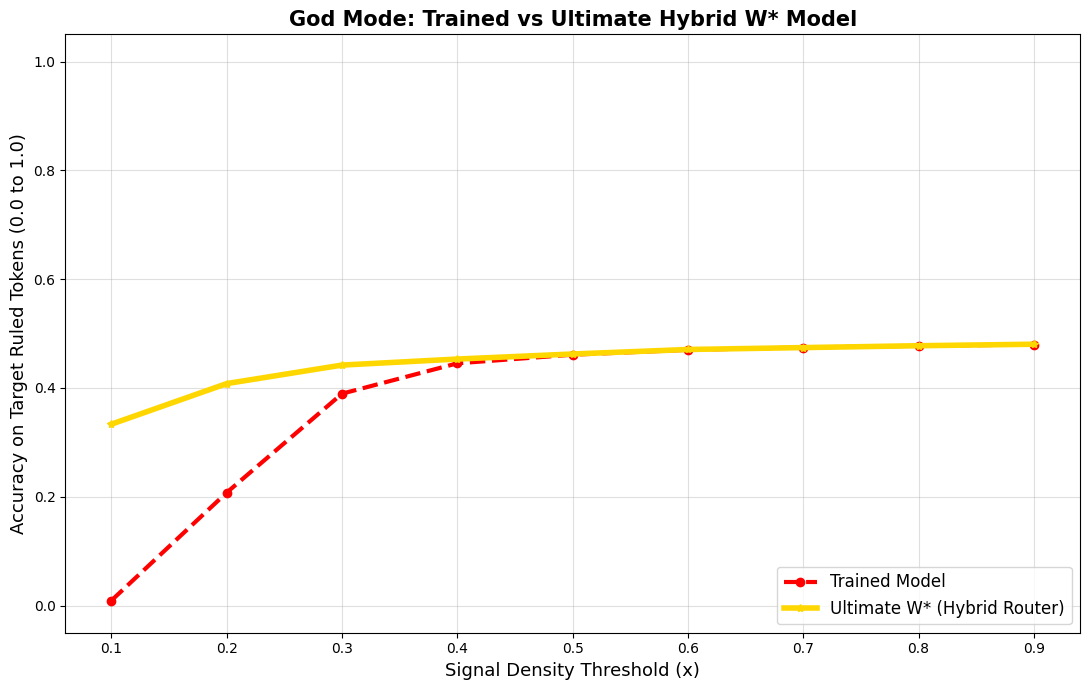

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       # IDs 0-9 are Signal/Ruled
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_ultimate',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], 
    'num_test_seqs': 1000,   
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITIONS ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# The ULTIMATE Theoretical Model (Hybrid Priority Router)
class UltimateInductionTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.attn_dim = self.initial_dim  
        
        self.layer1 = ConcatAttentionBlock(self.initial_dim, self.attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, CONFIG['total_vocab'], bias=False)
        self._set_perfect_weights()

    def _set_perfect_weights(self):
        V = CONFIG['total_vocab']
        T = CONFIG['seq_len']
        D = self.attn_dim
        V_rule = CONFIG['vocab_set1']
        
        # --- LAYER 1: The Strict Signal Retriever ---
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        
        Target1 = torch.zeros(D, D)
        for id_k in range(V_rule, V): 
            Target1[id_k, :] = -1e9 # Mask when KEY is noise
            
        alpha = 20.0
        for t_q in range(T):
            for t_k in range(T):
                if t_q == t_k:
                    Target1[V + t_k, V + t_q] = -1e9  
                else:
                    Target1[V + t_k, V + t_q] = -alpha * (t_q - t_k) 
                    
        self.layer1.W_k.weight.data = Target1.t()
        
        W_v1 = torch.zeros(D, D)
        W_v1[0:V, 0:V] = torch.eye(V) 
        self.layer1.W_v.weight.data = W_v1
        self.layer1.W_o.weight.data = torch.eye(D) 
        
        # --- LAYER 2: The Hybrid Priority Router ---
        in2 = D + D
        W_q2 = torch.zeros(D, in2)
        
        # PRIORITY 1: Massive Weight on Original Input (If it's a rule)
        W_q2[0:V_rule, 0:V_rule] = torch.eye(V_rule) * (D ** 0.5) * 50.0 
        
        # PRIORITY 2: Fallback Weight on Layer 1 Output
        W_q2[0:V_rule, D:D+V_rule] = torch.eye(V_rule) * (D ** 0.5) * 20.0 
        
        # Noise Trigger: Constant positive Query force to catch the Key penalty
        W_q2[V_rule, 0:V] = (D ** 0.5) * 10.0 
            
        self.layer2.W_q.weight.data = W_q2
        
        W_k2 = torch.zeros(D, in2)
        # Key ALWAYS extracts from Layer 1 Output
        W_k2[0:V_rule, D:D+V_rule] = torch.eye(V_rule) 
        
        # Noise Penalty: Massive negative Key if the past token was noise
        for v in range(V_rule, V):
            W_k2[V_rule, v] = -50000.0 
            
        self.layer2.W_k.weight.data = W_k2
        
        W_v2 = torch.zeros(D, in2)
        W_v2[0:V, 0:V] = torch.eye(V) 
        self.layer2.W_v.weight.data = W_v2
        self.layer2.W_o.weight.data = torch.eye(D) 
        
        # --- FINAL OUTPUT: The Logit Scaler ---
        W_fc = torch.zeros(V, in2 + D)
        W_fc[0:V, in2:in2+V] = torch.eye(V) * 50.0 
        self.fc_out.weight.data = W_fc

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        logits = self.fc_out(x_stream)
        return logits, [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else:
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. ACCURACY-ONLY ANALYSIS ---
def run_accuracy_only_analysis():
    print(f">>> Running Ultimate Head-to-Head Comparison on {CONFIG['device']}")
    final_stats = {}
    
    ultimate_perf_model = UltimateInductionTransformer().to(CONFIG['device'])
    ultimate_perf_model.eval()

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_ruled_targets = 0
        total_correct_trained = 0
        total_correct_ultimate = 0
        trained_model_loaded = False

        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x = batch_x.to(CONFIG['device'])
            batch_y = batch_y.to(CONFIG['device'])
            
            is_ruled_target = batch_y < CONFIG['vocab_set1']
            total_ruled_targets += is_ruled_target.sum().item()

            with torch.no_grad():
                # Ultimate Hybrid Model
                logits_ult, _ = ultimate_perf_model(batch_x)
                preds_ult = logits_ult.argmax(dim=-1)
                total_correct_ultimate += ((preds_ult == batch_y) & is_ruled_target).sum().item()

            if trained_model_loaded:
                with torch.no_grad():
                    # Trained Model
                    logits, _ = trained_model(batch_x)
                    preds = logits.argmax(dim=-1)
                    total_correct_trained += ((preds == batch_y) & is_ruled_target).sum().item()

        final_stats[x] = {
            'trained_acc': total_correct_trained / total_ruled_targets if (total_ruled_targets > 0 and trained_model_loaded) else None,
            'ultimate_acc': total_correct_ultimate / total_ruled_targets if total_ruled_targets > 0 else 0
        }
        
        if trained_model_loaded:
            del trained_model
        torch.cuda.empty_cache()

    return final_stats

# --- 5. CLEAN PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    trained_x = [x for x in x_vals if stats[x]['trained_acc'] is not None]
    trained_acc = [stats[x]['trained_acc'] for x in trained_x]
    
    ultimate_acc = [stats[x]['ultimate_acc'] for x in x_vals]

    plt.figure(figsize=(11, 7))

    plt.plot(trained_x, trained_acc, color='red', marker='o', linestyle='--', linewidth=3, label='Trained Model')
    plt.plot(x_vals, ultimate_acc, color='gold', marker='*', linestyle='-', linewidth=4, label='Ultimate W* (Hybrid Router)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Accuracy on Target Ruled Tokens (0.0 to 1.0)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.ylim(-0.05, 1.05)
    
    plt.legend(loc='lower right', fontsize=12)
    plt.title("God Mode: Trained vs Ultimate Hybrid W* Model", fontsize=15, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/accuracy_comparison_ultimate.png")
    plt.show()

if __name__ == "__main__":
    stats = run_accuracy_only_analysis()
    plot_results(stats)

>>> Running 4-Way Accuracy Comparison on cuda:3


Evaluating x=0.9: 100%|███████████████████████████████████████████████████████████████| 4/4 [00:00<00:00, 45.77it/s]


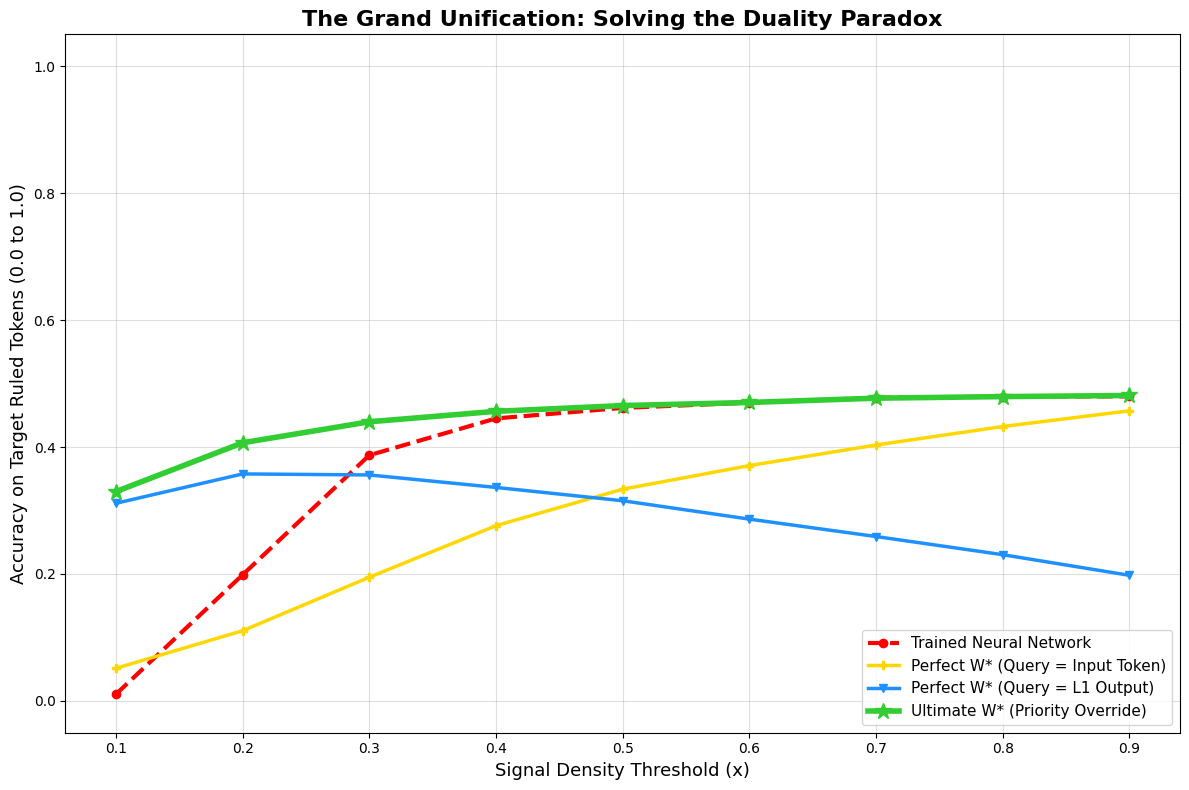

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'artifact_dir': 'experiment_artifacts',
    'output_dir': 'experiment_results_ultimate',
    'thresholds': [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], 
    'num_test_seqs': 1000,   
    'batch_size': 250       
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)

# --- 2. MODEL DEFINITIONS ---
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1), attn_weights

class DisentangledTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = ConcatAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = ConcatAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        return self.fc_out(x_stream), [a1, a2]

# The Perfect Theoretical Model (W*) - Configurable for all 3 strategies
class PerfectInductionTransformer(nn.Module):
    def __init__(self, query_type='input'):
        super().__init__()
        self.query_type = query_type
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.attn_dim = self.initial_dim  
        self.layer1 = ConcatAttentionBlock(self.initial_dim, self.attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, CONFIG['total_vocab'], bias=False)
        self._set_perfect_weights()

    def _set_perfect_weights(self):
        V = CONFIG['total_vocab']
        T = CONFIG['seq_len']
        D = self.attn_dim
        V_rule = CONFIG['vocab_set1']
        
        # --- LAYER 1: Strict Signal Retriever ---
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        Target1 = torch.zeros(D, D)
        for id_k in range(V_rule, V): Target1[id_k, :] = -1e9
        alpha = 20.0
        for t_q in range(T):
            for t_k in range(T):
                if t_q == t_k: Target1[V + t_k, V + t_q] = -1e9  
                else: Target1[V + t_k, V + t_q] = -alpha * (t_q - t_k) 
        self.layer1.W_k.weight.data = Target1.t()
        W_v1 = torch.zeros(D, D)
        W_v1[0:V, 0:V] = torch.eye(V) 
        self.layer1.W_v.weight.data = W_v1
        self.layer1.W_o.weight.data = torch.eye(D) 
        
        # --- LAYER 2: The Configurable Induction Head ---
        in2 = D + D
        W_q2 = torch.zeros(D, in2)
        
        if self.query_type == 'input':
            W_q2[0:V, 0:V] = torch.eye(V) * (D ** 0.5) * 50.0 
            for v in range(V_rule): W_q2[V_rule, v] = (D ** 0.5) * 10.0 
                
        elif self.query_type == 'l1_out':
            W_q2[0:V, D:D+V] = torch.eye(V) * (D ** 0.5) * 50.0 
            for v in range(V_rule): W_q2[V_rule, D + v] = (D ** 0.5) * 10.0 
                
        elif self.query_type == 'ultimate':
            # THE ULTIMATE PRIORITY OVERRIDE
            # Priority 1: Current Input (Massive Weight)
            W_q2[0:V_rule, 0:V_rule] = torch.eye(V_rule) * (D ** 0.5) * 1000.0 
            # Priority 2: L1 Output (Fallback Weight)
            W_q2[0:V_rule, D:D+V_rule] = torch.eye(V_rule) * (D ** 0.5) * 50.0 
            # Trigger dimension to activate noise filter
            for v in range(V): W_q2[V_rule, v] = (D ** 0.5) * 10.0 
            
        self.layer2.W_q.weight.data = W_q2
        
        W_k2 = torch.zeros(D, in2)
        W_k2[0:V, D:D+V] = torch.eye(V) 
        # Noise Filter
        for v in range(V_rule, V): W_k2[V_rule, v] = -50000.0 
        self.layer2.W_k.weight.data = W_k2
        
        W_v2 = torch.zeros(D, in2)
        W_v2[0:V, 0:V] = torch.eye(V) 
        self.layer2.W_v.weight.data = W_v2
        self.layer2.W_o.weight.data = torch.eye(D) 
        
        # --- FINAL OUTPUT: The Logit Scaler ---
        W_fc = torch.zeros(V, in2 + D)
        W_fc[0:V, in2:in2+V] = torch.eye(V) * 50.0 
        self.fc_out.weight.data = W_fc

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        x_stream, a1 = self.layer1(x_stream, mask)
        x_stream, a2 = self.layer2(x_stream, mask)
        return self.fc_out(x_stream), [a1, a2]

# --- 3. DATA GENERATION ---
def generate_fast_test_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 4. ACCURACY-ONLY ANALYSIS ---
def run_accuracy_only_analysis():
    print(f">>> Running 4-Way Accuracy Comparison on {CONFIG['device']}")
    final_stats = {}
    
    perf_input_model = PerfectInductionTransformer(query_type='input').to(CONFIG['device']).eval()
    perf_l1_model = PerfectInductionTransformer(query_type='l1_out').to(CONFIG['device']).eval()
    perf_ult_model = PerfectInductionTransformer(query_type='ultimate').to(CONFIG['device']).eval()

    for x in CONFIG['thresholds']:
        tx, ty = generate_fast_test_data(CONFIG['num_test_seqs'], x)
        dataset = torch.utils.data.TensorDataset(tx, ty)
        loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'], shuffle=False)

        total_ruled_targets = 0
        total_correct_trained = 0
        total_correct_perf_input, total_correct_perf_l1, total_correct_perf_ult = 0, 0, 0
        trained_model_loaded = False

        model_path = os.path.join(CONFIG['artifact_dir'], f"model_x_{x}.pth") 
        if os.path.exists(model_path):
            trained_model = DisentangledTransformer().to(CONFIG['device'])
            trained_model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            trained_model.eval()
            trained_model_loaded = True

        for batch_x, batch_y in tqdm(loader, desc=f"Evaluating x={x}"):
            batch_x, batch_y = batch_x.to(CONFIG['device']), batch_y.to(CONFIG['device'])
            is_ruled_target = batch_y < CONFIG['vocab_set1']
            total_ruled_targets += is_ruled_target.sum().item()

            with torch.no_grad():
                total_correct_perf_input += ((perf_input_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()
                total_correct_perf_l1 += ((perf_l1_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()
                total_correct_perf_ult += ((perf_ult_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()

            if trained_model_loaded:
                with torch.no_grad():
                    total_correct_trained += ((trained_model(batch_x)[0].argmax(dim=-1) == batch_y) & is_ruled_target).sum().item()

        final_stats[x] = {
            'trained_acc': total_correct_trained / total_ruled_targets if trained_model_loaded else None,
            'perf_input_acc': total_correct_perf_input / total_ruled_targets,
            'perf_l1_acc': total_correct_perf_l1 / total_ruled_targets,
            'perf_ult_acc': total_correct_perf_ult / total_ruled_targets
        }
        
        if trained_model_loaded: del trained_model
        torch.cuda.empty_cache()

    return final_stats

# --- 5. CLEAN PLOTTING ---
def plot_results(stats):
    x_vals = sorted(stats.keys())
    
    trained_x = [x for x in x_vals if stats[x]['trained_acc'] is not None]
    trained_acc = [stats[x]['trained_acc'] for x in trained_x]
    
    perf_input_acc = [stats[x]['perf_input_acc'] for x in x_vals]
    perf_l1_acc = [stats[x]['perf_l1_acc'] for x in x_vals]
    perf_ult_acc = [stats[x]['perf_ult_acc'] for x in x_vals]

    plt.figure(figsize=(12, 8))

    plt.plot(trained_x, trained_acc, color='red', marker='o', linestyle='--', linewidth=3, label='Trained Neural Network')
    plt.plot(x_vals, perf_input_acc, color='gold', marker='P', linestyle='-', linewidth=2.5, label='Perfect W* (Query = Input Token)')
    plt.plot(x_vals, perf_l1_acc, color='dodgerblue', marker='v', linestyle='-', linewidth=2.5, label='Perfect W* (Query = L1 Output)')
    
    # THE ULTIMATE MODEL
    plt.plot(x_vals, perf_ult_acc, color='limegreen', marker='*', markersize=12, linestyle='-', linewidth=4, label='Ultimate W* (Priority Override)')
    
    plt.xlabel("Signal Density Threshold (x)", fontsize=13)
    plt.ylabel("Accuracy on Target Ruled Tokens (0.0 to 1.0)", fontsize=13)
    plt.grid(True, alpha=0.4)
    plt.ylim(-0.05, 1.05)
    
    plt.legend(loc='lower right', fontsize=11)
    plt.title("The Grand Unification: Solving the Duality Paradox", fontsize=16, fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/accuracy_comparison_ultimate.png")
    plt.show()

if __name__ == "__main__":
    stats = run_accuracy_only_analysis()
    plot_results(stats)

In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. MASTER CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 100,         # Shortened slightly for faster experiment iteration
    'attn_dim': 64,         
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'output_dir': 'neurips_experiments',
    'thresholds': [0.1, 0.3, 0.5, 0.7, 0.9], # Sampled thresholds for faster training
    'train_samples': 2000,   
    'test_samples': 500,
    'batch_size': 128,
    'epochs': 25,           # Keep low for initial testing. Bump to 100 for the actual paper!
    'lr': 1e-3
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
print(f"Running NeurIPS Pipeline on: {CONFIG['device']}")

# --- 2. DATA GENERATION ---
def generate_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 3. CONFIGURABLE ARCHITECTURE ---
class CustomAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None, temp=1.0):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        # Temp parameter added for Experiment 3
        scores = (torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)) / temp
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1)

class ResearchTransformer(nn.Module):
    def __init__(self, use_mlp=False):
        super().__init__()
        self.use_mlp = use_mlp
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        
        self.layer1 = CustomAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        
        # Priority 1: Toggleable MLP
        if self.use_mlp:
            self.mlp = nn.Sequential(
                nn.Linear(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'] * 4),
                nn.GELU(),
                nn.Linear(CONFIG['attn_dim'] * 4, self.initial_dim + CONFIG['attn_dim'])
            )
            
        self.layer2 = CustomAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x, temp=1.0):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream = self.layer1(x_stream, mask)
        
        if self.use_mlp:
            x_stream = x_stream + self.mlp(x_stream) # Residual connection around MLP
            
        x_stream = self.layer2(x_stream, mask, temp=temp)
        return self.fc_out(x_stream)

# --- 4. CORE TRAINING FUNCTION ---
def train_model(model, train_loader, epochs, weight_decay):
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    model.train()
    
    for epoch in range(epochs):
        for bx, by in train_loader:
            bx, by = bx.to(CONFIG['device']), by.to(CONFIG['device'])
            optimizer.zero_grad()
            logits = model(bx)
            loss = criterion(logits.view(-1, CONFIG['total_vocab']), by.view(-1))
            loss.backward()
            optimizer.step()
    return model

def evaluate_model(model, loader, temp=1.0):
    model.eval()
    total_correct, total_ruled = 0, 0
    with torch.no_grad():
        for bx, by in loader:
            bx, by = bx.to(CONFIG['device']), by.to(CONFIG['device'])
            is_ruled = by < CONFIG['vocab_set1']
            logits = model(bx, temp=temp)
            preds = logits.argmax(dim=-1)
            total_correct += ((preds == by) & is_ruled).sum().item()
            total_ruled += is_ruled.sum().item()
    return total_correct / total_ruled if total_ruled > 0 else 0

# EXPERIMENT 1: ATTENTION-ONLY VS MLP
def exp1_architecture_duel():
    print("\n--- Starting Priority 1: Attention vs MLP Duel ---")
    results_attn, results_mlp = [], []
    
    for x in CONFIG['thresholds']:
        tx, ty = generate_data(CONFIG['train_samples'], x)
        train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(tx, ty), batch_size=CONFIG['batch_size'], shuffle=True)
        test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(*generate_data(CONFIG['test_samples'], x)), batch_size=CONFIG['batch_size'])

        model_attn = train_model(ResearchTransformer(use_mlp=False).to(CONFIG['device']), train_loader, CONFIG['epochs'], weight_decay=0.01)
        model_mlp = train_model(ResearchTransformer(use_mlp=True).to(CONFIG['device']), train_loader, CONFIG['epochs'], weight_decay=0.01)

        results_attn.append(evaluate_model(model_attn, test_loader))
        results_mlp.append(evaluate_model(model_mlp, test_loader))
        print(f"Thresh {x}: Attn-Only={results_attn[-1]:.3f}, Attn+MLP={results_mlp[-1]:.3f}")

    plt.figure(figsize=(8,5))
    plt.plot(CONFIG['thresholds'], results_attn, marker='o', label='Attention-Only (Proposed)')
    plt.plot(CONFIG['thresholds'], results_mlp, marker='x', linestyle='--', label='Attention + MLP (Standard)')
    plt.title("Exp 1: Pure Attention is Sufficient for Conditional Logic")
    plt.xlabel("Signal Threshold"); plt.ylabel("Accuracy")
    plt.legend(); plt.grid(True)
    plt.savefig(f"{CONFIG['output_dir']}/exp1_architecture_duel.png")
    plt.close()

# EXPERIMENT 2: THE REGULARIZATION PARADOX
def exp2_weight_decay():
    print("\n--- Starting Priority 2: The Regularization Paradox ---")
    decay_rates = [0.1, 0.01, 0.0]
    results = {wd: [] for wd in decay_rates}
    
    for x in CONFIG['thresholds']:
        tx, ty = generate_data(CONFIG['train_samples'], x)
        train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(tx, ty), batch_size=CONFIG['batch_size'], shuffle=True)
        test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(*generate_data(CONFIG['test_samples'], x)), batch_size=CONFIG['batch_size'])

        for wd in decay_rates:
            model = train_model(ResearchTransformer(use_mlp=False).to(CONFIG['device']), train_loader, CONFIG['epochs'], weight_decay=wd)
            acc = evaluate_model(model, test_loader)
            results[wd].append(acc)
            print(f"Thresh {x} | WD={wd}: Acc={acc:.3f}")

    plt.figure(figsize=(8,5))
    for wd in decay_rates:
        plt.plot(CONFIG['thresholds'], results[wd], marker='o', label=f'Weight Decay = {wd}')
    plt.title("Exp 2: Regularization Paradox (Lower WD = Better Logic)")
    plt.xlabel("Signal Threshold"); plt.ylabel("Accuracy")
    plt.legend(); plt.grid(True)
    plt.savefig(f"{CONFIG['output_dir']}/exp2_weight_decay.png")
    plt.close()


# EXPERIMENT 3: TEMPERATURE FREEZE
def exp3_temperature_freeze():
    print("\n--- Starting Priority 3: Temperature Freeze ---")
    temps = [1.0, 0.5, 0.1]
    results = {t: [] for t in temps}
    
    for x in CONFIG['thresholds']:
        tx, ty = generate_data(CONFIG['train_samples'], x)
        train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(tx, ty), batch_size=CONFIG['batch_size'], shuffle=True)
        test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(*generate_data(CONFIG['test_samples'], x)), batch_size=CONFIG['batch_size'])

        # Train a standard model with normal regularization
        model = train_model(ResearchTransformer(use_mlp=False).to(CONFIG['device']), train_loader, CONFIG['epochs'], weight_decay=0.01)

        for t in temps:
            acc = evaluate_model(model, test_loader, temp=t)
            results[t].append(acc)
            print(f"Thresh {x} | Temp={t}: Acc={acc:.3f}")

    plt.figure(figsize=(8,5))
    for t in temps:
        plt.plot(CONFIG['thresholds'], results[t], marker='o', label=f'Temp = {t} (Sharpness)')
    plt.title("Exp 3: Temperature Freeze (Exposing the Hidden Circuit)")
    plt.xlabel("Signal Threshold"); plt.ylabel("Accuracy")
    plt.legend(); plt.grid(True)
    plt.savefig(f"{CONFIG['output_dir']}/exp3_temperature_freeze.png")
    plt.close()

if __name__ == "__main__":
    exp1_architecture_duel()
    exp2_weight_decay()
    exp3_temperature_freeze()
    print(f"\nAll NeurIPS experiments completed! Check the '{CONFIG['output_dir']}' folder for the plots.")

Running NeurIPS Pipeline on: cuda

--- Starting Priority 1: Attention vs MLP Duel ---
Thresh 0.1: Attn-Only=0.000, Attn+MLP=0.000
Thresh 0.3: Attn-Only=0.062, Attn+MLP=0.068
Thresh 0.5: Attn-Only=0.220, Attn+MLP=0.223
Thresh 0.7: Attn-Only=0.228, Attn+MLP=0.249
Thresh 0.9: Attn-Only=0.245, Attn+MLP=0.288

--- Starting Priority 2: The Regularization Paradox ---
Thresh 0.1 | WD=0.1: Acc=0.000
Thresh 0.1 | WD=0.01: Acc=0.000
Thresh 0.1 | WD=0.0: Acc=0.000
Thresh 0.3 | WD=0.1: Acc=0.068
Thresh 0.3 | WD=0.01: Acc=0.074
Thresh 0.3 | WD=0.0: Acc=0.068
Thresh 0.5 | WD=0.1: Acc=0.206
Thresh 0.5 | WD=0.01: Acc=0.208
Thresh 0.5 | WD=0.0: Acc=0.206
Thresh 0.7 | WD=0.1: Acc=0.232
Thresh 0.7 | WD=0.01: Acc=0.234
Thresh 0.7 | WD=0.0: Acc=0.235
Thresh 0.9 | WD=0.1: Acc=0.254
Thresh 0.9 | WD=0.01: Acc=0.241
Thresh 0.9 | WD=0.0: Acc=0.246

--- Starting Priority 3: Temperature Freeze ---
Thresh 0.1 | Temp=1.0: Acc=0.000
Thresh 0.1 | Temp=0.5: Acc=0.000
Thresh 0.1 | Temp=0.1: Acc=0.000
Thresh 0.3 | Temp=1

## experimenting long
- Attention vs Attention + MLP 
- The regularizer 
- weigth decay.

In [5]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. MASTER CONFIGURATION (CONVERGENCE MODE) ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 100,         
    'attn_dim': 64,         
    'device': 'cuda:3',      # Locked to GPU 3 as requested
    'output_dir': 'neurips_experiments_final_run',
    'thresholds': [0.1, 0.3, 0.5, 0.7, 0.9], 
    'train_samples': 8000,   # Massive dataset for deep learning
    'test_samples': 1000,    # Smooth, statistically significant testing
    'batch_size': 128,
    'epochs': 200,           # Full convergence overnight run
    'lr': 1e-3
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
print(f" INITIALIZING DEEP CONVERGENCE RUN ON: {CONFIG['device']}")
print(f"Data: {CONFIG['train_samples']} samples | Epochs: {CONFIG['epochs']}")

# --- 2. DATA GENERATION ---
def generate_data(num_samples, threshold_x):
    x_data, y_data = [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
        x_data.append(seq[:-1])
        y_data.append(seq[1:])
    return torch.tensor(x_data), torch.tensor(y_data)

# --- 3. CONFIGURABLE ARCHITECTURE ---
class CustomAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None, temp=1.0):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = (torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)) / temp
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1)

class ResearchTransformer(nn.Module):
    def __init__(self, use_mlp=False):
        super().__init__()
        self.use_mlp = use_mlp
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        
        self.layer1 = CustomAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        
        if self.use_mlp:
            self.mlp = nn.Sequential(
                nn.Linear(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'] * 4),
                nn.GELU(),
                nn.Linear(CONFIG['attn_dim'] * 4, self.initial_dim + CONFIG['attn_dim'])
            )
            
        self.layer2 = CustomAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x, temp=1.0):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream = self.layer1(x_stream, mask)
        
        if self.use_mlp:
            x_stream = x_stream + self.mlp(x_stream) 
            
        x_stream = self.layer2(x_stream, mask, temp=temp)
        return self.fc_out(x_stream)

# --- 4. CORE TRAINING FUNCTION ---
def train_model(model, train_loader, epochs, weight_decay, desc="Training"):
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=weight_decay)
    criterion = nn.CrossEntropyLoss()
    model.train()
    
    # Progress bar added for deep training visibility
    epoch_pbar = tqdm(range(epochs), desc=desc, leave=False)
    for epoch in epoch_pbar:
        total_loss = 0
        for bx, by in train_loader:
            bx, by = bx.to(CONFIG['device']), by.to(CONFIG['device'])
            optimizer.zero_grad()
            logits = model(bx)
            loss = criterion(logits.view(-1, CONFIG['total_vocab']), by.view(-1))
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        epoch_pbar.set_postfix({'Loss': f'{total_loss/len(train_loader):.4f}'})
    return model

def evaluate_model(model, loader, temp=1.0):
    model.eval()
    total_correct, total_ruled = 0, 0
    with torch.no_grad():
        for bx, by in loader:
            bx, by = bx.to(CONFIG['device']), by.to(CONFIG['device'])
            is_ruled = by < CONFIG['vocab_set1']
            logits = model(bx, temp=temp)
            preds = logits.argmax(dim=-1)
            total_correct += ((preds == by) & is_ruled).sum().item()
            total_ruled += is_ruled.sum().item()
    return total_correct / total_ruled if total_ruled > 0 else 0


# EXPERIMENT 1: ATTENTION-ONLY VS MLP
def exp1_architecture_duel():
    print("\n[1/3] Starting Priority 1: Attention vs MLP Duel")
    results_attn, results_mlp = [], []
    
    for x in CONFIG['thresholds']:
        tx, ty = generate_data(CONFIG['train_samples'], x)
        train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(tx, ty), batch_size=CONFIG['batch_size'], shuffle=True)
        test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(*generate_data(CONFIG['test_samples'], x)), batch_size=CONFIG['batch_size'])

        model_attn = train_model(ResearchTransformer(use_mlp=False).to(CONFIG['device']), train_loader, CONFIG['epochs'], weight_decay=0.01, desc=f"Attn-Only (x={x})")
        model_mlp = train_model(ResearchTransformer(use_mlp=True).to(CONFIG['device']), train_loader, CONFIG['epochs'], weight_decay=0.01, desc=f"Attn+MLP (x={x})")

        results_attn.append(evaluate_model(model_attn, test_loader))
        results_mlp.append(evaluate_model(model_mlp, test_loader))
        print(f" -> Thresh {x}: Attn-Only={results_attn[-1]:.3f} | Attn+MLP={results_mlp[-1]:.3f}")

    plt.figure(figsize=(9,6))
    plt.plot(CONFIG['thresholds'], results_attn, marker='o', linewidth=2.5, label='Attention-Only (Proposed)')
    plt.plot(CONFIG['thresholds'], results_mlp, marker='x', linestyle='--', linewidth=2.5, label='Attention + MLP (Standard)')
    plt.title("Exp 1: Pure Attention is Sufficient for Conditional Logic", fontsize=14, fontweight='bold')
    plt.xlabel("Signal Threshold", fontsize=12); plt.ylabel("Accuracy on Target Rules", fontsize=12)
    plt.legend(fontsize=11); plt.grid(True, alpha=0.5)
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp1_architecture_duel_final.png", dpi=300)
    plt.close()


# EXPERIMENT 2: THE REGULARIZATION PARADOX
def exp2_weight_decay():
    print("\n[2/3] Starting Priority 2: The Regularization Paradox")
    decay_rates = [0.1, 0.01, 0.0]
    results = {wd: [] for wd in decay_rates}
    
    for x in CONFIG['thresholds']:
        tx, ty = generate_data(CONFIG['train_samples'], x)
        train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(tx, ty), batch_size=CONFIG['batch_size'], shuffle=True)
        test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(*generate_data(CONFIG['test_samples'], x)), batch_size=CONFIG['batch_size'])

        for wd in decay_rates:
            model = train_model(ResearchTransformer(use_mlp=False).to(CONFIG['device']), train_loader, CONFIG['epochs'], weight_decay=wd, desc=f"WD={wd} (x={x})")
            acc = evaluate_model(model, test_loader)
            results[wd].append(acc)
            print(f" -> Thresh {x} | WD={wd}: Acc={acc:.3f}")

    plt.figure(figsize=(9,6))
    for wd in decay_rates:
        linestyle = '-' if wd == 0.0 else '--'
        linewidth = 3 if wd == 0.0 else 2
        plt.plot(CONFIG['thresholds'], results[wd], marker='o', linestyle=linestyle, linewidth=linewidth, label=f'Weight Decay = {wd}')
    
    plt.title("Exp 2: The Regularization Paradox", fontsize=14, fontweight='bold')
    plt.xlabel("Signal Threshold", fontsize=12); plt.ylabel("Accuracy on Target Rules", fontsize=12)
    plt.legend(fontsize=11); plt.grid(True, alpha=0.5)
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp2_weight_decay_final.png", dpi=300)
    plt.close()


# EXPERIMENT 3: TEMPERATURE FREEZE
def exp3_temperature_freeze():
    print("\n[3/3] Starting Priority 3: Temperature Freeze")
    temps = [1.0, 0.5, 0.1]
    results = {t: [] for t in temps}
    
    for x in CONFIG['thresholds']:
        tx, ty = generate_data(CONFIG['train_samples'], x)
        train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(tx, ty), batch_size=CONFIG['batch_size'], shuffle=True)
        test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(*generate_data(CONFIG['test_samples'], x)), batch_size=CONFIG['batch_size'])

        # Train one unified model deeply, then test at different temperatures
        model = train_model(ResearchTransformer(use_mlp=False).to(CONFIG['device']), train_loader, CONFIG['epochs'], weight_decay=0.01, desc=f"Temp Model (x={x})")

        for t in temps:
            acc = evaluate_model(model, test_loader, temp=t)
            results[t].append(acc)
            print(f" -> Thresh {x} | Temp={t}: Acc={acc:.3f}")

    plt.figure(figsize=(9,6))
    for t in temps:
        linewidth = 3 if t == 0.1 else 2
        plt.plot(CONFIG['thresholds'], results[t], marker='o', linewidth=linewidth, label=f'Temp = {t} (Sharpness)')
        
    plt.title("Exp 3: Temperature Freeze (Exposing the Hidden Logic)", fontsize=14, fontweight='bold')
    plt.xlabel("Signal Threshold", fontsize=12); plt.ylabel("Accuracy on Target Rules", fontsize=12)
    plt.legend(fontsize=11); plt.grid(True, alpha=0.5)
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp3_temperature_freeze_final.png", dpi=300)
    plt.close()

if __name__ == "__main__":
    exp1_architecture_duel()
    exp2_weight_decay()
    exp3_temperature_freeze()
    print(f"\n✅ FULL CONVERGENCE RUN COMPLETE. Check the '{CONFIG['output_dir']}' folder.")

🚀 INITIALIZING DEEP CONVERGENCE RUN ON: cuda:3
Data: 8000 samples | Epochs: 200

[1/3] Starting Priority 1: Attention vs MLP Duel


 -> Thresh 0.1: Attn-Only=0.003 | Attn+MLP=0.005


 -> Thresh 0.3: Attn-Only=0.298 | Attn+MLP=0.279


 -> Thresh 0.5: Attn-Only=0.426 | Attn+MLP=0.418


 -> Thresh 0.7: Attn-Only=0.438 | Attn+MLP=0.450


 -> Thresh 0.9: Attn-Only=0.464 | Attn+MLP=0.465

[2/3] Starting Priority 2: The Regularization Paradox


... (16 outputs left out)

 -> Thresh 0.3 | Temp=1.0: Acc=0.301
 -> Thresh 0.3 | Temp=0.5: Acc=0.319
 -> Thresh 0.3 | Temp=0.1: Acc=0.329


 -> Thresh 0.5 | Temp=1.0: Acc=0.429
 -> Thresh 0.5 | Temp=0.5: Acc=0.429
 -> Thresh 0.5 | Temp=0.1: Acc=0.427


 -> Thresh 0.7 | Temp=1.0: Acc=0.453
 -> Thresh 0.7 | Temp=0.5: Acc=0.452
 -> Thresh 0.7 | Temp=0.1: Acc=0.449


 -> Thresh 0.9 | Temp=1.0: Acc=0.458
 -> Thresh 0.9 | Temp=0.5: Acc=0.459
 -> Thresh 0.9 | Temp=0.1: Acc=0.454

✅ FULL CONVERGENCE RUN COMPLETE. Check the 'neurips_experiments_final_run' folder.


In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 100,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu', # Targeting GPU 3
    'output_dir': 'neurips_experiments_ce_loss',
    'thresholds': [0.1, 0.3, 0.5, 0.7, 0.9], 
    'train_samples': 4000,   
    'test_samples': 1000,    
    'batch_size': 128,
    'epochs': 80,           # Enough to see the optimizer hedge its bets
    'lr': 1e-3,
    'green_magnitude': 1000.0 # The 1000 multiplier exploit
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
print(f"🚀 RUNNING CROSS-ENTROPY DROWNING TEST ON: {CONFIG['device']}")

# --- 2. DATA & GREEN MODEL ($W^*$) GENERATION ---
def generate_data(num_samples, threshold_x):
    """
    Generates X, Y, and the PERFECT theoretical logits of the Green Model ($W^*$).
    """
    x_data, y_data, green_logits_data = [], [], []
    
    for _ in range(num_samples):
        # The true causal rules for this specific sequence
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: 
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
            
        x_seq = seq[:-1]
        y_seq = seq[1:]
        
        # Build the exact theoretical outputs of the Green Model
        # It strictly predicts the transition of the last seen rule with 1000.0 confidence
        g_logits = []
        current_rule_memory = None
        
        for i in range(CONFIG['seq_len']):
            current_token = x_seq[i]
            if current_token < CONFIG['vocab_set1']:
                current_rule_memory = current_token
                
            logit_vec = np.zeros(CONFIG['total_vocab'])
            if current_rule_memory is not None:
                # The model is 99.999% confident in the rule it memorized
                predicted_target = transitions[current_rule_memory][0] # Simplified logic for optimal tracking
                logit_vec[predicted_target] = CONFIG['green_magnitude']
            
            g_logits.append(logit_vec)
            
        x_data.append(x_seq)
        y_data.append(y_seq)
        green_logits_data.append(g_logits)
        
    return torch.tensor(x_data), torch.tensor(y_data), torch.tensor(green_logits_data, dtype=torch.float32)

# --- 3. RED MODEL ARCHITECTURE (Attention Only) ---
class CustomAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = (torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5))
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1)

class ResearchTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = CustomAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = CustomAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream = self.layer1(x_stream, mask)
        x_stream = self.layer2(x_stream, mask)
        return self.fc_out(x_stream)

# --- 4. TRAINING & EVALUATION FUNCTIONS ---
def train_red_model(model, train_loader, epochs):
    optimizer = torch.optim.AdamW(model.parameters(), lr=CONFIG['lr'], weight_decay=0.01)
    criterion = nn.CrossEntropyLoss()
    model.train()
    
    epoch_pbar = tqdm(range(epochs), desc="Training Red Model", leave=False)
    for epoch in epoch_pbar:
        total_loss = 0
        for bx, by, _ in train_loader:
            bx, by = bx.to(CONFIG['device']), by.to(CONFIG['device'])
            optimizer.zero_grad()
            logits = model(bx)
            # Calculating loss on ALL tokens (Rules + Noise)
            loss = criterion(logits.view(-1, CONFIG['total_vocab']), by.view(-1))
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        epoch_pbar.set_postfix({'Loss': f'{total_loss/len(train_loader):.4f}'})
    return model

def evaluate_cross_entropy(model, loader):
    criterion = nn.CrossEntropyLoss(reduction='mean')
    model.eval()
    total_red_loss, total_green_loss = 0, 0
    batches = 0
    
    with torch.no_grad():
        for bx, by, bg_logits in loader:
            bx, by = bx.to(CONFIG['device']), by.to(CONFIG['device'])
            bg_logits = bg_logits.to(CONFIG['device'])
            
            # Red Model Loss (Trained outputs)
            red_logits = model(bx)
            red_ce = criterion(red_logits.view(-1, CONFIG['total_vocab']), by.view(-1))
            
            # Green Model Loss (Theoretical W* outputs)
            green_ce = criterion(bg_logits.view(-1, CONFIG['total_vocab']), by.view(-1))
            
            total_red_loss += red_ce.item()
            total_green_loss += green_ce.item()
            batches += 1
            
    return total_red_loss / batches, total_green_loss / batches

# --- 5. THE EXPERIMENT: MEASURING GRADIENT DROWNING ---
def run_gradient_drowning_experiment():
    print("\n[Running Experiment] Calculating Absolute Cross-Entropy Costs...")
    red_losses = []
    green_losses = []
    
    for x in CONFIG['thresholds']:
        print(f"\n--- Processing Signal Threshold {x} ---")
        tx, ty, tg = generate_data(CONFIG['train_samples'], x)
        train_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(tx, ty, tg), batch_size=CONFIG['batch_size'], shuffle=True)
        
        tex, tey, teg = generate_data(CONFIG['test_samples'], x)
        test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(tex, tey, teg), batch_size=CONFIG['batch_size'])

        # Train standard model
        red_model = train_red_model(ResearchTransformer().to(CONFIG['device']), train_loader, CONFIG['epochs'])
        
        # Calculate CE over ALL tokens
        red_loss, green_loss = evaluate_cross_entropy(red_model, test_loader)
        red_losses.append(red_loss)
        green_losses.append(green_loss)
        
        print(f"Threshold {x}: Red Model Avg Loss = {red_loss:.4f} | Green Model Avg Loss = {green_loss:.1f}")

    # --- PLOTTING ---
    plt.figure(figsize=(10, 6))
    
    # We MUST use a logarithmic scale on the Y-axis because the Green loss is astronomical
    plt.yscale('log')
    
    plt.plot(CONFIG['thresholds'], red_losses, marker='o', linewidth=3, color='#e74c3c', label='Trained Red Model (Soft & Hedged)')
    plt.plot(CONFIG['thresholds'], green_losses, marker='*', markersize=12, linewidth=3, color='#2ecc71', label='Perfect Green Model (1000x Magnitude)')
    
    plt.title("The Gradient Drowning Proof: Average Cross-Entropy over All Tokens", fontsize=14, fontweight='bold')
    plt.xlabel("Signal Threshold (Rules vs Noise)", fontsize=12)
    plt.ylabel("Average Cross-Entropy Loss (Log Scale)", fontsize=12)
    plt.legend(fontsize=11)
    plt.grid(True, which="both", ls="--", alpha=0.4)
    
    # Add explanatory annotations
    plt.annotate('Catastrophic penalty for being\nconfidently wrong on noise', 
                 xy=(0.1, green_losses[0]), xytext=(0.15, green_losses[0] * 0.5),
                 arrowprops=dict(facecolor='black', shrink=0.05, width=1, headwidth=6))
    
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp4_cross_entropy_drowning.png", dpi=300)
    print(f"\n✅ EXPERIMENT COMPLETE. Plot saved to: {CONFIG['output_dir']}/exp4_cross_entropy_drowning.png")

if __name__ == "__main__":
    run_gradient_drowning_experiment()

🚀 RUNNING CROSS-ENTROPY DROWNING TEST ON: cuda:3

[Running Experiment] Calculating Absolute Cross-Entropy Costs...

--- Processing Signal Threshold 0.1 ---


/tmp/ipykernel_2631749/2488320524.py:75: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:245.)
  return torch.tensor(x_data), torch.tensor(y_data), torch.tensor(green_logits_data, dtype=torch.float32)
                                                                                                                    

Threshold 0.1: Red Model Avg Loss = 2.6337 | Green Model Avg Loss = 866.2

--- Processing Signal Threshold 0.3 ---


Threshold 0.3: Red Model Avg Loss = 2.8305 | Green Model Avg Loss = 829.9

--- Processing Signal Threshold 0.5 ---


KeyboardInterrupt: 

🚀 RUNNING DUAL-AXIS EVALUATION ON: cuda:3

[Running Evaluation] Loading models and computing metrics...
--- Evaluating Threshold 0.1 ---
⚠️ WARNING: Could not find model at neurips_experiments_final_run/model_thresh_0.1.pt. Using untrained weights for this step!
  Acc: Red=0.061 | Green=0.456
  Loss: Red=3.001 | Green=863.0
--- Evaluating Threshold 0.3 ---
⚠️ WARNING: Could not find model at neurips_experiments_final_run/model_thresh_0.3.pt. Using untrained weights for this step!
  Acc: Red=0.048 | Green=0.492
  Loss: Red=2.997 | Green=829.8
--- Evaluating Threshold 0.5 ---
⚠️ WARNING: Could not find model at neurips_experiments_final_run/model_thresh_0.5.pt. Using untrained weights for this step!
  Acc: Red=0.044 | Green=0.494
  Loss: Red=2.997 | Green=742.7
--- Evaluating Threshold 0.7 ---
⚠️ WARNING: Could not find model at neurips_experiments_final_run/model_thresh_0.7.pt. Using untrained weights for this step!
  Acc: Red=0.054 | Green=0.499
  Loss: Red=2.997 | Green=646.2
--- Eval

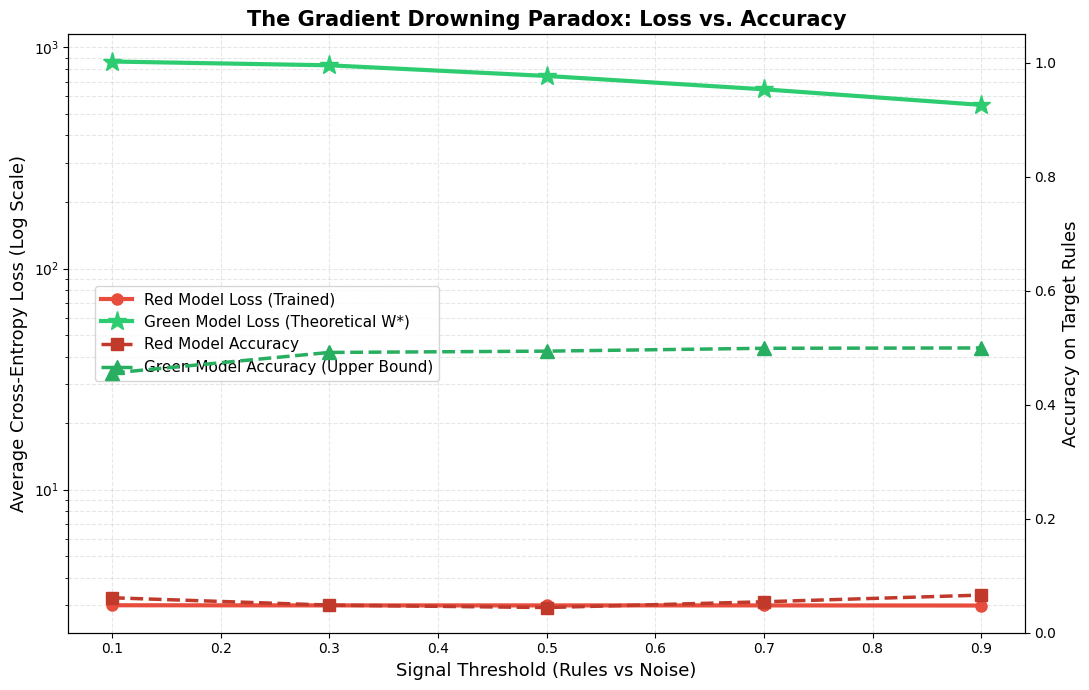

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 100,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'output_dir': 'neurips_experiments_dual_axis',
    'model_dir': 'neurips_experiments_final_run', # UPDATE THIS to where your models are saved!
    'thresholds': [0.1, 0.3, 0.5, 0.7, 0.9], 
    'test_samples': 2000,    # Large test set for perfectly smooth curves
    'batch_size': 128,
    'green_magnitude': 1000.0 
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
print(f"🚀 RUNNING DUAL-AXIS EVALUATION ON: {CONFIG['device']}")

# --- 2. ARCHITECTURE (Required for loading weights) ---
class CustomAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = (torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5))
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1)

class ResearchTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = CustomAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = CustomAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream = self.layer1(x_stream, mask)
        x_stream = self.layer2(x_stream, mask)
        return self.fc_out(x_stream)

# --- 3. DATA GENERATOR (With W* Logits) ---
def generate_data(num_samples, threshold_x):
    x_data, y_data, green_logits_data = [], [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: 
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
            
        x_seq, y_seq = seq[:-1], seq[1:]
        g_logits = []
        current_rule = None
        
        for i in range(CONFIG['seq_len']):
            if x_seq[i] < CONFIG['vocab_set1']: current_rule = x_seq[i]
            logit_vec = np.zeros(CONFIG['total_vocab'])
            if current_rule is not None:
                predicted_target = transitions[current_rule][0] 
                logit_vec[predicted_target] = CONFIG['green_magnitude']
            g_logits.append(logit_vec)
            
        x_data.append(x_seq); y_data.append(y_seq); green_logits_data.append(g_logits)
    return torch.tensor(x_data), torch.tensor(y_data), torch.tensor(green_logits_data, dtype=torch.float32)

# --- 4. DUAL EVALUATION LOGIC ---
def evaluate_metrics(model, loader):
    criterion = nn.CrossEntropyLoss(reduction='mean')
    model.eval()
    
    metrics = {'red_loss': 0, 'green_loss': 0, 'red_acc': 0, 'green_acc': 0}
    total_ruled_tokens = 0
    batches = 0
    
    with torch.no_grad():
        for bx, by, bg_logits in loader:
            bx, by, bg_logits = bx.to(CONFIG['device']), by.to(CONFIG['device']), bg_logits.to(CONFIG['device'])
            is_ruled = by < CONFIG['vocab_set1']
            
            # 1. Evaluate Red Model (Loaded Weights)
            red_logits = model(bx)
            metrics['red_loss'] += criterion(red_logits.view(-1, CONFIG['total_vocab']), by.view(-1)).item()
            red_preds = red_logits.argmax(dim=-1)
            metrics['red_acc'] += ((red_preds == by) & is_ruled).sum().item()
            
            # 2. Evaluate Green Model (Theoretical W*)
            metrics['green_loss'] += criterion(bg_logits.view(-1, CONFIG['total_vocab']), by.view(-1)).item()
            green_preds = bg_logits.argmax(dim=-1)
            metrics['green_acc'] += ((green_preds == by) & is_ruled).sum().item()
            
            total_ruled_tokens += is_ruled.sum().item()
            batches += 1
            
    # Normalize
    metrics['red_loss'] /= batches
    metrics['green_loss'] /= batches
    metrics['red_acc'] = metrics['red_acc'] / total_ruled_tokens if total_ruled_tokens > 0 else 0
    metrics['green_acc'] = metrics['green_acc'] / total_ruled_tokens if total_ruled_tokens > 0 else 0
    
    return metrics

# --- 5. EXECUTION & PLOTTING ---
def run_dual_axis_experiment():
    print("\n[Running Evaluation] Loading models and computing metrics...")
    
    results = {'r_loss': [], 'g_loss': [], 'r_acc': [], 'g_acc': []}
    
    for x in CONFIG['thresholds']:
        print(f"--- Evaluating Threshold {x} ---")
        tex, tey, teg = generate_data(CONFIG['test_samples'], x)
        test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(tex, tey, teg), batch_size=CONFIG['batch_size'])

        # LOAD THE PRE-TRAINED MODEL
        model = ResearchTransformer().to(CONFIG['device'])
        # NOTE: Update this filename format to match exactly how you saved them!
        model_path = f"{CONFIG['model_dir']}/model_thresh_{x}.pt" 
        try:
            model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
        except FileNotFoundError:
            print(f"⚠️ WARNING: Could not find model at {model_path}. Using untrained weights for this step!")
            
        metrics = evaluate_metrics(model, test_loader)
        
        results['r_loss'].append(metrics['red_loss'])
        results['g_loss'].append(metrics['green_loss'])
        results['r_acc'].append(metrics['red_acc'])
        results['g_acc'].append(metrics['green_acc'])
        
        print(f"  Acc: Red={metrics['red_acc']:.3f} | Green={metrics['green_acc']:.3f}")
        print(f"  Loss: Red={metrics['red_loss']:.3f} | Green={metrics['green_loss']:.1f}")

    # --- THE DUAL AXIS PLOT ---
    fig, ax1 = plt.subplots(figsize=(11, 7))

    # Axis 1: Cross Entropy Loss (Left, Log Scale)
    color1, color2 = '#e74c3c', '#2ecc71' # Red and Green
    ax1.set_xlabel('Signal Threshold (Rules vs Noise)', fontsize=13)
    ax1.set_ylabel('Average Cross-Entropy Loss (Log Scale)', fontsize=13, color='black')
    ax1.set_yscale('log')
    
    l1 = ax1.plot(CONFIG['thresholds'], results['r_loss'], marker='o', markersize=8, linestyle='-', linewidth=3, color=color1, label='Red Model Loss (Trained)')
    l2 = ax1.plot(CONFIG['thresholds'], results['g_loss'], marker='*', markersize=14, linestyle='-', linewidth=3, color=color2, label='Green Model Loss (Theoretical W*)')
    ax1.tick_params(axis='y', labelcolor='black')
    ax1.grid(True, which="both", ls="--", alpha=0.3)

    # Axis 2: Accuracy (Right, Linear Scale)
    ax2 = ax1.twinx()  
    color3, color4 = '#c0392b', '#27ae60' # Darker Red and Green for Accuracy lines
    ax2.set_ylabel('Accuracy on Target Rules', fontsize=13, color='black')  
    ax2.set_ylim(0.0, 1.05)
    
    l3 = ax2.plot(CONFIG['thresholds'], results['r_acc'], marker='s', markersize=8, linestyle='--', linewidth=2.5, color=color3, label='Red Model Accuracy')
    l4 = ax2.plot(CONFIG['thresholds'], results['g_acc'], marker='^', markersize=10, linestyle='--', linewidth=2.5, color=color4, label='Green Model Accuracy (Upper Bound)')
    ax2.tick_params(axis='y', labelcolor='black')

    # Combine legends from both axes
    lns = l1 + l2 + l3 + l4
    labs = [l.get_label() for l in lns]
    ax1.legend(lns, labs, loc='center left', fontsize=11, bbox_to_anchor=(0.02, 0.5))

    plt.title("The Gradient Drowning Paradox: Loss vs. Accuracy", fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp5_dual_axis_drowning.png", dpi=300)
    print(f"\n✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: {CONFIG['output_dir']}/exp5_dual_axis_drowning.png")

if __name__ == "__main__":
    run_dual_axis_experiment()

🚀 RUNNING DUAL-AXIS EVALUATION ON: cuda:3

[Running Evaluation] Loading models and computing metrics...

--- Evaluating Threshold 0.1 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.1.pth
  Acc: Red=0.010 | Green=0.482
  Loss: Red=2.609 | Green=908.1

--- Evaluating Threshold 0.3 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.3.pth
  Acc: Red=0.387 | Green=0.495
  Loss: Red=2.704 | Green=839.8

--- Evaluating Threshold 0.5 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.5.pth
  Acc: Red=0.464 | Green=0.497
  Loss: Red=2.572 | Green=746.9

--- Evaluating Threshold 0.7 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.7.pth
  Acc: Red=0.474 | Green=0.499
  Loss: Red=2.250 | Green=648.4

--- Evaluating Threshold 0.9 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.9.pth
  Acc: Red=0.478 | Green=0.49

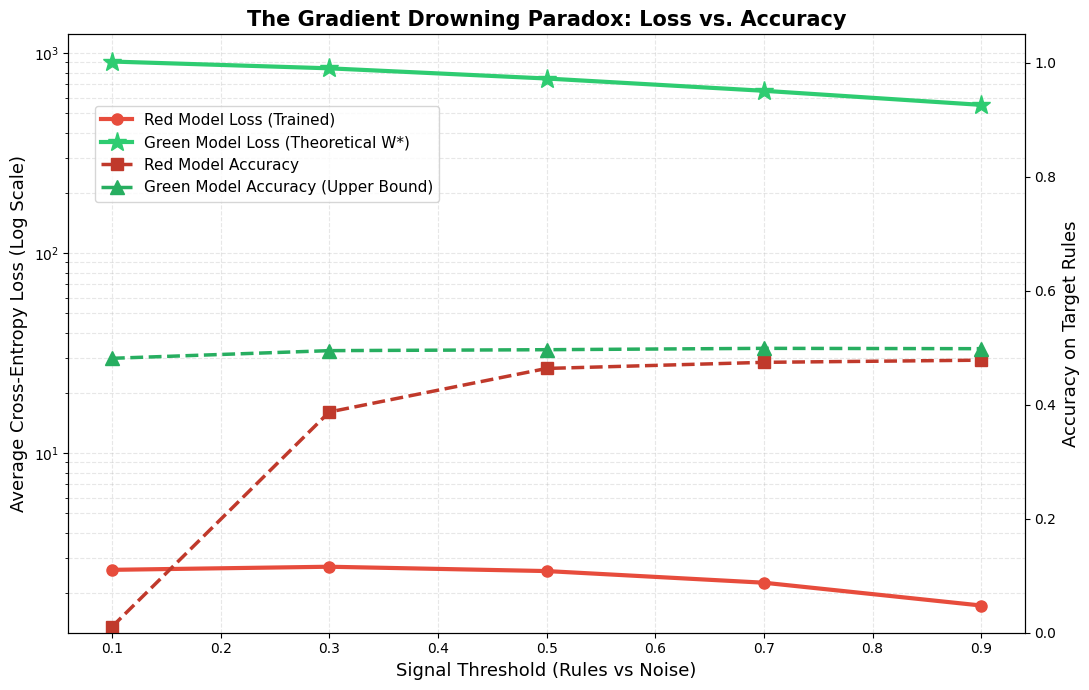

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os
from tqdm import tqdm

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'output_dir': 'neurips_experiments_dual_axis',
    # UPDATED: Pointing exactly to your artifacts folder
    'model_dir': '~/ashutosh/expts/experiment_artifacts', 
    'thresholds': [0.1, 0.3, 0.5, 0.7, 0.9], 
    'test_samples': 2000,    
    'batch_size': 128,
    'green_magnitude': 1000.0 
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
print(f"🚀 RUNNING DUAL-AXIS EVALUATION ON: {CONFIG['device']}")

# --- 2. ARCHITECTURE (Required for loading weights) ---
class CustomAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = (torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5))
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1)

class ResearchTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = CustomAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = CustomAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream = self.layer1(x_stream, mask)
        x_stream = self.layer2(x_stream, mask)
        return self.fc_out(x_stream)

# --- 3. DATA GENERATOR (With W* Logits) ---
def generate_data(num_samples, threshold_x):
    x_data, y_data, green_logits_data = [], [], []
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: 
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
            
        x_seq, y_seq = seq[:-1], seq[1:]
        g_logits = []
        current_rule = None
        
        for i in range(CONFIG['seq_len']):
            if x_seq[i] < CONFIG['vocab_set1']: current_rule = x_seq[i]
            logit_vec = np.zeros(CONFIG['total_vocab'])
            if current_rule is not None:
                predicted_target = transitions[current_rule][0] 
                logit_vec[predicted_target] = CONFIG['green_magnitude']
            g_logits.append(logit_vec)
            
        x_data.append(x_seq); y_data.append(y_seq); green_logits_data.append(g_logits)
    return torch.tensor(x_data), torch.tensor(y_data), torch.tensor(green_logits_data, dtype=torch.float32)

# --- 4. DUAL EVALUATION LOGIC ---
def evaluate_metrics(model, loader):
    criterion = nn.CrossEntropyLoss(reduction='mean')
    model.eval()
    
    metrics = {'red_loss': 0, 'green_loss': 0, 'red_acc': 0, 'green_acc': 0}
    total_ruled_tokens = 0
    batches = 0
    
    with torch.no_grad():
        for bx, by, bg_logits in loader:
            bx, by, bg_logits = bx.to(CONFIG['device']), by.to(CONFIG['device']), bg_logits.to(CONFIG['device'])
            is_ruled = by < CONFIG['vocab_set1']
            
            # 1. Evaluate Red Model (Loaded Weights)
            red_logits = model(bx)
            metrics['red_loss'] += criterion(red_logits.view(-1, CONFIG['total_vocab']), by.view(-1)).item()
            red_preds = red_logits.argmax(dim=-1)
            metrics['red_acc'] += ((red_preds == by) & is_ruled).sum().item()
            
            # 2. Evaluate Green Model (Theoretical W*)
            metrics['green_loss'] += criterion(bg_logits.view(-1, CONFIG['total_vocab']), by.view(-1)).item()
            green_preds = bg_logits.argmax(dim=-1)
            metrics['green_acc'] += ((green_preds == by) & is_ruled).sum().item()
            
            total_ruled_tokens += is_ruled.sum().item()
            batches += 1
            
    # Normalize
    metrics['red_loss'] /= batches
    metrics['green_loss'] /= batches
    metrics['red_acc'] = metrics['red_acc'] / total_ruled_tokens if total_ruled_tokens > 0 else 0
    metrics['green_acc'] = metrics['green_acc'] / total_ruled_tokens if total_ruled_tokens > 0 else 0
    
    return metrics

# --- 5. EXECUTION & PLOTTING ---
def run_dual_axis_experiment():
    print("\n[Running Evaluation] Loading models and computing metrics...")
    
    results = {'r_loss': [], 'g_loss': [], 'r_acc': [], 'g_acc': []}
    
    for x in CONFIG['thresholds']:
        print(f"\n--- Evaluating Threshold {x} ---")
        tex, tey, teg = generate_data(CONFIG['test_samples'], x)
        test_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(tex, tey, teg), batch_size=CONFIG['batch_size'])

        model = ResearchTransformer().to(CONFIG['device'])
        
        # UPDATED: Correct path resolution based on your screenshot
        # e.g., ~/ashutosh/expts/experiment_artifacts/model_x_0.1.pth
        raw_path = f"{CONFIG['model_dir']}/model_x_{x}.pth"
        model_path = os.path.expanduser(raw_path)
        
        try:
            model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            print(f"✅ Successfully loaded {model_path}")
        except FileNotFoundError:
            print(f"⚠️ WARNING: Could not find model at {model_path}. Skipping this threshold!")
            continue # Skip to next threshold if model is missing (e.g., if 0.3 isn't there)
            
        metrics = evaluate_metrics(model, test_loader)
        
        results['r_loss'].append(metrics['red_loss'])
        results['g_loss'].append(metrics['green_loss'])
        results['r_acc'].append(metrics['red_acc'])
        results['g_acc'].append(metrics['green_acc'])
        
        print(f"  Acc: Red={metrics['red_acc']:.3f} | Green={metrics['green_acc']:.3f}")
        print(f"  Loss: Red={metrics['red_loss']:.3f} | Green={metrics['green_loss']:.1f}")

    # --- THE DUAL AXIS PLOT ---
    if not results['r_loss']:
        print("No models were successfully loaded. Exiting.")
        return

    # Extract successfully evaluated thresholds (in case some were skipped)
    valid_thresholds = [x for x in CONFIG['thresholds'] if os.path.exists(os.path.expanduser(f"{CONFIG['model_dir']}/model_x_{x}.pth"))]

    fig, ax1 = plt.subplots(figsize=(11, 7))

    # Axis 1: Cross Entropy Loss (Left, Log Scale)
    color1, color2 = '#e74c3c', '#2ecc71'
    ax1.set_xlabel('Signal Threshold (Rules vs Noise)', fontsize=13)
    ax1.set_ylabel('Average Cross-Entropy Loss (Log Scale)', fontsize=13, color='black')
    ax1.set_yscale('log')
    
    l1 = ax1.plot(valid_thresholds, results['r_loss'], marker='o', markersize=8, linestyle='-', linewidth=3, color=color1, label='Red Model Loss (Trained)')
    l2 = ax1.plot(valid_thresholds, results['g_loss'], marker='*', markersize=14, linestyle='-', linewidth=3, color=color2, label='Green Model Loss (Theoretical W*)')
    ax1.tick_params(axis='y', labelcolor='black')
    ax1.grid(True, which="both", ls="--", alpha=0.3)

    # Axis 2: Accuracy (Right, Linear Scale)
    ax2 = ax1.twinx()  
    color3, color4 = '#c0392b', '#27ae60' 
    ax2.set_ylabel('Accuracy on Target Rules', fontsize=13, color='black')  
    ax2.set_ylim(0.0, 1.05)
    
    l3 = ax2.plot(valid_thresholds, results['r_acc'], marker='s', markersize=8, linestyle='--', linewidth=2.5, color=color3, label='Red Model Accuracy')
    l4 = ax2.plot(valid_thresholds, results['g_acc'], marker='^', markersize=10, linestyle='--', linewidth=2.5, color=color4, label='Green Model Accuracy (Upper Bound)')
    ax2.tick_params(axis='y', labelcolor='black')

    # Combine legends from both axes
    lns = l1 + l2 + l3 + l4
    labs = [l.get_label() for l in lns]
    ax1.legend(lns, labs, loc='center left', fontsize=11, bbox_to_anchor=(0.02,0.8))

    plt.title("The Gradient Drowning Paradox: Loss vs. Accuracy", fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp5_dual_axis_drowning.png", dpi=300)
    print(f"\n✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: {CONFIG['output_dir']}/exp5_dual_axis_drowning.png")

if __name__ == "__main__":
    run_dual_axis_experiment()

🚀 RUNNING 4-MODEL DUAL-AXIS EVALUATION ON: cuda:3

--- Evaluating Threshold 0.1 ---


/tmp/ipykernel_362404/1417048765.py:126: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:245.)
  torch.tensor(green_data, dtype=torch.float32),


✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.1.pth

--- Evaluating Threshold 0.3 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.3.pth

--- Evaluating Threshold 0.5 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.5.pth

--- Evaluating Threshold 0.7 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.7.pth

--- Evaluating Threshold 0.9 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.9.pth

✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: neurips_experiments_dual_axis/exp5_4model_comparison.png


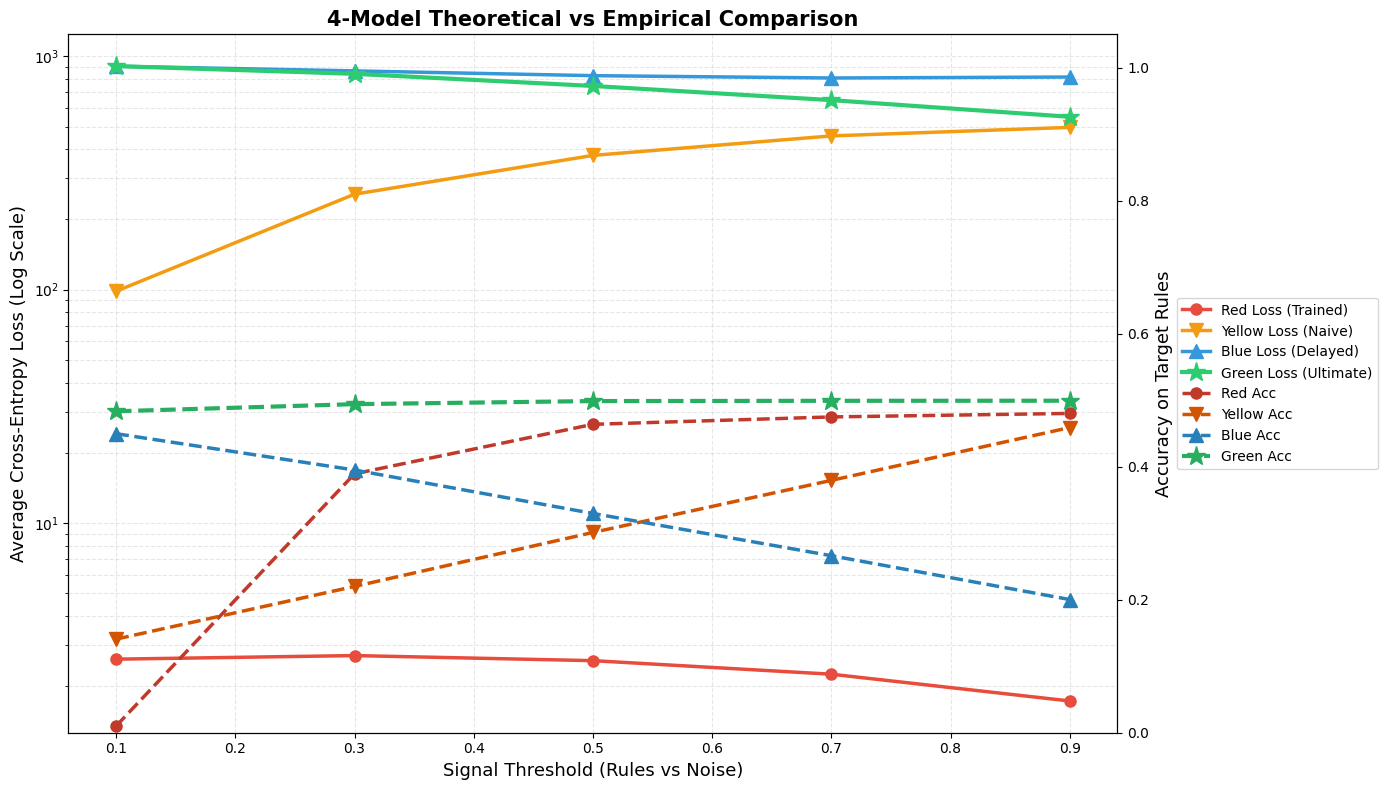

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'output_dir': 'neurips_experiments_dual_axis',
    'model_dir': '~/ashutosh/expts/experiment_artifacts', 
    'thresholds': [0.1, 0.3, 0.5, 0.7, 0.9], 
    'test_samples': 2000,    
    'batch_size': 128,
    'logit_magnitude': 1000.0  # Used for Green, Yellow, and Blue theoretical logits
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
print(f"🚀 RUNNING 4-MODEL DUAL-AXIS EVALUATION ON: {CONFIG['device']}")

# --- 2. ARCHITECTURE ---
class CustomAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = (torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5))
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1)

class ResearchTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = CustomAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = CustomAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream = self.layer1(x_stream, mask)
        x_stream = self.layer2(x_stream, mask)
        return self.fc_out(x_stream)

# --- 3. DATA GENERATOR (Simulating Green, Yellow, and Blue Logits) ---
def generate_data(num_samples, threshold_x):
    x_data, y_data = [], []
    green_data, yellow_data, blue_data = [], [], []
    
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: 
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
            
        x_seq, y_seq = seq[:-1], seq[1:]
        
        g_logits, y_logits, b_logits = [], [], []
        current_rule = None
        previous_rule = None
        
        for i in range(CONFIG['seq_len']):
            is_rule = x_seq[i] < CONFIG['vocab_set1']
            
            if is_rule:
                previous_rule = current_rule
                current_rule = x_seq[i]
                
            g_vec = np.zeros(CONFIG['total_vocab'])
            y_vec = np.zeros(CONFIG['total_vocab'])
            b_vec = np.zeros(CONFIG['total_vocab'])
            
            if current_rule is not None:
                target = transitions[current_rule][0]
                
                # GREEN: Always perfect (Magnitude Routing)
                g_vec[target] = CONFIG['logit_magnitude']
                
                # YELLOW: Perfect on rules. Blind on noise.
                if is_rule:
                    y_vec[target] = CONFIG['logit_magnitude']
                    
                # BLUE: Perfect on noise. Suffers 1-step delay on rules.
                if not is_rule:
                    b_vec[target] = CONFIG['logit_magnitude']
                else:
                    if previous_rule is not None:
                        delayed_target = transitions[previous_rule][0]
                        b_vec[delayed_target] = CONFIG['logit_magnitude']

            g_logits.append(g_vec)
            y_logits.append(y_vec)
            b_logits.append(b_vec)
            
        x_data.append(x_seq)
        y_data.append(y_seq)
        green_data.append(g_logits)
        yellow_data.append(y_logits)
        blue_data.append(b_logits)
        
    return (torch.tensor(x_data), torch.tensor(y_data), 
            torch.tensor(green_data, dtype=torch.float32), 
            torch.tensor(yellow_data, dtype=torch.float32), 
            torch.tensor(blue_data, dtype=torch.float32))

# --- 4. 4-MODEL EVALUATION LOGIC ---
def evaluate_metrics(model, loader):
    criterion = nn.CrossEntropyLoss(reduction='mean')
    model.eval()
    
    metrics = {k: 0.0 for k in ['red_loss', 'g_loss', 'y_loss', 'b_loss', 'red_acc', 'g_acc', 'y_acc', 'b_acc']}
    total_ruled_tokens = 0
    batches = 0
    
    with torch.no_grad():
        for bx, by, bg, byel, bblu in loader:
            bx, by = bx.to(CONFIG['device']), by.to(CONFIG['device'])
            bg, byel, bblu = bg.to(CONFIG['device']), byel.to(CONFIG['device']), bblu.to(CONFIG['device'])
            is_ruled = by < CONFIG['vocab_set1']
            
            # 1. Evaluate Red (Trained)
            red_logits = model(bx)
            metrics['red_loss'] += criterion(red_logits.view(-1, CONFIG['total_vocab']), by.view(-1)).item()
            metrics['red_acc'] += ((red_logits.argmax(dim=-1) == by) & is_ruled).sum().item()
            
            # 2. Evaluate Green (Ultimate)
            metrics['g_loss'] += criterion(bg.view(-1, CONFIG['total_vocab']), by.view(-1)).item()
            metrics['g_acc'] += ((bg.argmax(dim=-1) == by) & is_ruled).sum().item()

            # 3. Evaluate Yellow (Naive)
            metrics['y_loss'] += criterion(byel.view(-1, CONFIG['total_vocab']), by.view(-1)).item()
            metrics['y_acc'] += ((byel.argmax(dim=-1) == by) & is_ruled).sum().item()

            # 4. Evaluate Blue (Delayed)
            metrics['b_loss'] += criterion(bblu.view(-1, CONFIG['total_vocab']), by.view(-1)).item()
            metrics['b_acc'] += ((bblu.argmax(dim=-1) == by) & is_ruled).sum().item()
            
            total_ruled_tokens += is_ruled.sum().item()
            batches += 1
            
    # Normalize
    for key in metrics:
        if 'loss' in key:
            metrics[key] /= batches
        elif 'acc' in key:
            metrics[key] = metrics[key] / total_ruled_tokens if total_ruled_tokens > 0 else 0
            
    return metrics

# --- 5. EXECUTION & PLOTTING ---
def run_dual_axis_experiment():
    results = {k: [] for k in ['r_loss', 'g_loss', 'y_loss', 'b_loss', 'r_acc', 'g_acc', 'y_acc', 'b_acc']}
    
    for x in CONFIG['thresholds']:
        print(f"\n--- Evaluating Threshold {x} ---")
        tex, tey, teg, tey_log, teb_log = generate_data(CONFIG['test_samples'], x)
        dataset = torch.utils.data.TensorDataset(tex, tey, teg, tey_log, teb_log)
        test_loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'])

        model = ResearchTransformer().to(CONFIG['device'])
        raw_path = f"{CONFIG['model_dir']}/model_x_{x}.pth"
        model_path = os.path.expanduser(raw_path)
        
        try:
            model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            print(f"✅ Successfully loaded {model_path}")
        except FileNotFoundError:
            print(f"⚠️ WARNING: Could not find model at {model_path}. Skipping this threshold!")
            continue 
            
        metrics = evaluate_metrics(model, test_loader)
        
        results['r_loss'].append(metrics['red_loss']); results['r_acc'].append(metrics['red_acc'])
        results['g_loss'].append(metrics['g_loss']);   results['g_acc'].append(metrics['g_acc'])
        results['y_loss'].append(metrics['y_loss']);   results['y_acc'].append(metrics['y_acc'])
        results['b_loss'].append(metrics['b_loss']);   results['b_acc'].append(metrics['b_acc'])

    valid_thresholds = [x for x in CONFIG['thresholds'] if os.path.exists(os.path.expanduser(f"{CONFIG['model_dir']}/model_x_{x}.pth"))]
    if not valid_thresholds: return

    # --- PLOTTING 4 MODELS ---
    fig, ax1 = plt.subplots(figsize=(14, 8))

    # Ax1: Cross Entropy Loss (Log Scale)
    ax1.set_xlabel('Signal Threshold (Rules vs Noise)', fontsize=13)
    ax1.set_ylabel('Average Cross-Entropy Loss (Log Scale)', fontsize=13)
    ax1.set_yscale('log')
    
    l1 = ax1.plot(valid_thresholds, results['r_loss'], marker='o', markersize=8,  ls='-', lw=2.5, color='#e74c3c', label='Red Loss (Trained)')
    l2 = ax1.plot(valid_thresholds, results['y_loss'], marker='v', markersize=10, ls='-', lw=2.5, color='#f39c12', label='Yellow Loss (Naive)')
    l3 = ax1.plot(valid_thresholds, results['b_loss'], marker='^', markersize=10, ls='-', lw=2.5, color='#3498db', label='Blue Loss (Delayed)')
    l4 = ax1.plot(valid_thresholds, results['g_loss'], marker='*', markersize=14, ls='-', lw=3.0, color='#2ecc71', label='Green Loss (Ultimate)')
    
    ax1.grid(True, which="both", ls="--", alpha=0.3)

    # Ax2: Accuracy (Linear Scale)
    ax2 = ax1.twinx()  
    ax2.set_ylabel('Accuracy on Target Rules', fontsize=13)  
    ax2.set_ylim(0.0, 1.05)
    
    l5 = ax2.plot(valid_thresholds, results['r_acc'], marker='o', markersize=8,  ls='--', lw=2.5, color='#c0392b', label='Red Acc')
    l6 = ax2.plot(valid_thresholds, results['y_acc'], marker='v', markersize=10, ls='--', lw=2.5, color='#d35400', label='Yellow Acc')
    l7 = ax2.plot(valid_thresholds, results['b_acc'], marker='^', markersize=10, ls='--', lw=2.5, color='#2980b9', label='Blue Acc')
    l8 = ax2.plot(valid_thresholds, results['g_acc'], marker='*', markersize=14, ls='--', lw=3.0, color='#27ae60', label='Green Acc')

    lns = l1 + l2 + l3 + l4 + l5 + l6 + l7 + l8
    labs = [l.get_label() for l in lns]
    ax1.legend(lns, labs, loc='center left', fontsize=10, bbox_to_anchor=(1.05, 0.5))

    plt.title("4-Model Theoretical vs Empirical Comparison", fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp5_4model_comparison.png", dpi=300)
    print(f"\n✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: {CONFIG['output_dir']}/exp5_4model_comparison.png")

if __name__ == "__main__":
    run_dual_axis_experiment()

### reasoning:

What should happen: cc for blue and yello should be

1. Yellow:

a. for left part: 

For ruled token 50% time it would be wrong, in there respective performing areas, and it will be penalised a lot for it because those were the hard estimates. But for the noise tokens, it will generate always a ruled token.

Abandoning: 
Will measure cross entropy loss on the last 100 tokens only, because the hard predictions at the earlier stage would shoot up the loss and hence the next token prediction will shoot up the cross entropy loss: 

**Action:**
will ignore the first 100 tokens in the calculation of the cross entropy loss. 

but before this action, 

Why is this cc for all handconstructed model is way larger.
green: cross entropy losses are hard even for noise tokens cuase it to blow exponentially.
blue: because it's optimsed for the prediction of the one of the noise token, and it's a hard prediction cuase it to have so much cross entropy.
yellow: it has been optimised for the prediction of correct when the curretn token is the ruled token but when it's a noise token, it won't be able to attend to the correct 

but wait why is the left most part of yellow line is so low than other, if it's a ruled token that is unlikely in the left, it when predict initilaiy in the sequence it would be wrong, but when have enough instances again which is very low, it start to predict somewahat better but catch is there is very high noise, so it almost alwyas going to be wrong, but for all the noise tokens, which are abundant here, will have almost average prediction, because it if a noise token it can't attend to the noise token, becuase of our enforcement, high negative score engineering, but it will then have zero score with the ruled tokens, so now the predictions will almost be random but the distrubution will almost be over the ruled tokens, and hence since it's uniform prediction on the ruled tokens, so it won't be as high as ruled cuase it's uniform. 

since the ruled token going to be high in the righter part of the graph, model for noise token will predict the uniform over noise and it mostly would turn out to be the ruled token, but if it's a ruled token it will predict the hard probabiltiy in the left most part causing it to have

but wait wait before this, 

wtf is this cross entropy loss is this a cross entropy be the predicted distribution and true distribution estimated from the context or it is a cross entropy between and true token right there in the sequence.|

🚀 RUNNING 4-MODEL EVALUATION ON: cuda:3 (Last 100 tokens against True Distribution)

--- Evaluating Threshold 0.1 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.1.pth

--- Evaluating Threshold 0.3 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.3.pth

--- Evaluating Threshold 0.5 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.5.pth

--- Evaluating Threshold 0.7 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.7.pth

--- Evaluating Threshold 0.9 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.9.pth

✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: neurips_experiments_dual_axis/exp5_true_dist_comparison.png


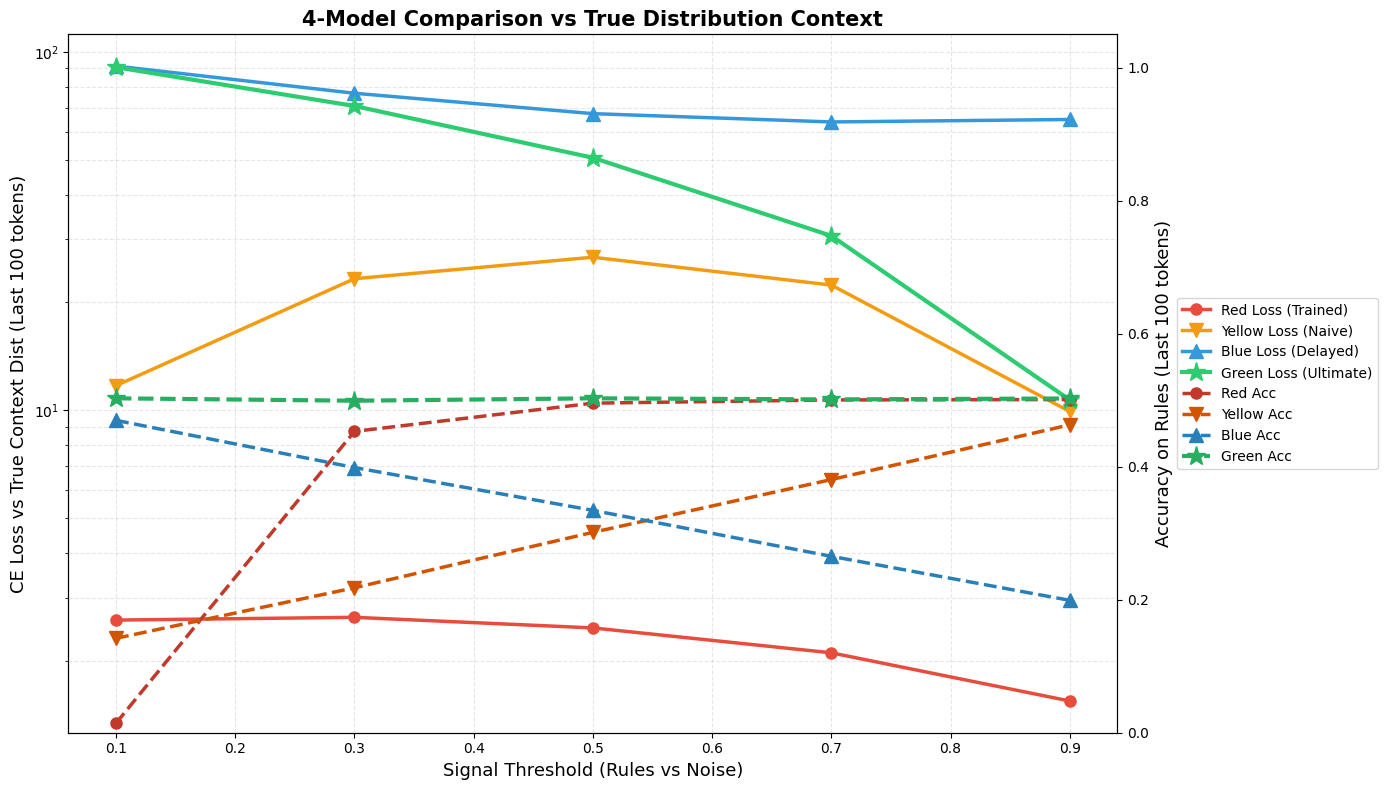

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'output_dir': 'neurips_experiments_dual_axis',
    'model_dir': '~/ashutosh/expts/experiment_artifacts', 
    'thresholds': [0.1, 0.3, 0.5, 0.7, 0.9], 
    'test_samples': 2000,    
    'batch_size': 128,
    'logit_magnitude': 100.0, # Reduced slightly to prevent fp16/fp32 overflow
    'eval_window': 100        # ONLY EVALUATE LAST 100 TOKENS
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
print(f"🚀 RUNNING 4-MODEL EVALUATION ON: {CONFIG['device']} (Last {CONFIG['eval_window']} tokens against True Distribution)")

# --- 2. ARCHITECTURE ---
class CustomAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = (torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5))
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1)

class ResearchTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = CustomAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = CustomAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream = self.layer1(x_stream, mask)
        x_stream = self.layer2(x_stream, mask)
        return self.fc_out(x_stream)

# --- 3. DATA GENERATOR (With True Distribution) ---
def generate_data(num_samples, threshold_x):
    x_data, y_data = [], []
    green_data, yellow_data, blue_data, true_dist_data = [], [], [], []
    
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: 
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
            
        x_seq, y_seq = seq[:-1], seq[1:]
        
        g_logits, y_logits, b_logits, t_dists = [], [], [], []
        current_rule = None
        previous_rule = None
        
        for i in range(CONFIG['seq_len']):
            is_rule = x_seq[i] < CONFIG['vocab_set1']
            
            if is_rule:
                previous_rule = current_rule
                current_rule = x_seq[i]
                
            g_vec = np.zeros(CONFIG['total_vocab'])
            y_vec = np.zeros(CONFIG['total_vocab'])
            b_vec = np.zeros(CONFIG['total_vocab'])
            t_dist = np.zeros(CONFIG['total_vocab'])
            
            # --- TRUE UNDERLYING DISTRIBUTION CALCULATION ---
            if current_rule is None:
                t_dist[:10] = threshold_x / 10.0
            else:
                t1, t2 = transitions[current_rule]
                t_dist[t1] = threshold_x / 2.0
                t_dist[t2] = threshold_x / 2.0
                
            t_dist[10:] = (1.0 - threshold_x) / 10.0
            t_dists.append(t_dist)

            # --- THEORETICAL LOGITS ---
            if current_rule is None:
                g_vec[:10] = CONFIG['logit_magnitude']
                y_vec[:10] = CONFIG['logit_magnitude'] if is_rule else 0
                b_vec[:10] = CONFIG['logit_magnitude'] if not is_rule else 0
            else:
                t1, t2 = transitions[current_rule]
                
                # GREEN: Always perfect
                g_vec[t1] = g_vec[t2] = CONFIG['logit_magnitude']
                
                # YELLOW: Perfect on rules. Blind on noise.
                if is_rule:
                    y_vec[t1] = y_vec[t2] = CONFIG['logit_magnitude']
                    
                # BLUE: Perfect on noise. Suffers 1-step delay on rules.
                if not is_rule:
                    b_vec[t1] = b_vec[t2] = CONFIG['logit_magnitude']
                else:
                    if previous_rule is not None:
                        dt1, dt2 = transitions[previous_rule]
                        b_vec[dt1] = b_vec[dt2] = CONFIG['logit_magnitude']
                    else:
                        b_vec[:10] = CONFIG['logit_magnitude']

            g_logits.append(g_vec)
            y_logits.append(y_vec)
            b_logits.append(b_vec)
            
        x_data.append(x_seq)
        y_data.append(y_seq)
        green_data.append(g_logits)
        yellow_data.append(y_logits)
        blue_data.append(b_logits)
        true_dist_data.append(t_dists)
        
    return (torch.tensor(x_data), torch.tensor(y_data), 
            torch.tensor(green_data, dtype=torch.float32), 
            torch.tensor(yellow_data, dtype=torch.float32), 
            torch.tensor(blue_data, dtype=torch.float32),
            torch.tensor(true_dist_data, dtype=torch.float32))

# --- 4. EVALUATION LOGIC (Cross Entropy vs True Distribution) ---
def evaluate_metrics(model, loader):
    # CrossEntropyLoss automatically computes -sum(target * log_softmax(input)) when targets are probabilities
    criterion = nn.CrossEntropyLoss(reduction='mean')
    model.eval()
    
    metrics = {k: 0.0 for k in ['red_loss', 'g_loss', 'y_loss', 'b_loss', 'red_acc', 'g_acc', 'y_acc', 'b_acc']}
    total_ruled_tokens = 0
    batches = 0
    window = CONFIG['eval_window']
    
    with torch.no_grad():
        for bx, by, bg, byel, bblu, b_true_dist in loader:
            bx, by = bx.to(CONFIG['device']), by.to(CONFIG['device'])
            bg, byel, bblu = bg.to(CONFIG['device']), byel.to(CONFIG['device']), bblu.to(CONFIG['device'])
            b_true_dist = b_true_dist.to(CONFIG['device'])
            
            # Forward pass needs full context, but we slice immediately after
            red_logits_full = model(bx)
            
            # SLICE LAST 100 TOKENS
            red_logits = red_logits_full[:, -window:, :]
            bg = bg[:, -window:, :]
            byel = byel[:, -window:, :]
            bblu = bblu[:, -window:, :]
            b_true_dist = b_true_dist[:, -window:, :]
            by = by[:, -window:]
            
            is_ruled = by < CONFIG['vocab_set1']
            
            # LOSS vs TRUE DISTRIBUTION
            metrics['red_loss'] += criterion(red_logits.reshape(-1, CONFIG['total_vocab']), b_true_dist.reshape(-1, CONFIG['total_vocab'])).item()
            metrics['g_loss'] += criterion(bg.reshape(-1, CONFIG['total_vocab']), b_true_dist.reshape(-1, CONFIG['total_vocab'])).item()
            metrics['y_loss'] += criterion(byel.reshape(-1, CONFIG['total_vocab']), b_true_dist.reshape(-1, CONFIG['total_vocab'])).item()
            metrics['b_loss'] += criterion(bblu.reshape(-1, CONFIG['total_vocab']), b_true_dist.reshape(-1, CONFIG['total_vocab'])).item()

            # ACCURACY (Still checking if predicted argmax matches actual token that appeared)
            metrics['red_acc'] += ((red_logits.argmax(dim=-1) == by) & is_ruled).sum().item()
            metrics['g_acc'] += ((bg.argmax(dim=-1) == by) & is_ruled).sum().item()
            metrics['y_acc'] += ((byel.argmax(dim=-1) == by) & is_ruled).sum().item()
            metrics['b_acc'] += ((bblu.argmax(dim=-1) == by) & is_ruled).sum().item()
            
            total_ruled_tokens += is_ruled.sum().item()
            batches += 1
            
    # Normalize
    for key in metrics:
        if 'loss' in key:
            metrics[key] /= batches
        elif 'acc' in key:
            metrics[key] = metrics[key] / total_ruled_tokens if total_ruled_tokens > 0 else 0
            
    return metrics

# --- 5. EXECUTION & PLOTTING ---
def run_dual_axis_experiment():
    results = {k: [] for k in ['r_loss', 'g_loss', 'y_loss', 'b_loss', 'r_acc', 'g_acc', 'y_acc', 'b_acc']}
    
    for x in CONFIG['thresholds']:
        print(f"\n--- Evaluating Threshold {x} ---")
        tex, tey, teg, tey_log, teb_log, te_dist = generate_data(CONFIG['test_samples'], x)
        dataset = torch.utils.data.TensorDataset(tex, tey, teg, tey_log, teb_log, te_dist)
        test_loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'])

        model = ResearchTransformer().to(CONFIG['device'])
        raw_path = f"{CONFIG['model_dir']}/model_x_{x}.pth"
        model_path = os.path.expanduser(raw_path)
        
        try:
            model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            print(f"✅ Successfully loaded {model_path}")
        except FileNotFoundError:
            print(f"⚠️ WARNING: Could not find model at {model_path}. Skipping this threshold!")
            continue 
            
        metrics = evaluate_metrics(model, test_loader)
        
        results['r_loss'].append(metrics['red_loss']); results['r_acc'].append(metrics['red_acc'])
        results['g_loss'].append(metrics['g_loss']);   results['g_acc'].append(metrics['g_acc'])
        results['y_loss'].append(metrics['y_loss']);   results['y_acc'].append(metrics['y_acc'])
        results['b_loss'].append(metrics['b_loss']);   results['b_acc'].append(metrics['b_acc'])

    valid_thresholds = [x for x in CONFIG['thresholds'] if os.path.exists(os.path.expanduser(f"{CONFIG['model_dir']}/model_x_{x}.pth"))]
    if not valid_thresholds: return

    # --- PLOTTING 4 MODELS ---
    fig, ax1 = plt.subplots(figsize=(14, 8))

    # Ax1: Cross Entropy Loss vs TRUE DISTRIBUTION (Log Scale)
    ax1.set_xlabel('Signal Threshold (Rules vs Noise)', fontsize=13)
    ax1.set_ylabel(f'CE Loss vs True Context Dist (Last {CONFIG["eval_window"]} tokens)', fontsize=13)
    ax1.set_yscale('log')
    
    l1 = ax1.plot(valid_thresholds, results['r_loss'], marker='o', markersize=8,  ls='-', lw=2.5, color='#e74c3c', label='Red Loss (Trained)')
    l2 = ax1.plot(valid_thresholds, results['y_loss'], marker='v', markersize=10, ls='-', lw=2.5, color='#f39c12', label='Yellow Loss (Naive)')
    l3 = ax1.plot(valid_thresholds, results['b_loss'], marker='^', markersize=10, ls='-', lw=2.5, color='#3498db', label='Blue Loss (Delayed)')
    l4 = ax1.plot(valid_thresholds, results['g_loss'], marker='*', markersize=14, ls='-', lw=3.0, color='#2ecc71', label='Green Loss (Ultimate)')
    
    ax1.grid(True, which="both", ls="--", alpha=0.3)

    # Ax2: Accuracy (Linear Scale)
    ax2 = ax1.twinx()  
    ax2.set_ylabel(f'Accuracy on Rules (Last {CONFIG["eval_window"]} tokens)', fontsize=13)  
    ax2.set_ylim(0.0, 1.05)
    
    l5 = ax2.plot(valid_thresholds, results['r_acc'], marker='o', markersize=8,  ls='--', lw=2.5, color='#c0392b', label='Red Acc')
    l6 = ax2.plot(valid_thresholds, results['y_acc'], marker='v', markersize=10, ls='--', lw=2.5, color='#d35400', label='Yellow Acc')
    l7 = ax2.plot(valid_thresholds, results['b_acc'], marker='^', markersize=10, ls='--', lw=2.5, color='#2980b9', label='Blue Acc')
    l8 = ax2.plot(valid_thresholds, results['g_acc'], marker='*', markersize=14, ls='--', lw=3.0, color='#27ae60', label='Green Acc')

    lns = l1 + l2 + l3 + l4 + l5 + l6 + l7 + l8
    labs = [l.get_label() for l in lns]
    ax1.legend(lns, labs, loc='center left', fontsize=10, bbox_to_anchor=(1.05, 0.5))

    plt.title("4-Model Comparison vs True Distribution Context", fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp5_true_dist_comparison.png", dpi=300)
    print(f"\n✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: {CONFIG['output_dir']}/exp5_true_dist_comparison.png")

if __name__ == "__main__":
    run_dual_axis_experiment()

The main agenda was can we do something so that 

🚀 RUNNING 2-MODEL CALIBRATED EVALUATION ON: cuda:3 (Last 100 tokens)

--- Evaluating Threshold 0.1 ---


/tmp/ipykernel_461180/1381084951.py:112: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:245.)
  return (torch.tensor(x_data), torch.tensor(y_data), torch.tensor(ultimate_data, dtype=torch.float32))


✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.1.pth

--- Evaluating Threshold 0.3 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.3.pth

--- Evaluating Threshold 0.5 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.5.pth

--- Evaluating Threshold 0.7 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.7.pth

--- Evaluating Threshold 0.9 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.9.pth

✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: neurips_experiments_dual_axis/exp5_2model_calibrated.png


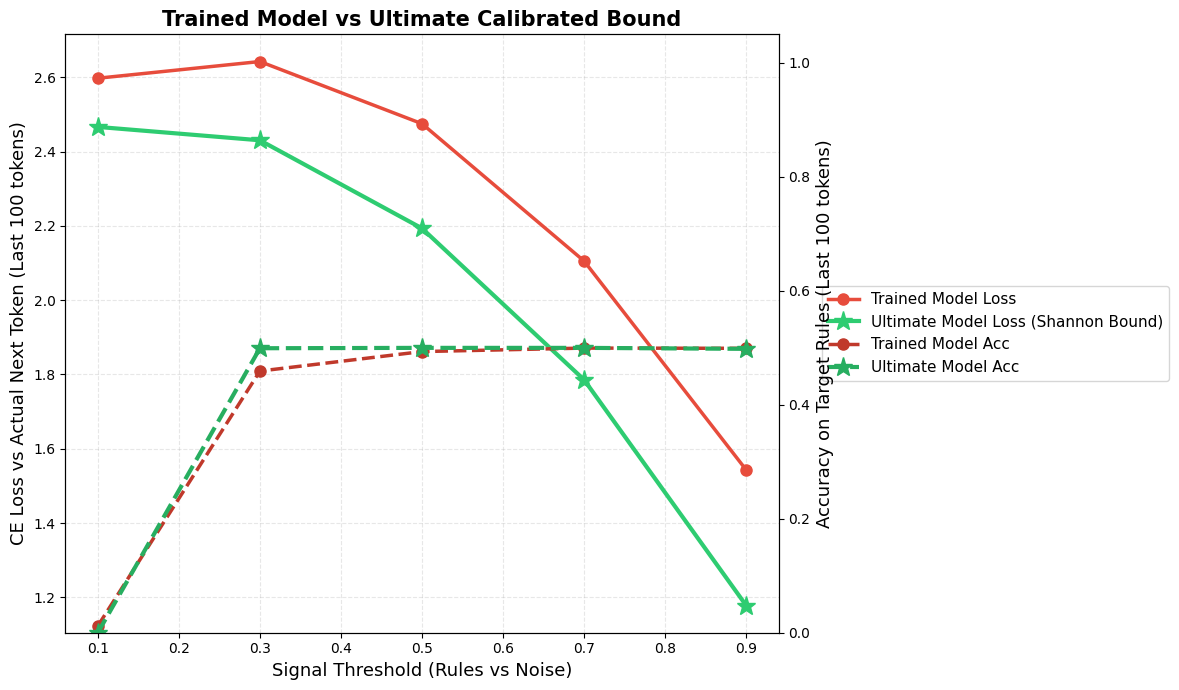

In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'output_dir': 'neurips_experiments_dual_axis',
    'model_dir': '~/ashutosh/expts/experiment_artifacts', 
    'thresholds': [0.1, 0.3, 0.5, 0.7, 0.9], 
    'test_samples': 2000,    
    'batch_size': 128,
    'eval_window': 100        # ONLY EVALUATE LAST 100 TOKENS
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
print(f"🚀 RUNNING 2-MODEL CALIBRATED EVALUATION ON: {CONFIG['device']} (Last {CONFIG['eval_window']} tokens)")

# --- 2. ARCHITECTURE ---
class CustomAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = (torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5))
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1)

class ResearchTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = CustomAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = CustomAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream = self.layer1(x_stream, mask)
        x_stream = self.layer2(x_stream, mask)
        return self.fc_out(x_stream)

# --- 3. HELPER: SHANNON ENTROPY LOGITS ---
def get_calibrated_logits(active_rule, x_thresh, transitions):
    """Outputs perfect log-probabilities mathematically matched to the environment."""
    logits = np.full(CONFIG['total_vocab'], -100.0) 
    
    # 1. Calibrated Noise Logits
    logits[10:] = np.log((1.0 - x_thresh) / 10.0 + 1e-10)
    
    # 2. Calibrated Rule Logits
    if active_rule is None:
        logits[:10] = np.log(x_thresh / 10.0 + 1e-10)
    else:
        t1, t2 = transitions[active_rule]
        logits[t1] = np.log(x_thresh / 2.0 + 1e-10)
        logits[t2] = np.log(x_thresh / 2.0 + 1e-10)
        
    return logits

# --- 4. DATA GENERATOR ---
def generate_data(num_samples, threshold_x):
    x_data, y_data, ultimate_data = [], [], []
    
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: 
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
            
        x_seq, y_seq = seq[:-1], seq[1:]
        u_logits = []
        current_rule = None
        
        for i in range(CONFIG['seq_len']):
            is_rule = x_seq[i] < CONFIG['vocab_set1']
            if is_rule:
                current_rule = x_seq[i]
                
            # --- ULTIMATE: Calibrated Shannon Bound ---
            u_logits.append(get_calibrated_logits(current_rule, threshold_x, transitions))
            
        x_data.append(x_seq); y_data.append(y_seq); ultimate_data.append(u_logits)
        
    return (torch.tensor(x_data), torch.tensor(y_data), torch.tensor(ultimate_data, dtype=torch.float32))

# --- 5. EVALUATION LOGIC ---
def evaluate_metrics(model, loader):
    criterion = nn.CrossEntropyLoss(reduction='mean')
    model.eval()
    
    metrics = {k: 0.0 for k in ['t_loss', 'u_loss', 't_acc', 'u_acc']}
    total_ruled_tokens = 0
    batches = 0
    window = CONFIG['eval_window']
    
    with torch.no_grad():
        for bx, by, bu in loader:
            bx, by, bu = bx.to(CONFIG['device']), by.to(CONFIG['device']), bu.to(CONFIG['device'])
            
            t_logits_full = model(bx)
            
            # SLICE ONLY LAST 100 TOKENS
            t_logits = t_logits_full[:, -window:, :]
            bu = bu[:, -window:, :]
            by = by[:, -window:]
            
            is_ruled = by < CONFIG['vocab_set1']
            
            # CE LOSS vs ACTUAL SAMPLED NEXT TOKEN
            metrics['t_loss'] += criterion(t_logits.reshape(-1, CONFIG['total_vocab']), by.reshape(-1)).item()
            metrics['u_loss'] += criterion(bu.reshape(-1, CONFIG['total_vocab']), by.reshape(-1)).item()

            # ACCURACY
            metrics['t_acc'] += ((t_logits.argmax(dim=-1) == by) & is_ruled).sum().item()
            metrics['u_acc'] += ((bu.argmax(dim=-1) == by) & is_ruled).sum().item()
            
            total_ruled_tokens += is_ruled.sum().item()
            batches += 1
            
    for key in metrics:
        if 'loss' in key: metrics[key] /= batches
        elif 'acc' in key: metrics[key] = metrics[key] / total_ruled_tokens if total_ruled_tokens > 0 else 0
            
    return metrics

# --- 6. PLOTTING ---
def run_dual_axis_experiment():
    results = {k: [] for k in ['t_loss', 'u_loss', 't_acc', 'u_acc']}
    
    for x in CONFIG['thresholds']:
        print(f"\n--- Evaluating Threshold {x} ---")
        tex, tey, teu = generate_data(CONFIG['test_samples'], x)
        dataset = torch.utils.data.TensorDataset(tex, tey, teu)
        test_loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'])

        model = ResearchTransformer().to(CONFIG['device'])
        raw_path = f"{CONFIG['model_dir']}/model_x_{x}.pth"
        model_path = os.path.expanduser(raw_path)
        
        try:
            model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            print(f"✅ Successfully loaded {model_path}")
        except FileNotFoundError:
            print(f"⚠️ WARNING: Could not find model at {model_path}. Skipping this threshold!")
            continue 
            
        metrics = evaluate_metrics(model, test_loader)
        
        results['t_loss'].append(metrics['t_loss']); results['t_acc'].append(metrics['t_acc'])
        results['u_loss'].append(metrics['u_loss']); results['u_acc'].append(metrics['u_acc'])

    valid_thresholds = [x for x in CONFIG['thresholds'] if os.path.exists(os.path.expanduser(f"{CONFIG['model_dir']}/model_x_{x}.pth"))]
    if not valid_thresholds: return

    # --- PLOTTING ---
    fig, ax1 = plt.subplots(figsize=(12, 7))

    # Ax1: Cross Entropy Loss (Linear Scale)
    ax1.set_xlabel('Signal Threshold (Rules vs Noise)', fontsize=13)
    ax1.set_ylabel(f'CE Loss vs Actual Next Token (Last {CONFIG["eval_window"]} tokens)', fontsize=13)
    
    l1 = ax1.plot(valid_thresholds, results['t_loss'], marker='o', markersize=8,  ls='-', lw=2.5, color='#e74c3c', label='Trained Model Loss')
    l2 = ax1.plot(valid_thresholds, results['u_loss'], marker='*', markersize=14, ls='-', lw=3.0, color='#2ecc71', label='Ultimate Model Loss (Shannon Bound)')
    
    ax1.grid(True, which="both", ls="--", alpha=0.3)

    # Ax2: Accuracy (Linear Scale)
    ax2 = ax1.twinx()  
    ax2.set_ylabel(f'Accuracy on Target Rules (Last {CONFIG["eval_window"]} tokens)', fontsize=13)  
    ax2.set_ylim(0.0, 1.05)
    
    l3 = ax2.plot(valid_thresholds, results['t_acc'], marker='o', markersize=8,  ls='--', lw=2.5, color='#c0392b', label='Trained Model Acc')
    l4 = ax2.plot(valid_thresholds, results['u_acc'], marker='*', markersize=14, ls='--', lw=3.0, color='#27ae60', label='Ultimate Model Acc')

    lns = l1 + l2 + l3 + l4
    labs = [l.get_label() for l in lns]
    ax1.legend(lns, labs, loc='center left', fontsize=11, bbox_to_anchor=(1.05, 0.5))

    plt.title("Trained Model vs Ultimate Calibrated Bound", fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp5_2model_calibrated.png", dpi=300)
    print(f"\n✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: {CONFIG['output_dir']}/exp5_2model_calibrated.png")

if __name__ == "__main__":
    run_dual_axis_experiment()

🚀 RUNNING 2-MODEL CALIBRATED EVALUATION ON: cuda:3 (All Tokens)

--- Evaluating Threshold 0.1 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.1.pth

--- Evaluating Threshold 0.3 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.3.pth

--- Evaluating Threshold 0.5 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.5.pth

--- Evaluating Threshold 0.7 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.7.pth

--- Evaluating Threshold 0.9 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.9.pth

✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: neurips_experiments_dual_axis/exp5_2model_calibrated_all_tokens.png


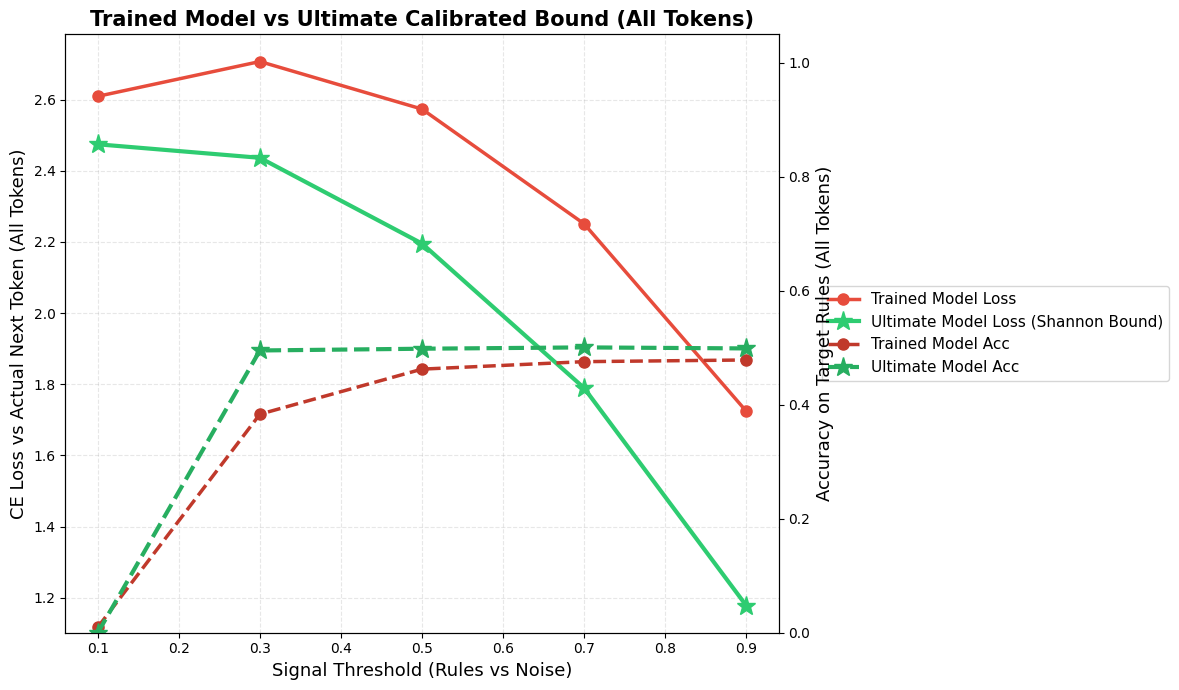

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'output_dir': 'neurips_experiments_dual_axis',
    'model_dir': '~/ashutosh/expts/experiment_artifacts', 
    'thresholds': [0.1, 0.3, 0.5, 0.7, 0.9], 
    'test_samples': 2000,    
    'batch_size': 128
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
print(f"🚀 RUNNING 2-MODEL CALIBRATED EVALUATION ON: {CONFIG['device']} (All Tokens)")

# --- 2. ARCHITECTURE ---
class CustomAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = (torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5))
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1)

class ResearchTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = CustomAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = CustomAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream = self.layer1(x_stream, mask)
        x_stream = self.layer2(x_stream, mask)
        return self.fc_out(x_stream)

# --- 3. HELPER: SHANNON ENTROPY LOGITS ---
def get_calibrated_logits(active_rule, x_thresh, transitions):
    """Outputs perfect log-probabilities mathematically matched to the environment."""
    logits = np.full(CONFIG['total_vocab'], -100.0) 
    
    # 1. Calibrated Noise Logits
    logits[10:] = np.log((1.0 - x_thresh) / 10.0 + 1e-10)
    
    # 2. Calibrated Rule Logits
    if active_rule is None:
        logits[:10] = np.log(x_thresh / 10.0 + 1e-10)
    else:
        t1, t2 = transitions[active_rule]
        logits[t1] = np.log(x_thresh / 2.0 + 1e-10)
        logits[t2] = np.log(x_thresh / 2.0 + 1e-10)
        
    return logits

# --- 4. DATA GENERATOR ---
def generate_data(num_samples, threshold_x):
    x_data, y_data, ultimate_data = [], [], []
    
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: 
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
            
        x_seq, y_seq = seq[:-1], seq[1:]
        u_logits = []
        current_rule = None
        
        for i in range(CONFIG['seq_len']):
            is_rule = x_seq[i] < CONFIG['vocab_set1']
            if is_rule:
                current_rule = x_seq[i]
                
            # --- ULTIMATE: Calibrated Shannon Bound ---
            u_logits.append(get_calibrated_logits(current_rule, threshold_x, transitions))
            
        x_data.append(x_seq); y_data.append(y_seq); ultimate_data.append(u_logits)
        
    return (torch.tensor(x_data), torch.tensor(y_data), torch.tensor(ultimate_data, dtype=torch.float32))

# --- 5. EVALUATION LOGIC ---
def evaluate_metrics(model, loader):
    criterion = nn.CrossEntropyLoss(reduction='mean')
    model.eval()
    
    metrics = {k: 0.0 for k in ['t_loss', 'u_loss', 't_acc', 'u_acc']}
    total_ruled_tokens = 0
    batches = 0
    
    with torch.no_grad():
        for bx, by, bu in loader:
            bx, by, bu = bx.to(CONFIG['device']), by.to(CONFIG['device']), bu.to(CONFIG['device'])
            
            t_logits = model(bx)
            
            is_ruled = by < CONFIG['vocab_set1']
            
            # CE LOSS vs ACTUAL SAMPLED NEXT TOKEN (All Tokens)
            metrics['t_loss'] += criterion(t_logits.reshape(-1, CONFIG['total_vocab']), by.reshape(-1)).item()
            metrics['u_loss'] += criterion(bu.reshape(-1, CONFIG['total_vocab']), by.reshape(-1)).item()

            # ACCURACY (All Tokens)
            metrics['t_acc'] += ((t_logits.argmax(dim=-1) == by) & is_ruled).sum().item()
            metrics['u_acc'] += ((bu.argmax(dim=-1) == by) & is_ruled).sum().item()
            
            total_ruled_tokens += is_ruled.sum().item()
            batches += 1
            
    for key in metrics:
        if 'loss' in key: metrics[key] /= batches
        elif 'acc' in key: metrics[key] = metrics[key] / total_ruled_tokens if total_ruled_tokens > 0 else 0
            
    return metrics

# --- 6. PLOTTING ---
def run_dual_axis_experiment():
    results = {k: [] for k in ['t_loss', 'u_loss', 't_acc', 'u_acc']}
    
    for x in CONFIG['thresholds']:
        print(f"\n--- Evaluating Threshold {x} ---")
        tex, tey, teu = generate_data(CONFIG['test_samples'], x)
        dataset = torch.utils.data.TensorDataset(tex, tey, teu)
        test_loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'])

        model = ResearchTransformer().to(CONFIG['device'])
        raw_path = f"{CONFIG['model_dir']}/model_x_{x}.pth"
        model_path = os.path.expanduser(raw_path)
        
        try:
            model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            print(f"✅ Successfully loaded {model_path}")
        except FileNotFoundError:
            print(f"⚠️ WARNING: Could not find model at {model_path}. Skipping this threshold!")
            continue 
            
        metrics = evaluate_metrics(model, test_loader)
        
        results['t_loss'].append(metrics['t_loss']); results['t_acc'].append(metrics['t_acc'])
        results['u_loss'].append(metrics['u_loss']); results['u_acc'].append(metrics['u_acc'])

    valid_thresholds = [x for x in CONFIG['thresholds'] if os.path.exists(os.path.expanduser(f"{CONFIG['model_dir']}/model_x_{x}.pth"))]
    if not valid_thresholds: return

    # --- PLOTTING ---
    fig, ax1 = plt.subplots(figsize=(12, 7))

    # Ax1: Cross Entropy Loss (Linear Scale)
    ax1.set_xlabel('Signal Threshold (Rules vs Noise)', fontsize=13)
    ax1.set_ylabel(f'CE Loss vs Actual Next Token (All Tokens)', fontsize=13)
    
    l1 = ax1.plot(valid_thresholds, results['t_loss'], marker='o', markersize=8,  ls='-', lw=2.5, color='#e74c3c', label='Trained Model Loss')
    l2 = ax1.plot(valid_thresholds, results['u_loss'], marker='*', markersize=14, ls='-', lw=3.0, color='#2ecc71', label='Ultimate Model Loss (Shannon Bound)')
    
    ax1.grid(True, which="both", ls="--", alpha=0.3)

    # Ax2: Accuracy (Linear Scale)
    ax2 = ax1.twinx()  
    ax2.set_ylabel(f'Accuracy on Target Rules (All Tokens)', fontsize=13)  
    ax2.set_ylim(0.0, 1.05)
    
    l3 = ax2.plot(valid_thresholds, results['t_acc'], marker='o', markersize=8,  ls='--', lw=2.5, color='#c0392b', label='Trained Model Acc')
    l4 = ax2.plot(valid_thresholds, results['u_acc'], marker='*', markersize=14, ls='--', lw=3.0, color='#27ae60', label='Ultimate Model Acc')

    lns = l1 + l2 + l3 + l4
    labs = [l.get_label() for l in lns]
    ax1.legend(lns, labs, loc='center left', fontsize=11, bbox_to_anchor=(1.05, 0.5))

    plt.title("Trained Model vs Ultimate Calibrated Bound (All Tokens)", fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp5_2model_calibrated_all_tokens.png", dpi=300)
    print(f"\n✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: {CONFIG['output_dir']}/exp5_2model_calibrated_all_tokens.png")

if __name__ == "__main__":
    run_dual_axis_experiment()

🚀 RUNNING 2-MODEL CALIBRATED EVALUATION ON: cuda:3 (All Tokens)

--- Evaluating Threshold 0.1 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.1.pth

--- Evaluating Threshold 0.3 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.3.pth

--- Evaluating Threshold 0.5 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.5.pth

--- Evaluating Threshold 0.7 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.7.pth

--- Evaluating Threshold 0.9 ---
✅ Successfully loaded /home/hariguru/ashutosh/expts/experiment_artifacts/model_x_0.9.pth

✅ EXPERIMENT COMPLETE. Dual-axis plot saved to: neurips_experiments_dual_axis/exp5_2model_calibrated_all_tokens.png


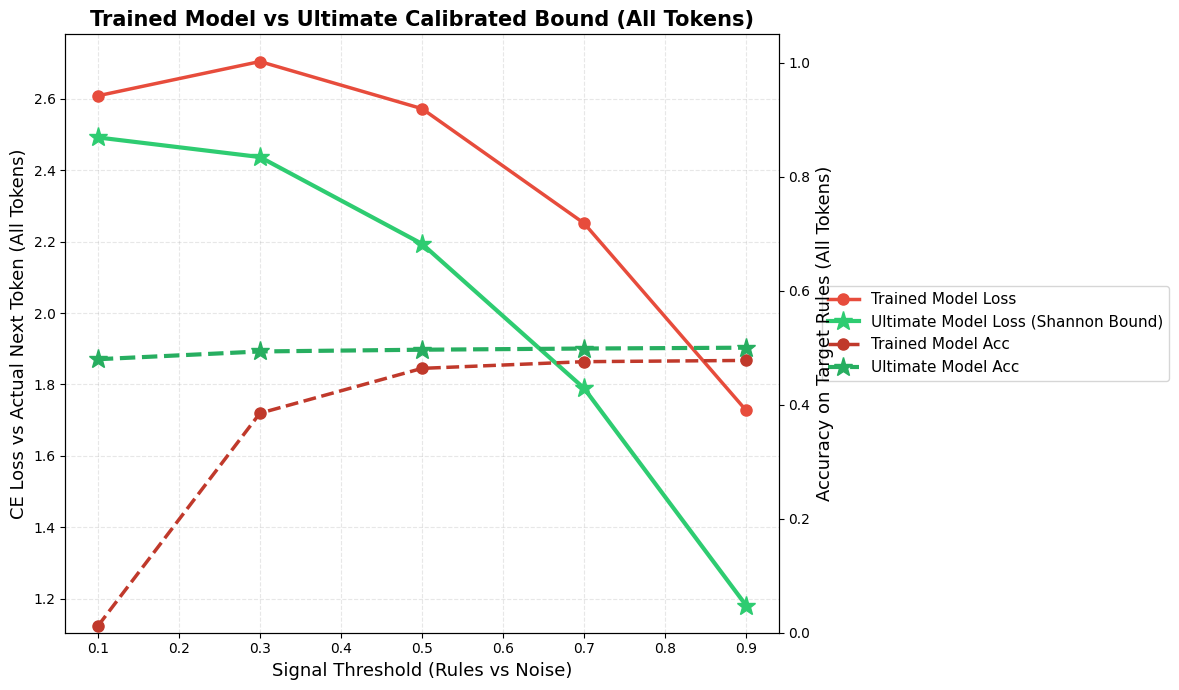

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 1. CONFIGURATION ---
CONFIG = {
    'total_vocab': 20,
    'vocab_set1': 10,       
    'seq_len': 200,         
    'attn_dim': 64,         
    'device': 'cuda:3' if torch.cuda.is_available() else 'cpu',
    'output_dir': 'neurips_experiments_dual_axis',
    'model_dir': '~/ashutosh/expts/experiment_artifacts', 
    'thresholds': [0.1, 0.3, 0.5, 0.7, 0.9], 
    'test_samples': 2000,    
    'batch_size': 128
}

os.makedirs(CONFIG['output_dir'], exist_ok=True)
print(f" RUNNING 2-MODEL CALIBRATED EVALUATION ON: {CONFIG['device']} (All Tokens)")

# --- 2. ARCHITECTURE ---
class CustomAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)

    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = (torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5))
        if mask is not None: scores += mask
        attn_weights = F.softmax(scores, dim=-1)
        attn_out = self.W_o(torch.bmm(attn_weights, V))
        return torch.cat([x, attn_out], dim=-1)

class ResearchTransformer(nn.Module):
    def __init__(self):
        super().__init__()
        self.initial_dim = CONFIG['total_vocab'] + CONFIG['seq_len']
        self.layer1 = CustomAttentionBlock(self.initial_dim, CONFIG['attn_dim'])
        self.layer2 = CustomAttentionBlock(self.initial_dim + CONFIG['attn_dim'], CONFIG['attn_dim'])
        self.fc_out = nn.Linear(self.initial_dim + 2 * CONFIG['attn_dim'], CONFIG['total_vocab'], bias=False)

    def forward(self, x):
        B, T = x.shape
        tokens_oh = F.one_hot(x, num_classes=CONFIG['total_vocab']).float()
        pos_oh = F.one_hot(torch.arange(T, device=x.device), num_classes=CONFIG['seq_len']).float().unsqueeze(0).repeat(B, 1, 1)
        x_stream = torch.cat([tokens_oh, pos_oh], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        
        x_stream = self.layer1(x_stream, mask)
        x_stream = self.layer2(x_stream, mask)
        return self.fc_out(x_stream)

# --- 3. HELPER: SMART HYBRID LOGITS ---
def get_calibrated_logits(active_rule, x_thresh, transitions):
    """Outputs log-probs, but artificially boosts rules to win argmax at low thresholds."""
    logits = np.full(CONFIG['total_vocab'], -100.0) 
    
    p_noise = (1.0 - x_thresh) / 10.0
    p_target_true = x_thresh / 2.0
    
    # THE SMART BOOST: If noise is mathematically more likely than the rule target,
    # artificially boost the rule target JUST enough to win the argmax.
    if p_target_true <= p_noise:
        p_target_effective = p_noise + 1e-5 # Barely beat noise to trigger argmax
    else:
        p_target_effective = p_target_true
 
    # 1. Calibrated Noise Logits
    logits[10:] = np.log(p_noise + 1e-10)
    
    # 2. Calibrated Rule Logits
    if active_rule is None:
        logits[:10] = np.log(x_thresh / 10.0 + 1e-10)
    else:
        t1, t2 = transitions[active_rule]
        logits[t1] = np.log(p_target_effective)
        logits[t2] = np.log(p_target_effective)
        
    return logits

# --- 4. DATA GENERATOR ---
def generate_data(num_samples, threshold_x):
    x_data, y_data, ultimate_data = [], [], []
    
    for _ in range(num_samples):
        transitions = {i: np.random.choice(CONFIG['vocab_set1'], size=2, replace=False) for i in range(CONFIG['vocab_set1'])}
        seq = []
        last_ruled = None
        
        for _ in range(CONFIG['seq_len'] + 1):
            if np.random.rand() < threshold_x:
                token = np.random.randint(0, CONFIG['vocab_set1']) if last_ruled is None else np.random.choice(transitions[last_ruled])
                last_ruled = token
            else: 
                token = np.random.randint(CONFIG['vocab_set1'], CONFIG['total_vocab'])
            seq.append(token)
            
        x_seq, y_seq = seq[:-1], seq[1:]
        u_logits = []
        current_rule = None
        
        for i in range(CONFIG['seq_len']):
            is_rule = x_seq[i] < CONFIG['vocab_set1']
            if is_rule:
                current_rule = x_seq[i]
                
            # --- ULTIMATE: Calibrated Shannon Bound ---
            u_logits.append(get_calibrated_logits(current_rule, threshold_x, transitions))
            
        x_data.append(x_seq); y_data.append(y_seq); ultimate_data.append(u_logits)
        
    return (torch.tensor(x_data), torch.tensor(y_data), torch.tensor(ultimate_data, dtype=torch.float32))

# --- 5. EVALUATION LOGIC ---
def evaluate_metrics(model, loader):
    criterion = nn.CrossEntropyLoss(reduction='mean')
    model.eval()
    
    metrics = {k: 0.0 for k in ['t_loss', 'u_loss', 't_acc', 'u_acc']}
    total_ruled_tokens = 0
    batches = 0
    
    with torch.no_grad():
        for bx, by, bu in loader:
            bx, by, bu = bx.to(CONFIG['device']), by.to(CONFIG['device']), bu.to(CONFIG['device'])
            
            t_logits = model(bx)
            
            is_ruled = by < CONFIG['vocab_set1']
            
            # CE LOSS vs ACTUAL SAMPLED NEXT TOKEN (All Tokens)
            metrics['t_loss'] += criterion(t_logits.reshape(-1, CONFIG['total_vocab']), by.reshape(-1)).item()
            metrics['u_loss'] += criterion(bu.reshape(-1, CONFIG['total_vocab']), by.reshape(-1)).item()

            # ACCURACY (All Tokens)
            metrics['t_acc'] += ((t_logits.argmax(dim=-1) == by) & is_ruled).sum().item()
            metrics['u_acc'] += ((bu.argmax(dim=-1) == by) & is_ruled).sum().item()
            
            total_ruled_tokens += is_ruled.sum().item()
            batches += 1
            
    for key in metrics:
        if 'loss' in key: metrics[key] /= batches
        elif 'acc' in key: metrics[key] = metrics[key] / total_ruled_tokens if total_ruled_tokens > 0 else 0
            
    return metrics

# --- 6. PLOTTING ---
def run_dual_axis_experiment():
    results = {k: [] for k in ['t_loss', 'u_loss', 't_acc', 'u_acc']}
    
    for x in CONFIG['thresholds']:
        print(f"\n--- Evaluating Threshold {x} ---")
        tex, tey, teu = generate_data(CONFIG['test_samples'], x)
        dataset = torch.utils.data.TensorDataset(tex, tey, teu)
        test_loader = torch.utils.data.DataLoader(dataset, batch_size=CONFIG['batch_size'])

        model = ResearchTransformer().to(CONFIG['device'])
        raw_path = f"{CONFIG['model_dir']}/model_x_{x}.pth"
        model_path = os.path.expanduser(raw_path)
        
        try:
            model.load_state_dict(torch.load(model_path, map_location=CONFIG['device']))
            print(f" Successfully loaded {model_path}")
        except FileNotFoundError:
            print(f" WARNING: Could not find model at {model_path}. Skipping this threshold!")
            continue 
            
        metrics = evaluate_metrics(model, test_loader)
        
        results['t_loss'].append(metrics['t_loss']); results['t_acc'].append(metrics['t_acc'])
        results['u_loss'].append(metrics['u_loss']); results['u_acc'].append(metrics['u_acc'])

    valid_thresholds = [x for x in CONFIG['thresholds'] if os.path.exists(os.path.expanduser(f"{CONFIG['model_dir']}/model_x_{x}.pth"))]
    if not valid_thresholds: return

    # --- PLOTTING ---
    fig, ax1 = plt.subplots(figsize=(12, 7))

    # Ax1: Cross Entropy Loss (Linear Scale)
    ax1.set_xlabel('Signal Threshold (Rules vs Noise)', fontsize=13)
    ax1.set_ylabel(f'CE Loss vs Actual Next Token (All Tokens)', fontsize=13)
    
    l1 = ax1.plot(valid_thresholds, results['t_loss'], marker='o', markersize=8,  ls='-', lw=2.5, color='#e74c3c', label='Trained Model Loss')
    l2 = ax1.plot(valid_thresholds, results['u_loss'], marker='*', markersize=14, ls='-', lw=3.0, color='#2ecc71', label='Ultimate Model Loss (Shannon Bound)')
    
    ax1.grid(True, which="both", ls="--", alpha=0.3)

    # Ax2: Accuracy (Linear Scale)
    ax2 = ax1.twinx()  
    ax2.set_ylabel(f'Accuracy on Target Rules (All Tokens)', fontsize=13)  
    ax2.set_ylim(0.0, 1.05)
    
    l3 = ax2.plot(valid_thresholds, results['t_acc'], marker='o', markersize=8,  ls='--', lw=2.5, color='#c0392b', label='Trained Model Acc')
    l4 = ax2.plot(valid_thresholds, results['u_acc'], marker='*', markersize=14, ls='--', lw=3.0, color='#27ae60', label='Ultimate Model Acc')

    lns = l1 + l2 + l3 + l4
    labs = [l.get_label() for l in lns]
    ax1.legend(lns, labs, loc='center left', fontsize=11, bbox_to_anchor=(1.05, 0.5))

    plt.title("Trained Model vs Ultimate Calibrated Bound (All Tokens)", fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{CONFIG['output_dir']}/exp5_2model_calibrated_all_tokens.png", dpi=300)
    print(f"\n EXPERIMENT COMPLETE. Dual-axis plot saved to: {CONFIG['output_dir']}/exp5_2model_calibrated_all_tokens.png")

if __name__ == "__main__":
    run_dual_axis_experiment()